# Environment setup

In [ ]:
# ============================================================
# CELL 1: INSTALL LIBRARIES + MOUNT GOOGLE DRIVE
# ============================================================

!pip install -q -U ultralytics timm albumentations \
    scikit-learn pandas matplotlib opencv-python-headless \
    torchmetrics



import os
import sys
import cv2
import json
import time
import random
import shutil
import warnings
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torchvision
import timm
import ultralytics

warnings.filterwarnings("ignore")

print("=" * 70)
print("ENVIRONMENT INFORMATION")
print("=" * 70)
print("Python       :", sys.version.split()[0])
print("PyTorch      :", torch.__version__)
print("Torchvision  :", torchvision.__version__)
print("TIMM         :", timm.__version__)
print("Ultralytics  :", ultralytics.__version__)
print("CUDA         :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU          :", torch.cuda.get_device_name(0))
    print(
        "GPU Memory   :",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )
else:
    raise RuntimeError(
        "GPU detect nahi hua. Colab mein Runtime > Change runtime type > GPU select karein."
    )

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = False
torch.backends.cudnn.benchmark = True

print("=" * 70)
print("Setup complete.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 7.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 145.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 117.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 154.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 71.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.5 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.5 which is incompatible.
da

# Project paths and classifier configuration

In [ ]:

from pathlib import Path

# ------------------------------------------------------------
# UPDATE THESE PATHS
# ------------------------------------------------------------

# Original 4-folder classification dataset:
# classified_data/
# ├── Cancer/
# ├── LEUKOPLAKIA/
# ├── LEUKOPLAKIA LIKE CONDITIONS/
# └── NORMAL BUCCAL MUCOSA/
RAW_DATASET_DIR = Path(
    "/content/classified_data -20260806T082822Z-1-001.zip"
)

# Existing YOLO segmentation model
YOLO_MODEL_PATH = Path(
    "/content/ai_y1.pt"
)

# Entire classifier project output
PROJECT_DIR = Path(
    "/content/drive/MyDrive/OralScan_AI/classifier_training"
)

# Locally generated processed dataset
PROCESSED_DATASET_DIR = Path(
    "/content/classifier_dataset-20260806T094253Z-1-001.zip"
)
PROCESSED_DATASET_DIR = Path(
    "/content/drive/MyDrive/OralScan_AI/classifier_training/processed_roi_dataset"
)

# Saved classifier models
MODEL_SAVE_DIR = PROJECT_DIR / "models"

# Reports and CSV files
REPORT_DIR = PROJECT_DIR / "reports"

# ------------------------------------------------------------
# CLASS CONFIGURATION — ORDER IS FROZEN
# ------------------------------------------------------------

CLASS_NAMES = [
    "Cancer",
    "Leukoplakia",
    "Leukoplakia-like Conditions",
    "Normal Buccal Mucosa",
]

CLASS_TO_INDEX = {
    class_name: index
    for index, class_name in enumerate(CLASS_NAMES)
}

NUM_CLASSES = len(CLASS_NAMES)

# Different possible folder spellings
FOLDER_ALIASES = {
    "Cancer": [
        "Cancer",
        "CANCER",
        "cancer",
    ],

    "Leukoplakia": [
        "LEUKOPLAKIA",
        "Leukoplakia",
        "leukoplakia",
    ],

    "Leukoplakia-like Conditions": [
        "LEUKOPLAKIA LIKE CONDITIONS",
        "LEUKOPLAKIA-LIKE CONDITIONS",
        "Leukoplakia Like Conditions",
        "Leukoplakia-like Conditions",
        "leukoplakia_like_conditions",
    ],

    "Normal Buccal Mucosa": [
        "NORMAL BUCCAL MUCOSA",
        "Normal Buccal Mucosa",
        "normal buccal mucosa",
        "normal_buccal_mucosa",
    ],
}

# ------------------------------------------------------------
# TRAINING PARAMETERS
# ------------------------------------------------------------

IMAGE_SIZE = 300

TRAIN_RATIO = 0.70
VALID_RATIO = 0.15
TEST_RATIO  = 0.15

BATCH_SIZE = 32       # A100 par 32 se start karein
NUM_WORKERS = 4

MAX_EPOCHS = 80
EARLY_STOPPING_PATIENCE = 12

INITIAL_LR = 3e-4
MIN_LR = 1e-6
WEIGHT_DECAY = 1e-4

DROPOUT_RATE = 0.30
LABEL_SMOOTHING = 0.10

# YOLO ROI extraction settings
YOLO_IMAGE_SIZE = 640
YOLO_CONFIDENCE = 0.20

# ROI ke around thoda context preserve karna
ROI_PADDING_RATIO = 0.08

# Supported image formats
IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".webp",
    ".bmp", ".tif", ".tiff"
}

# ------------------------------------------------------------
# CREATE OUTPUT DIRECTORIES
# ------------------------------------------------------------

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_SAVE_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("CLASSIFIER PROJECT CONFIGURATION")
print("=" * 70)
print("Raw dataset       :", RAW_DATASET_DIR)
print("YOLO ai_y1 model  :", YOLO_MODEL_PATH)
print("Processed dataset :", PROCESSED_DATASET_DIR)
print("Model save dir    :", MODEL_SAVE_DIR)
print("Number of classes :", NUM_CLASSES)
print("Class mapping     :", CLASS_TO_INDEX)
print("Input size        :", f"{IMAGE_SIZE} x {IMAGE_SIZE}")
print("Batch size        :", BATCH_SIZE)
print("=" * 70)

CLASSIFIER PROJECT CONFIGURATION
Raw dataset       : /content/classified_data -20260806T082822Z-1-001.zip
YOLO ai_y1 model  : /content/ai_y1.pt
Processed dataset : /content/drive/MyDrive/OralScan_AI/classifier_training/processed_roi_dataset
Model save dir    : /content/drive/MyDrive/OralScan_AI/classifier_training/models
Number of classes : 4
Class mapping     : {'Cancer': 0, 'Leukoplakia': 1, 'Leukoplakia-like Conditions': 2, 'Normal Buccal Mucosa': 3}
Input size        : 300 x 300
Batch size        : 32


In [ ]:
# ============================================================
# EXTRACT CLASSIFICATION DATASET ZIP
# ============================================================

from pathlib import Path
import zipfile
import shutil
import os

# ZIP file ka actual path
CLASSIFICATION_ZIP_PATH = Path(
    "/content/classified_data -20260806T082822Z-1-001.zip"
)

# ZIP extract hone ke baad main folder
EXTRACT_ROOT = Path(
    "/content/classified_data_extracted"
)

# Check ZIP
if not CLASSIFICATION_ZIP_PATH.exists():
    raise FileNotFoundError(
        f"ZIP file nahi mili:\n{CLASSIFICATION_ZIP_PATH}"
    )

if not zipfile.is_zipfile(CLASSIFICATION_ZIP_PATH):
    raise ValueError(
        f"Ye valid ZIP file nahi hai:\n{CLASSIFICATION_ZIP_PATH}"
    )

# Clean old extraction, taaki duplicate/nested issue na aaye
if EXTRACT_ROOT.exists():
    shutil.rmtree(EXTRACT_ROOT)

EXTRACT_ROOT.mkdir(parents=True, exist_ok=True)

# Extract
with zipfile.ZipFile(CLASSIFICATION_ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_ROOT)

print("✓ Dataset ZIP extracted")
print("Extraction folder:", EXTRACT_ROOT)

# Top-level contents show karo
print("\nTop-level extracted contents:")
for item in EXTRACT_ROOT.iterdir():
    item_type = "DIR " if item.is_dir() else "FILE"
    print(f"{item_type} -> {item}")

✓ Dataset ZIP extracted
Extraction folder: /content/classified_data_extracted

Top-level extracted contents:
DIR  -> /content/classified_data_extracted/classified_data 


In [ ]:
# ============================================================
# AUTO-DETECT ACTUAL DATASET ROOT
# ============================================================

EXPECTED_FOLDER_NAMES = {
    "cancer",
    "leukoplakia",
    "leukoplakia like conditions",
    "leukoplakia-like conditions",
    "normal buccal mucosa",
}


def normalize_folder_name(name: str) -> str:
    return (
        name.strip()
        .lower()
        .replace("_", " ")
        .replace("-", " ")
    )


def folder_contains_class_directories(folder: Path) -> bool:
    if not folder.is_dir():
        return False

    child_names = {
        normalize_folder_name(child.name)
        for child in folder.iterdir()
        if child.is_dir()
    }

    required_groups = [
        {"cancer"},
        {"leukoplakia"},
        {"leukoplakia like conditions"},
        {"normal buccal mucosa"},
    ]

    return all(
        any(expected in child_names for expected in group)
        for group in required_groups
    )


candidate_roots = [EXTRACT_ROOT]

candidate_roots.extend([
    path
    for path in EXTRACT_ROOT.rglob("*")
    if path.is_dir()
])

RAW_DATASET_DIR = None

for candidate in candidate_roots:
    if folder_contains_class_directories(candidate):
        RAW_DATASET_DIR = candidate
        break

if RAW_DATASET_DIR is None:
    print("\nExtracted directory tree:")
    for root, dirs, files in os.walk(EXTRACT_ROOT):
        level = len(Path(root).relative_to(EXTRACT_ROOT).parts)
        indent = "    " * level
        print(f"{indent}{Path(root).name}/")

        for directory in dirs[:20]:
            print(f"{indent}    {directory}/")

        if level >= 3:
            dirs[:] = []

    raise FileNotFoundError(
        "\nCancer, Leukoplakia, Leukoplakia-like aur "
        "Normal Buccal Mucosa ke 4 class folders nahi mile."
    )

print("\n✓ Actual classification dataset root detected:")
print(RAW_DATASET_DIR)

print("\nClass folders:")
for folder in RAW_DATASET_DIR.iterdir():
    if folder.is_dir():
        print(" -", folder.name)


✓ Actual classification dataset root detected:
/content/classified_data_extracted/classified_data 

Class folders:
 - LEUKOPLAKIA LIKE CONDITIONS
 - NORMAL BUCCAL MUCOSA
 - LEUKOPLAKIA
 - Cancer


# Dataset and ai_y1.pt inspection

In [ ]:
# ============================================================
# CELL 3: DATASET + AI_Y1 MODEL INSPECTION
# ============================================================

from collections import Counter
from ultralytics import YOLO


def normalize_name(name: str) -> str:
    """Normalize class/folder names for robust comparison."""
    return (
        str(name)
        .strip()
        .lower()
        .replace("-", "_")
        .replace(" ", "_")
    )


def locate_class_folder(
    root_dir: Path,
    aliases: list[str]
) -> Path | None:
    """
    Locate a class directory using multiple possible names.
    """

    if not root_dir.exists():
        return None

    available_dirs = {
        normalize_name(path.name): path
        for path in root_dir.iterdir()
        if path.is_dir()
    }

    for alias in aliases:
        normalized_alias = normalize_name(alias)

        if normalized_alias in available_dirs:
            return available_dirs[normalized_alias]

    return None


def collect_images(folder: Path) -> list[Path]:
    """Recursively collect supported image files."""
    return sorted([
        path
        for path in folder.rglob("*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    ])


def validate_image(image_path: Path) -> tuple[bool, str]:
    """
    Check whether OpenCV can read an image and whether
    it has valid dimensions.
    """
    try:
        image = cv2.imread(str(image_path))

        if image is None:
            return False, "OpenCV could not decode image"

        if image.ndim != 3:
            return False, f"Unexpected dimensions: {image.shape}"

        height, width = image.shape[:2]

        if height < 32 or width < 32:
            return False, f"Image too small: {width}x{height}"

        return True, ""

    except Exception as error:
        return False, str(error)


# ------------------------------------------------------------
# PART A: VERIFY REQUIRED PATHS
# ------------------------------------------------------------

print("=" * 80)
print("PATH VALIDATION")
print("=" * 80)

if not RAW_DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Classification dataset folder nahi mila:\n{RAW_DATASET_DIR}"
    )

if not YOLO_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"ai_y1.pt nahi mila:\n{YOLO_MODEL_PATH}\n\n"
        "Model ko Google Drive mein upload karke path update karein."
    )

print("✓ Raw dataset found")
print("✓ ai_y1.pt found")


# ------------------------------------------------------------
# PART B: LOCATE FOUR CLASS FOLDERS
# ------------------------------------------------------------

resolved_class_folders = {}

for class_name, aliases in FOLDER_ALIASES.items():

    folder = locate_class_folder(
        root_dir=RAW_DATASET_DIR,
        aliases=aliases
    )

    if folder is None:
        print(f"\nAvailable folders in {RAW_DATASET_DIR}:")
        for path in RAW_DATASET_DIR.iterdir():
            if path.is_dir():
                print(" -", path.name)

        raise FileNotFoundError(
            f"\nClass folder nahi mila: {class_name}\n"
            f"Checked aliases: {aliases}"
        )

    resolved_class_folders[class_name] = folder


print("\n" + "=" * 80)
print("RESOLVED CLASS FOLDERS")
print("=" * 80)

for class_name, folder in resolved_class_folders.items():
    print(f"{CLASS_TO_INDEX[class_name]} → {class_name}")
    print(f"    {folder}")


# ------------------------------------------------------------
# PART C: INSPECT AND VALIDATE IMAGES
# ------------------------------------------------------------

dataset_records = []
invalid_records = []
class_count_summary = {}

print("\n" + "=" * 80)
print("IMAGE VALIDATION")
print("=" * 80)

for class_name, folder in resolved_class_folders.items():

    image_paths = collect_images(folder)
    valid_count = 0

    for image_path in image_paths:

        is_valid, error_message = validate_image(image_path)

        if is_valid:
            valid_count += 1

            dataset_records.append({
                "source_path": str(image_path),
                "class_name": class_name,
                "class_index": CLASS_TO_INDEX[class_name],
                "original_filename": image_path.name,
            })

        else:
            invalid_records.append({
                "source_path": str(image_path),
                "class_name": class_name,
                "error": error_message,
            })

    class_count_summary[class_name] = {
        "found": len(image_paths),
        "valid": valid_count,
        "invalid": len(image_paths) - valid_count,
    }


summary_df = pd.DataFrame([
    {
        "class_index": CLASS_TO_INDEX[class_name],
        "class_name": class_name,
        **counts
    }
    for class_name, counts in class_count_summary.items()
])

display(summary_df)

print("\nTotal valid images   :", len(dataset_records))
print("Total invalid images :", len(invalid_records))

if invalid_records:
    invalid_df = pd.DataFrame(invalid_records)
    invalid_csv = REPORT_DIR / "invalid_images.csv"
    invalid_df.to_csv(invalid_csv, index=False)

    print("Invalid image report :", invalid_csv)


# ------------------------------------------------------------
# PART D: CLASS IMBALANCE REPORT
# ------------------------------------------------------------

valid_counts = Counter(
    record["class_name"]
    for record in dataset_records
)

largest_class_count = max(valid_counts.values())

imbalance_rows = []

for class_name in CLASS_NAMES:

    count = valid_counts[class_name]

    imbalance_rows.append({
        "class_index": CLASS_TO_INDEX[class_name],
        "class_name": class_name,
        "valid_images": count,
        "percentage": round(
            100 * count / len(dataset_records), 2
        ),
        "imbalance_ratio_vs_largest": round(
            largest_class_count / count, 2
        ),
    })

imbalance_df = pd.DataFrame(imbalance_rows)

print("\n" + "=" * 80)
print("CLASS IMBALANCE REPORT")
print("=" * 80)

display(imbalance_df)


# ------------------------------------------------------------
# PART E: LOAD AND INSPECT AI_Y1
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("LOADING AI_Y1 YOLO SEGMENTATION MODEL")
print("=" * 80)

yolo_model = YOLO(str(YOLO_MODEL_PATH))

raw_yolo_names = yolo_model.names

if isinstance(raw_yolo_names, list):
    yolo_names = {
        index: name
        for index, name in enumerate(raw_yolo_names)
    }
else:
    yolo_names = {
        int(index): str(name)
        for index, name in raw_yolo_names.items()
    }

print("YOLO task  :", yolo_model.task)
print("YOLO names :", yolo_names)

if yolo_model.task != "segment":
    raise ValueError(
        f"ai_y1.pt ka task '{yolo_model.task}' mila. "
        "Classifier preprocessing ke liye segmentation model expected hai."
    )


# ------------------------------------------------------------
# PART F: DYNAMICALLY IDENTIFY YOLO CLASSES
# ------------------------------------------------------------

LESION_ALIASES = {
    "lesion",
    "lesion_patch",
    "cancer_detection",
    "leukoplakia_detection",
    "leukoplakia_like_detection",
}

PROCESSING_ALIASES = {
    "processing_area",
    "gum",
    "gum_region",
    "oral_region",
    "mucosa",
    "mucosa_region",
}


def identify_class_id(
    names_dictionary: dict,
    accepted_aliases: set[str]
) -> int | None:

    for class_id, class_name in names_dictionary.items():

        normalized = normalize_name(class_name)

        if normalized in accepted_aliases:
            return int(class_id)

        # Partial matching fallback
        for alias in accepted_aliases:
            if alias in normalized or normalized in alias:
                return int(class_id)

    return None


LESION_CLASS_ID = identify_class_id(
    yolo_names,
    LESION_ALIASES
)

PROCESSING_AREA_CLASS_ID = identify_class_id(
    yolo_names,
    PROCESSING_ALIASES
)

print("\nDetected YOLO mapping:")
print("Lesion class ID          :", LESION_CLASS_ID)
print("Processing/Gum class ID  :", PROCESSING_AREA_CLASS_ID)


if PROCESSING_AREA_CLASS_ID is None:
    raise ValueError(
        "\nai_y1.pt mein processing-area/gum class automatically "
        "identify nahi hui.\n"
        f"Actual model names: {yolo_names}\n\n"
        "Class name dekhkar PROCESSING_AREA_CLASS_ID manually set karein."
    )

if LESION_CLASS_ID is None:
    print(
        "\nWARNING: Lesion class identify nahi hui. "
        "ROI classifier processing-area/gum crop se train ho sakta hai, "
        "lekin lesion overlay available nahi hoga."
    )


# ------------------------------------------------------------
# PART G: SAVE INITIAL DATASET MANIFEST
# ------------------------------------------------------------

manifest_df = pd.DataFrame(dataset_records)

manifest_path = REPORT_DIR / "raw_dataset_manifest.csv"
manifest_df.to_csv(manifest_path, index=False)

configuration = {
    "class_names": CLASS_NAMES,
    "class_to_index": CLASS_TO_INDEX,
    "num_classes": NUM_CLASSES,
    "yolo_model_path": str(YOLO_MODEL_PATH),
    "yolo_task": yolo_model.task,
    "yolo_names": yolo_names,
    "lesion_class_id": LESION_CLASS_ID,
    "processing_area_class_id": PROCESSING_AREA_CLASS_ID,
    "image_size": IMAGE_SIZE,
    "seed": SEED,
}

configuration_path = REPORT_DIR / "initial_configuration.json"

with open(configuration_path, "w", encoding="utf-8") as file:
    json.dump(configuration, file, indent=4)

print("\n" + "=" * 80)
print("INITIAL INSPECTION COMPLETE")
print("=" * 80)
print("Manifest saved      :", manifest_path)
print("Configuration saved :", configuration_path)
print("Valid images        :", len(manifest_df))
print("Classifier classes  :", CLASS_TO_INDEX)
print("=" * 80)

PATH VALIDATION
✓ Raw dataset found
✓ ai_y1.pt found

RESOLVED CLASS FOLDERS
0 → Cancer
    /content/classified_data_extracted/classified_data /Cancer
1 → Leukoplakia
    /content/classified_data_extracted/classified_data /LEUKOPLAKIA
2 → Leukoplakia-like Conditions
    /content/classified_data_extracted/classified_data /LEUKOPLAKIA LIKE CONDITIONS
3 → Normal Buccal Mucosa
    /content/classified_data_extracted/classified_data /NORMAL BUCCAL MUCOSA

IMAGE VALIDATION


,class_index,class_name,found,valid,invalid
0,0,Cancer,1776,1776,0
1,1,Leukoplakia,331,331,0
2,2,Leukoplakia-like Conditions,218,218,0
3,3,Normal Buccal Mucosa,1367,1367,0



Total valid images   : 3692
Total invalid images : 0

CLASS IMBALANCE REPORT


,class_index,class_name,valid_images,percentage,imbalance_ratio_vs_largest
0,0,Cancer,1776,48.10,1.00
1,1,Leukoplakia,331,8.97,5.37
2,2,Leukoplakia-like Conditions,218,5.90,8.15
3,3,Normal Buccal Mucosa,1367,37.03,1.30



LOADING AI_Y1 YOLO SEGMENTATION MODEL
YOLO task  : segment
YOLO names : {0: 'processing_area', 1: 'lesion'}

Detected YOLO mapping:
Lesion class ID          : 1
Processing/Gum class ID  : 0

INITIAL INSPECTION COMPLETE
Manifest saved      : /content/drive/MyDrive/OralScan_AI/classifier_training/reports/raw_dataset_manifest.csv
Configuration saved : /content/drive/MyDrive/OralScan_AI/classifier_training/reports/initial_configuration.json
Valid images        : 3692
Classifier classes  : {'Cancer': 0, 'Leukoplakia': 1, 'Leukoplakia-like Conditions': 2, 'Normal Buccal Mucosa': 3}


# Test ai_y1.pt on one image

Sample image : /content/classified_data_extracted/classified_data /Cancer/1M (1).jpg
True class   : Cancer

Detections found: 2


,detection,class_id,class_name,confidence
0,1,0,processing_area,0.4095
1,2,1,lesion,0.3310


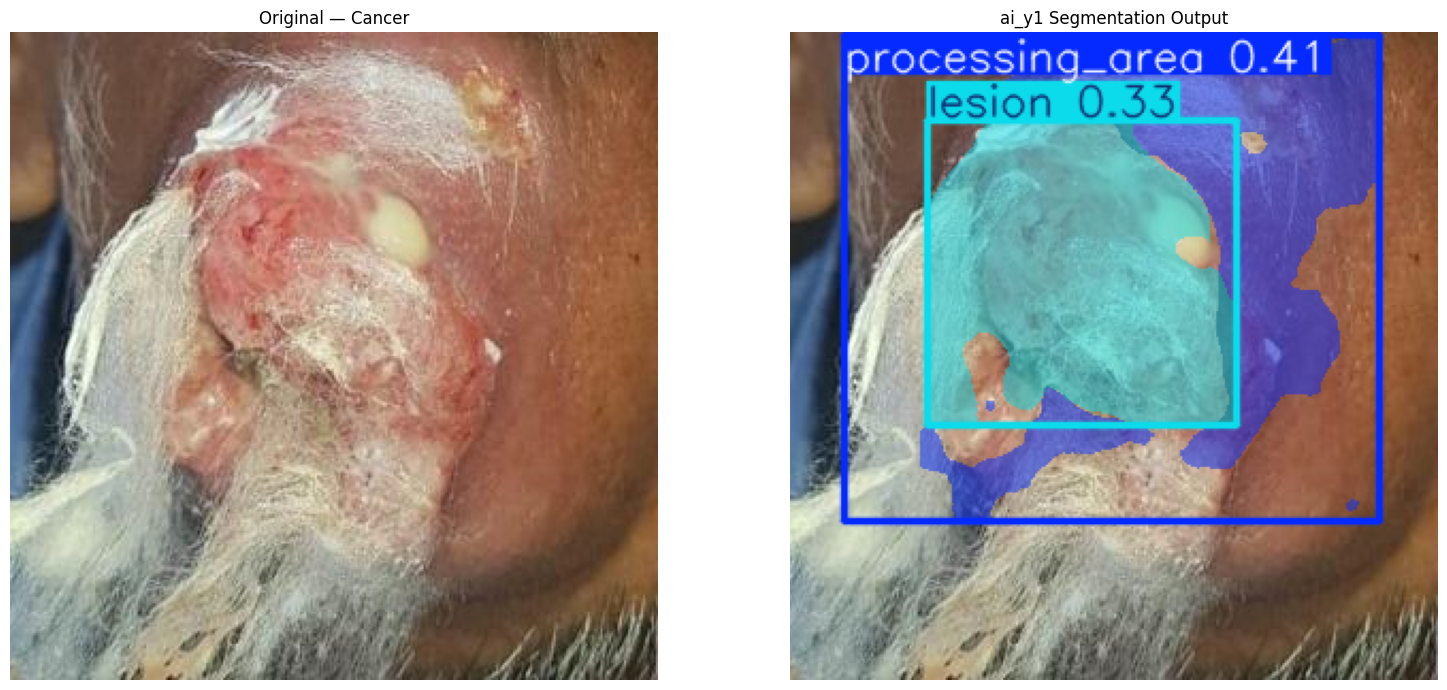

In [ ]:
# ============================================================
# CELL 4: TEST AI_Y1 ON ONE SAMPLE IMAGE
# ============================================================

from PIL import Image

# Har class se pehli valid image available hai.
sample_record = manifest_df.iloc[0]

sample_path = Path(sample_record["source_path"])
sample_class = sample_record["class_name"]

print("Sample image :", sample_path)
print("True class   :", sample_class)

results = yolo_model.predict(
    source=str(sample_path),
    imgsz=YOLO_IMAGE_SIZE,
    conf=YOLO_CONFIDENCE,
    device=0,
    retina_masks=True,
    verbose=False
)

result = results[0]

print("\nDetections found:", 0 if result.boxes is None else len(result.boxes))

if result.boxes is not None and len(result.boxes) > 0:

    detected_classes = result.boxes.cls.detach().cpu().numpy().astype(int)
    confidences = result.boxes.conf.detach().cpu().numpy()

    detection_rows = []

    for detection_index, (class_id, confidence) in enumerate(
        zip(detected_classes, confidences)
    ):
        detection_rows.append({
            "detection": detection_index + 1,
            "class_id": int(class_id),
            "class_name": yolo_names[int(class_id)],
            "confidence": round(float(confidence), 4),
        })

    display(pd.DataFrame(detection_rows))

else:
    print("No segmentation object detected.")


# Ultralytics annotated output
annotated_bgr = result.plot()
annotated_rgb = cv2.cvtColor(
    annotated_bgr,
    cv2.COLOR_BGR2RGB
)

original_bgr = cv2.imread(str(sample_path))
original_rgb = cv2.cvtColor(
    original_bgr,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(16, 7))

plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title(f"Original — {sample_class}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(annotated_rgb)
plt.title("ai_y1 Segmentation Output")
plt.axis("off")

plt.tight_layout()
plt.show()

# Leakage-safe train/valid/test split

In [ ]:
# ============================================================
# CELL 5: LEAKAGE-SAFE STRATIFIED TRAIN/VALID/TEST SPLIT
# ============================================================

# ============================================================
# CELL 5 — CORRECTED:
# LEAKAGE-SAFE SPLIT + CONFLICTING DUPLICATES EXCLUSION
# ============================================================

import hashlib
import json
from pathlib import Path

import pandas as pd
from sklearn.model_selection import train_test_split


# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

# True:
# Same image with multiple labels will be excluded automatically.
#
# Recommended for now because wrong labels should never enter
# medical classifier training.
EXCLUDE_CONFLICTING_IMAGES = True


# ------------------------------------------------------------
# HELPER: SHA-1 HASH
# ------------------------------------------------------------

def calculate_file_sha1(
    file_path: str | Path,
    chunk_size: int = 1024 * 1024
) -> str:
    """
    Calculate SHA-1 hash without loading entire image into RAM.
    Identical files will produce identical hashes.
    """

    sha1 = hashlib.sha1()

    with open(file_path, "rb") as file:

        while True:

            chunk = file.read(chunk_size)

            if not chunk:
                break

            sha1.update(chunk)

    return sha1.hexdigest()


# ------------------------------------------------------------
# 1. PREPARE WORKING MANIFEST
# ------------------------------------------------------------

if "manifest_df" not in globals():
    raise RuntimeError(
        "manifest_df memory mein nahi mila. "
        "Pehle Cell 3 run karein."
    )

split_df = manifest_df.copy().reset_index(drop=True)

required_columns = {
    "source_path",
    "class_name",
    "class_index"
}

missing_columns = required_columns - set(split_df.columns)

if missing_columns:
    raise ValueError(
        f"Manifest mein required columns missing hain: "
        f"{sorted(missing_columns)}"
    )


print("=" * 85)
print("CELL 5 — DUPLICATE AND LABEL-CONFLICT ANALYSIS")
print("=" * 85)
print("Initial records:", len(split_df))


# ------------------------------------------------------------
# 2. CALCULATE IMAGE HASHES
# ------------------------------------------------------------

print("\nCalculating SHA-1 hashes...")

split_df["sha1"] = [
    calculate_file_sha1(path)
    for path in split_df["source_path"]
]

print("Hash calculation complete.")
print("Total records :", len(split_df))
print("Unique images:", split_df["sha1"].nunique())


# ------------------------------------------------------------
# 3. FIND ALL EXACT DUPLICATES
# ------------------------------------------------------------

duplicate_mask = split_df.duplicated(
    subset=["sha1"],
    keep=False
)

all_duplicate_df = (
    split_df[duplicate_mask]
    .sort_values(
        ["sha1", "class_index", "source_path"]
    )
    .copy()
)

all_duplicates_report_path = (
    REPORT_DIR /
    "all_exact_duplicate_images.csv"
)

all_duplicate_df.to_csv(
    all_duplicates_report_path,
    index=False
)

print("\nDuplicate records     :", len(all_duplicate_df))
print(
    "Duplicate hash groups:",
    all_duplicate_df["sha1"].nunique()
)


# ------------------------------------------------------------
# 4. DETECT LABEL-CONFLICTING HASHES
# ------------------------------------------------------------

# For every identical image, count how many different class labels it has.
hash_class_counts = (
    split_df
    .groupby("sha1")["class_index"]
    .nunique()
)

conflicting_hashes = set(
    hash_class_counts[
        hash_class_counts > 1
    ].index
)

conflict_df = (
    split_df[
        split_df["sha1"].isin(conflicting_hashes)
    ]
    .sort_values(
        ["sha1", "class_index", "source_path"]
    )
    .copy()
)

conflict_report_path = (
    REPORT_DIR /
    "duplicate_images_with_class_conflicts.csv"
)

conflict_df.to_csv(
    conflict_report_path,
    index=False
)


print("\n" + "-" * 85)
print("CONFLICT SUMMARY")
print("-" * 85)
print("Conflicting hash groups :", len(conflicting_hashes))
print("Conflicting image rows  :", len(conflict_df))
print("Conflict report         :", conflict_report_path)


# ------------------------------------------------------------
# 5. SHOW CONFLICT SUMMARY IN NOTEBOOK
# ------------------------------------------------------------

if not conflict_df.empty:

    conflict_summary = (
        conflict_df
        .groupby("sha1")
        .agg(
            number_of_rows=(
                "source_path",
                "count"
            ),
            number_of_classes=(
                "class_index",
                "nunique"
            ),
            class_names=(
                "class_name",
                lambda values: " | ".join(
                    sorted(set(map(str, values)))
                )
            ),
            file_paths=(
                "source_path",
                lambda values: "\n".join(
                    map(str, values)
                )
            )
        )
        .reset_index()
    )

    conflict_summary_path = (
        REPORT_DIR /
        "duplicate_conflict_summary.csv"
    )

    conflict_summary.to_csv(
        conflict_summary_path,
        index=False
    )

    display(
        conflict_summary[
            [
                "sha1",
                "number_of_rows",
                "number_of_classes",
                "class_names"
            ]
        ].head(30)
    )

    print(
        "\nDetailed conflict summary:",
        conflict_summary_path
    )

else:

    print("No cross-class duplicate conflicts found.")


# ------------------------------------------------------------
# 6. REMOVE CONFLICTING IMAGES
# ------------------------------------------------------------

if conflicting_hashes:

    if not EXCLUDE_CONFLICTING_IMAGES:

        raise ValueError(
            "\nCross-class duplicate conflicts mile hain.\n"
            "Manual review ke baad labels correct karein, "
            "ya EXCLUDE_CONFLICTING_IMAGES=True rakhein.\n\n"
            f"Report:\n{conflict_report_path}"
        )

    before_conflict_removal = len(split_df)

    clean_df = (
        split_df[
            ~split_df["sha1"].isin(
                conflicting_hashes
            )
        ]
        .copy()
        .reset_index(drop=True)
    )

    removed_conflicting_rows = (
        before_conflict_removal -
        len(clean_df)
    )

else:

    clean_df = split_df.copy()
    removed_conflicting_rows = 0


print("\nConflicting rows excluded:", removed_conflicting_rows)
print("Rows after conflict removal:", len(clean_df))


# ------------------------------------------------------------
# 7. REMOVE SAFE SAME-CLASS DUPLICATES
# ------------------------------------------------------------

# At this point, remaining duplicates can only belong to same class.
# Keep one copy of each exact image.

before_deduplication = len(clean_df)

clean_df = (
    clean_df
    .sort_values(
        ["class_index", "source_path"]
    )
    .drop_duplicates(
        subset=["sha1"],
        keep="first"
    )
    .reset_index(drop=True)
)

removed_same_class_duplicates = (
    before_deduplication -
    len(clean_df)
)

print(
    "Same-class duplicate copies removed:",
    removed_same_class_duplicates
)

print(
    "Final unique clean images:",
    len(clean_df)
)


# ------------------------------------------------------------
# 8. VERIFY NO CONFLICT REMAINS
# ------------------------------------------------------------

remaining_class_counts = (
    clean_df
    .groupby("sha1")["class_index"]
    .nunique()
)

assert remaining_class_counts.max() == 1, (
    "Cross-class label conflict abhi bhi remaining hai."
)

assert clean_df["sha1"].is_unique, (
    "Exact duplicate image abhi bhi remaining hai."
)


# ------------------------------------------------------------
# 9. CHECK CLASS COUNTS BEFORE SPLIT
# ------------------------------------------------------------

clean_class_summary = (
    clean_df
    .groupby(
        ["class_index", "class_name"]
    )
    .size()
    .reset_index(name="clean_images")
    .sort_values("class_index")
)

print("\n" + "=" * 85)
print("CLEAN CLASS DISTRIBUTION BEFORE SPLITTING")
print("=" * 85)

display(clean_class_summary)


# Stratified split needs enough examples in each class.
minimum_class_count = int(
    clean_class_summary["clean_images"].min()
)

if minimum_class_count < 10:

    raise ValueError(
        "Conflict removal ke baad kisi class mein 10 se kam "
        "images remaining hain. Stratified split safe nahi hoga."
    )


# ------------------------------------------------------------
# 10. STRATIFIED TRAIN / VALID / TEST SPLIT
# ------------------------------------------------------------

train_df, temporary_df = train_test_split(
    clean_df,
    test_size=(VALID_RATIO + TEST_RATIO),
    stratify=clean_df["class_index"],
    random_state=SEED,
    shuffle=True
)

relative_test_ratio = (
    TEST_RATIO /
    (VALID_RATIO + TEST_RATIO)
)

valid_df, test_df = train_test_split(
    temporary_df,
    test_size=relative_test_ratio,
    stratify=temporary_df["class_index"],
    random_state=SEED,
    shuffle=True
)


train_df = train_df.copy()
valid_df = valid_df.copy()
test_df = test_df.copy()

train_df["split"] = "train"
valid_df["split"] = "valid"
test_df["split"] = "test"


final_manifest_df = pd.concat(
    [
        train_df,
        valid_df,
        test_df
    ],
    ignore_index=True
)

final_manifest_df = (
    final_manifest_df
    .sample(
        frac=1,
        random_state=SEED
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 11. VERIFY ZERO SPLIT LEAKAGE
# ------------------------------------------------------------

train_hashes = set(train_df["sha1"])
valid_hashes = set(valid_df["sha1"])
test_hashes = set(test_df["sha1"])

assert train_hashes.isdisjoint(valid_hashes), (
    "Train/validation leakage detected."
)

assert train_hashes.isdisjoint(test_hashes), (
    "Train/test leakage detected."
)

assert valid_hashes.isdisjoint(test_hashes), (
    "Validation/test leakage detected."
)


# ------------------------------------------------------------
# 12. FINAL SPLIT DISTRIBUTION
# ------------------------------------------------------------

split_summary = pd.crosstab(
    final_manifest_df["class_name"],
    final_manifest_df["split"]
)

split_summary = split_summary.reindex(
    index=CLASS_NAMES,
    columns=[
        "train",
        "valid",
        "test"
    ],
    fill_value=0
)

split_summary["total"] = (
    split_summary[
        ["train", "valid", "test"]
    ].sum(axis=1)
)

print("\n" + "=" * 85)
print("FINAL LEAKAGE-SAFE SPLIT")
print("=" * 85)

display(split_summary)

print("\nTotal per split:")

display(
    final_manifest_df[
        "split"
    ]
    .value_counts()
    .rename_axis("split")
    .reset_index(name="images")
)


# ------------------------------------------------------------
# 13. SAVE REPORTS AND MANIFEST
# ------------------------------------------------------------

split_manifest_path = (
    REPORT_DIR /
    "classifier_split_manifest.csv"
)

clean_manifest_path = (
    REPORT_DIR /
    "classifier_clean_unique_manifest.csv"
)

excluded_manifest_path = (
    REPORT_DIR /
    "classifier_excluded_conflicting_images.csv"
)

summary_json_path = (
    REPORT_DIR /
    "duplicate_cleaning_summary.json"
)


final_manifest_df.to_csv(
    split_manifest_path,
    index=False
)

clean_df.to_csv(
    clean_manifest_path,
    index=False
)

conflict_df.to_csv(
    excluded_manifest_path,
    index=False
)


cleaning_summary = {
    "initial_records": int(len(split_df)),
    "initial_unique_hashes": int(
        split_df["sha1"].nunique()
    ),
    "conflicting_hash_groups": int(
        len(conflicting_hashes)
    ),
    "conflicting_rows_excluded": int(
        removed_conflicting_rows
    ),
    "same_class_duplicate_copies_removed": int(
        removed_same_class_duplicates
    ),
    "final_unique_clean_images": int(
        len(clean_df)
    ),
    "train_images": int(len(train_df)),
    "valid_images": int(len(valid_df)),
    "test_images": int(len(test_df)),
    "class_distribution": {
        class_name: {
            "train": int(
                (
                    (final_manifest_df["class_name"] == class_name)
                    &
                    (final_manifest_df["split"] == "train")
                ).sum()
            ),
            "valid": int(
                (
                    (final_manifest_df["class_name"] == class_name)
                    &
                    (final_manifest_df["split"] == "valid")
                ).sum()
            ),
            "test": int(
                (
                    (final_manifest_df["class_name"] == class_name)
                    &
                    (final_manifest_df["split"] == "test")
                ).sum()
            )
        }
        for class_name in CLASS_NAMES
    }
}

with open(
    summary_json_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        cleaning_summary,
        file,
        indent=4
    )


print("\n" + "=" * 85)
print("CELL 5 COMPLETED SUCCESSFULLY")
print("=" * 85)
print("✓ Conflicting-label images excluded")
print("✓ Same-class duplicate copies removed")
print("✓ No exact duplicate remains")
print("✓ No split leakage remains")
print("✓ Stratified split generated")
print()
print("Final split manifest :", split_manifest_path)
print("Clean manifest       :", clean_manifest_path)
print("Excluded conflicts   :", excluded_manifest_path)
print("Cleaning summary     :", summary_json_path)
print("=" * 85)

CELL 5 — DUPLICATE AND LABEL-CONFLICT ANALYSIS
Initial records: 3692

Calculating SHA-1 hashes...
Hash calculation complete.
Total records : 3692
Unique images: 3516

Duplicate records     : 342
Duplicate hash groups: 166

-------------------------------------------------------------------------------------
CONFLICT SUMMARY
-------------------------------------------------------------------------------------
Conflicting hash groups : 145
Conflicting image rows  : 298
Conflict report         : /content/drive/MyDrive/OralScan_AI/classifier_training/reports/duplicate_images_with_class_conflicts.csv


,sha1,number_of_rows,number_of_classes,class_names
0,0284372cfa1375445401c60b45125d0a22a6f179,2,2,Cancer | Leukoplakia
1,03201f47b832aa390c5cf414810cba3b4a1691cc,2,2,Cancer | Leukoplakia-like Conditions
2,04bd32be10eaffe477d3237fc88e2ba173aeda3d,2,2,Cancer | Leukoplakia-like Conditions
3,061d3d61cd6cbf827ed2b397d8cbb6d17613ce82,2,2,Cancer | Leukoplakia-like Conditions
4,06aad81177d7bafd1fba576c4d0d40ae960030d4,2,2,Cancer | Leukoplakia-like Conditions
5,070dcbd42967c8e5e7396a2195c8ff50d6eb65ad,2,2,Cancer | Leukoplakia
6,092c8ace65edf93f271d45ad1ee029e8e0e653a3,2,2,Cancer | Leukoplakia
7,0b094569b3319252c0d44b2b57bcc5ece20d4b44,2,2,Cancer | Leukoplakia-like Conditions
8,0e07c9bccadc0059605974918fbcef1fde929926,2,2,Cancer | Leukoplakia
9,144dea864b9d967af2401f14f48cb5030578f129,2,2,Cancer | Leukoplakia



Detailed conflict summary: /content/drive/MyDrive/OralScan_AI/classifier_training/reports/duplicate_conflict_summary.csv

Conflicting rows excluded: 298
Rows after conflict removal: 3394
Same-class duplicate copies removed: 23
Final unique clean images: 3371

CLEAN CLASS DISTRIBUTION BEFORE SPLITTING


,class_index,class_name,clean_images
0,0,Cancer,1602
1,1,Leukoplakia,254
2,2,Leukoplakia-like Conditions,148
3,3,Normal Buccal Mucosa,1367



FINAL LEAKAGE-SAFE SPLIT


split,train,valid,test,total
class_name,,,,
Cancer,1121,240,241,1602
Leukoplakia,178,38,38,254
Leukoplakia-like Conditions,103,23,22,148
Normal Buccal Mucosa,957,205,205,1367



Total per split:


,split,images
0,train,2359
1,test,506
2,valid,506



CELL 5 COMPLETED SUCCESSFULLY
✓ Conflicting-label images excluded
✓ Same-class duplicate copies removed
✓ No exact duplicate remains
✓ No split leakage remains
✓ Stratified split generated

Final split manifest : /content/drive/MyDrive/OralScan_AI/classifier_training/reports/classifier_split_manifest.csv
Clean manifest       : /content/drive/MyDrive/OralScan_AI/classifier_training/reports/classifier_clean_unique_manifest.csv
Excluded conflicts   : /content/drive/MyDrive/OralScan_AI/classifier_training/reports/classifier_excluded_conflicting_images.csv
Cleaning summary     : /content/drive/MyDrive/OralScan_AI/classifier_training/reports/duplicate_cleaning_summary.json


# ai_y1.pt se processing-area ROI banana

In [ ]:
# ============================================================
# CELL 6: GENERATE CLASSIFIER ROI DATASET USING AI_Y1
# ============================================================

from tqdm.auto import tqdm
from collections import defaultdict


# ------------------------------------------------------------
# ROI SETTINGS
# ------------------------------------------------------------

# True:
# Processing-area detection fail hone par original image use hogi.
#
# False:
# Detection fail image classifier dataset se exclude hogi.
USE_FULL_IMAGE_FALLBACK = True

# Outside processing mask pixels ko background se replace karna.
# False = rectangular ROI crop; surrounding context retained.
# True  = exact processing-area mask; external background removed.
USE_MASKED_ROI = False

MIN_ROI_WIDTH = 32
MIN_ROI_HEIGHT = 32
MIN_ROI_AREA_RATIO = 0.02

JPEG_QUALITY = 95


# ------------------------------------------------------------
# OUTPUT DIRECTORY CREATION
# ------------------------------------------------------------

if PROCESSED_DATASET_DIR.exists():
    print(
        "Existing processed dataset found:",
        PROCESSED_DATASET_DIR
    )
    print("It will be recreated.")

    shutil.rmtree(PROCESSED_DATASET_DIR)

for split_name in ["train", "valid", "test"]:
    for class_name in CLASS_NAMES:

        safe_class_name = normalize_name(class_name)

        output_folder = (
            PROCESSED_DATASET_DIR /
            split_name /
            safe_class_name
        )

        output_folder.mkdir(
            parents=True,
            exist_ok=True
        )


# ------------------------------------------------------------
# HELPER FUNCTIONS
# ------------------------------------------------------------

def clamp(
    value: int,
    minimum: int,
    maximum: int
) -> int:
    return max(minimum, min(value, maximum))


def mask_to_bounding_box(
    binary_mask: np.ndarray
):
    """Return x1, y1, x2, y2 around non-zero mask pixels."""

    y_coordinates, x_coordinates = np.where(
        binary_mask > 0
    )

    if len(x_coordinates) == 0:
        return None

    x1 = int(x_coordinates.min())
    y1 = int(y_coordinates.min())
    x2 = int(x_coordinates.max()) + 1
    y2 = int(y_coordinates.max()) + 1

    return x1, y1, x2, y2


def add_bbox_padding(
    bbox,
    image_width: int,
    image_height: int,
    padding_ratio: float
):
    """Add proportional padding while staying inside image."""

    x1, y1, x2, y2 = bbox

    box_width = x2 - x1
    box_height = y2 - y1

    padding_x = int(round(box_width * padding_ratio))
    padding_y = int(round(box_height * padding_ratio))

    x1 = clamp(x1 - padding_x, 0, image_width)
    y1 = clamp(y1 - padding_y, 0, image_height)
    x2 = clamp(x2 + padding_x, 0, image_width)
    y2 = clamp(y2 + padding_y, 0, image_height)

    return x1, y1, x2, y2


def choose_best_segmentation_index(
    result,
    target_class_id: int
):
    """
    Select target-class detection using confidence × relative mask area.
    This avoids selecting a small false-positive solely by confidence.
    """

    if (
        result.boxes is None
        or result.masks is None
        or len(result.boxes) == 0
    ):
        return None

    class_ids = (
        result.boxes.cls
        .detach()
        .cpu()
        .numpy()
        .astype(int)
    )

    confidences = (
        result.boxes.conf
        .detach()
        .cpu()
        .numpy()
    )

    masks = (
        result.masks.data
        .detach()
        .cpu()
        .numpy()
    )

    candidates = []

    for detection_index, class_id in enumerate(class_ids):

        if int(class_id) != int(target_class_id):
            continue

        mask_area_ratio = float(
            (masks[detection_index] > 0.5).mean()
        )

        confidence = float(
            confidences[detection_index]
        )

        selection_score = (
            confidence *
            np.sqrt(max(mask_area_ratio, 1e-8))
        )

        candidates.append({
            "index": detection_index,
            "confidence": confidence,
            "mask_area_ratio": mask_area_ratio,
            "selection_score": selection_score,
        })

    if not candidates:
        return None

    candidates.sort(
        key=lambda item: item["selection_score"],
        reverse=True
    )

    return candidates[0]


def resize_binary_mask(
    mask: np.ndarray,
    target_width: int,
    target_height: int
):
    resized = cv2.resize(
        mask.astype(np.uint8),
        (target_width, target_height),
        interpolation=cv2.INTER_NEAREST
    )

    return (resized > 0).astype(np.uint8)


def create_processing_roi(
    image_bgr: np.ndarray,
    binary_mask: np.ndarray,
    padding_ratio: float,
    use_masked_roi: bool
):
    """
    Crop processing-area ROI.

    If use_masked_roi=True, pixels outside mask are replaced with
    median color rather than pure black to reduce boundary artifacts.
    """

    image_height, image_width = image_bgr.shape[:2]

    bbox = mask_to_bounding_box(binary_mask)

    if bbox is None:
        return None

    x1, y1, x2, y2 = add_bbox_padding(
        bbox=bbox,
        image_width=image_width,
        image_height=image_height,
        padding_ratio=padding_ratio
    )

    if (
        (x2 - x1) < MIN_ROI_WIDTH
        or (y2 - y1) < MIN_ROI_HEIGHT
    ):
        return None

    roi_image = image_bgr[y1:y2, x1:x2].copy()
    roi_mask = binary_mask[y1:y2, x1:x2].copy()

    if use_masked_roi:

        inside_pixels = roi_image[
            roi_mask.astype(bool)
        ]

        if len(inside_pixels) > 0:
            background_color = np.median(
                inside_pixels,
                axis=0
            ).astype(np.uint8)
        else:
            background_color = np.array(
                [0, 0, 0],
                dtype=np.uint8
            )

        masked_roi = np.full_like(
            roi_image,
            background_color
        )

        masked_roi[
            roi_mask.astype(bool)
        ] = roi_image[
            roi_mask.astype(bool)
        ]

        roi_image = masked_roi

    return {
        "roi_image": roi_image,
        "roi_mask": roi_mask,
        "bbox": [x1, y1, x2, y2],
    }


# ------------------------------------------------------------
# RUN YOLO ROI EXTRACTION
# ------------------------------------------------------------

roi_records = []
failed_records = []

print("=" * 80)
print("GENERATING PROCESSING-AREA ROI DATASET")
print("=" * 80)
print("Images:", len(final_manifest_df))
print("YOLO model:", YOLO_MODEL_PATH)
print("Processing-area class ID:", PROCESSING_AREA_CLASS_ID)
print("Lesion class ID:", LESION_CLASS_ID)
print("Fallback enabled:", USE_FULL_IMAGE_FALLBACK)
print("=" * 80)


for row_index, row in tqdm(
    final_manifest_df.iterrows(),
    total=len(final_manifest_df),
    desc="Extracting ROIs"
):

    source_path = Path(row["source_path"])
    split_name = str(row["split"])
    class_name = str(row["class_name"])
    class_index = int(row["class_index"])
    image_hash = str(row["sha1"])

    image_bgr = cv2.imread(str(source_path))

    if image_bgr is None:

        failed_records.append({
            "source_path": str(source_path),
            "reason": "OpenCV failed to read image",
            "split": split_name,
            "class_name": class_name,
        })

        continue

    image_height, image_width = image_bgr.shape[:2]

    try:
        prediction = yolo_model.predict(
            source=image_bgr,
            imgsz=YOLO_IMAGE_SIZE,
            conf=YOLO_CONFIDENCE,
            device=0,
            retina_masks=True,
            verbose=False
        )[0]

    except Exception as error:

        failed_records.append({
            "source_path": str(source_path),
            "reason": f"YOLO inference error: {error}",
            "split": split_name,
            "class_name": class_name,
        })

        continue

    processing_candidate = choose_best_segmentation_index(
        result=prediction,
        target_class_id=PROCESSING_AREA_CLASS_ID
    )

    lesion_candidate = None

    if LESION_CLASS_ID is not None:
        lesion_candidate = choose_best_segmentation_index(
            result=prediction,
            target_class_id=LESION_CLASS_ID
        )

    roi_source = "processing_area_mask"
    processing_confidence = np.nan
    processing_mask_area_ratio = np.nan
    processing_bbox = None

    lesion_detected = lesion_candidate is not None
    lesion_confidence = (
        float(lesion_candidate["confidence"])
        if lesion_candidate is not None
        else np.nan
    )
    lesion_mask_area_ratio = (
        float(lesion_candidate["mask_area_ratio"])
        if lesion_candidate is not None
        else np.nan
    )

    roi_image = None

    if processing_candidate is not None:

        mask_index = int(
            processing_candidate["index"]
        )

        raw_mask = (
            prediction.masks.data[mask_index]
            .detach()
            .cpu()
            .numpy()
        )

        binary_mask = resize_binary_mask(
            mask=(raw_mask > 0.5),
            target_width=image_width,
            target_height=image_height
        )

        processing_mask_area_ratio = float(
            binary_mask.mean()
        )

        processing_confidence = float(
            processing_candidate["confidence"]
        )

        if (
            processing_mask_area_ratio
            >= MIN_ROI_AREA_RATIO
        ):

            roi_result = create_processing_roi(
                image_bgr=image_bgr,
                binary_mask=binary_mask,
                padding_ratio=ROI_PADDING_RATIO,
                use_masked_roi=USE_MASKED_ROI
            )

            if roi_result is not None:
                roi_image = roi_result["roi_image"]
                processing_bbox = roi_result["bbox"]

    # Controlled fallback
    if roi_image is None:

        if USE_FULL_IMAGE_FALLBACK:
            roi_image = image_bgr.copy()
            roi_source = "full_image_fallback"
            processing_bbox = [
                0,
                0,
                image_width,
                image_height
            ]

        else:
            failed_records.append({
                "source_path": str(source_path),
                "reason": "No valid processing-area ROI",
                "split": split_name,
                "class_name": class_name,
            })

            continue

    safe_class_name = normalize_name(class_name)

    output_filename = (
        f"{class_index}_"
        f"{image_hash[:12]}_"
        f"{row_index:06d}.jpg"
    )

    output_path = (
        PROCESSED_DATASET_DIR /
        split_name /
        safe_class_name /
        output_filename
    )

    save_success = cv2.imwrite(
        str(output_path),
        roi_image,
        [
            int(cv2.IMWRITE_JPEG_QUALITY),
            JPEG_QUALITY
        ]
    )

    if not save_success:

        failed_records.append({
            "source_path": str(source_path),
            "reason": "cv2.imwrite failed",
            "split": split_name,
            "class_name": class_name,
        })

        continue

    roi_height, roi_width = roi_image.shape[:2]

    roi_records.append({
        "source_path": str(source_path),
        "roi_path": str(output_path),
        "split": split_name,
        "class_name": class_name,
        "class_index": class_index,
        "sha1": image_hash,
        "roi_source": roi_source,
        "original_width": image_width,
        "original_height": image_height,
        "roi_width": roi_width,
        "roi_height": roi_height,
        "processing_confidence": processing_confidence,
        "processing_mask_area_ratio":
            processing_mask_area_ratio,
        "processing_bbox": json.dumps(
            processing_bbox
        ),
        "lesion_detected": lesion_detected,
        "lesion_confidence": lesion_confidence,
        "lesion_mask_area_ratio":
            lesion_mask_area_ratio,
    })


# ------------------------------------------------------------
# SAVE ROI MANIFEST AND FAILURES
# ------------------------------------------------------------

roi_manifest_df = pd.DataFrame(roi_records)

roi_manifest_path = (
    REPORT_DIR /
    "classifier_roi_manifest.csv"
)

roi_manifest_df.to_csv(
    roi_manifest_path,
    index=False
)

failure_report_path = (
    REPORT_DIR /
    "roi_extraction_failures.csv"
)

pd.DataFrame(failed_records).to_csv(
    failure_report_path,
    index=False
)


# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("ROI EXTRACTION COMPLETE")
print("=" * 80)
print("Successful ROI images :", len(roi_manifest_df))
print("Failed images         :", len(failed_records))
print("ROI manifest          :", roi_manifest_path)
print("Failure report        :", failure_report_path)

if len(roi_manifest_df) > 0:

    print("\nROI source distribution:")
    display(
        pd.crosstab(
            roi_manifest_df["class_name"],
            roi_manifest_df["roi_source"]
        ).reindex(CLASS_NAMES, fill_value=0)
    )

    fallback_percentage = (
        100 *
        (
            roi_manifest_df["roi_source"]
            == "full_image_fallback"
        ).mean()
    )

    print(
        f"Full-image fallback percentage: "
        f"{fallback_percentage:.2f}%"
    )

    if fallback_percentage > 10:
        print(
            "\nWARNING: More than 10% images used fallback. "
            "ai_y1 processing-area predictions ko manually "
            "inspect karna recommended hai."
        )

GENERATING PROCESSING-AREA ROI DATASET
Images: 3371
YOLO model: /content/ai_y1.pt
Processing-area class ID: 0
Lesion class ID: 1
Fallback enabled: True


Extracting ROIs:   0%|          | 0/3371 [00:00<?, ?it/s]


ROI EXTRACTION COMPLETE
Successful ROI images : 3371
Failed images         : 0
ROI manifest          : /content/drive/MyDrive/OralScan_AI/classifier_training/reports/classifier_roi_manifest.csv
Failure report        : /content/drive/MyDrive/OralScan_AI/classifier_training/reports/roi_extraction_failures.csv

ROI source distribution:


roi_source,full_image_fallback,processing_area_mask
class_name,,
Cancer,57,1545
Leukoplakia,11,243
Leukoplakia-like Conditions,1,147
Normal Buccal Mucosa,5,1362


Full-image fallback percentage: 2.20%


In [ ]:
# ============================================================
# CELL 6 FIX: SAFE OUTPUT DIRECTORY CREATION
# ============================================================

from pathlib import Path
import shutil
import os

# IMPORTANT:
# PROCESSED_DATASET_DIR ko .zip file par point nahi karna chahiye.
# Yeh classifier ROI images save karne wala OUTPUT FOLDER hoga.

PROCESSED_DATASET_DIR = Path(
    "/content/oralscan_classifier_dataset"
)

print("Processed dataset output:", PROCESSED_DATASET_DIR)

# ------------------------------------------------------------
# SAFELY REMOVE OLD OUTPUT
# ------------------------------------------------------------

if PROCESSED_DATASET_DIR.exists():

    if PROCESSED_DATASET_DIR.is_dir():
        print("Existing processed dataset directory found.")
        print("It will be recreated.")

        shutil.rmtree(PROCESSED_DATASET_DIR)

    elif PROCESSED_DATASET_DIR.is_file():
        raise ValueError(
            f"\nPROCESSED_DATASET_DIR ek file hai, folder nahi:\n"
            f"{PROCESSED_DATASET_DIR}\n\n"
            "Is variable ko kisi folder path par set karein, "
            "jaise:\n/content/oralscan_classifier_dataset"
        )

# ------------------------------------------------------------
# CREATE SPLIT/CLASS FOLDERS
# ------------------------------------------------------------

for split_name in ["train", "valid", "test"]:

    for class_name in CLASS_NAMES:

        safe_class_name = normalize_name(class_name)

        output_folder = (
            PROCESSED_DATASET_DIR
            / split_name
            / safe_class_name
        )

        output_folder.mkdir(
            parents=True,
            exist_ok=True
        )

print("\n✓ Processed dataset folders created successfully.")

for split_name in ["train", "valid", "test"]:
    print(
        split_name,
        "→",
        PROCESSED_DATASET_DIR / split_name
    )

Processed dataset output: /content/oralscan_classifier_dataset
Existing processed dataset directory found.
It will be recreated.

✓ Processed dataset folders created successfully.
train → /content/oralscan_classifier_dataset/train
valid → /content/oralscan_classifier_dataset/valid
test → /content/oralscan_classifier_dataset/test


In [ ]:
print("ROI manifest rows :", len(roi_manifest_df))

print("\nFirst 5 ROI paths:")
for p in roi_manifest_df["roi_path"].head():
    print(p, "-> EXISTS:", Path(p).exists())

print("\nProcessed dataset root:")
print(PROCESSED_DATASET_DIR)
print("Root exists:", Path(PROCESSED_DATASET_DIR).exists())

ROI manifest rows : 3371

First 5 ROI paths:
/content/oralscan_classifier_dataset/test/cancer/0_c925eee1af7f_000000.jpg -> EXISTS: False
/content/oralscan_classifier_dataset/train/normal_buccal_mucosa/3_74814f4b243c_000001.jpg -> EXISTS: False
/content/oralscan_classifier_dataset/valid/leukoplakia_like_conditions/2_e66329232889_000002.jpg -> EXISTS: False
/content/oralscan_classifier_dataset/train/leukoplakia/1_ccf4596c3c28_000003.jpg -> EXISTS: False
/content/oralscan_classifier_dataset/train/normal_buccal_mucosa/3_79b20d5ddbd3_000004.jpg -> EXISTS: False

Processed dataset root:
/content/oralscan_classifier_dataset
Root exists: True


# Processed dataset verification and visualization

In [ ]:
# ============================================================
# CELL 7 — ROBUST VERIFY + VISUALIZE PROCESSED ROI DATASET
# ============================================================

from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# BASIC CHECKS
# ------------------------------------------------------------

required_columns = {
    "roi_path",
    "class_name",
    "class_index",
    "split",
    "sha1",
    "roi_source"
}

missing_columns = (
    required_columns
    - set(roi_manifest_df.columns)
)

if missing_columns:
    raise ValueError(
        "roi_manifest_df mein required columns missing hain:\n"
        f"{sorted(missing_columns)}\n\n"
        "Cell 6 ko dobara run karein."
    )


print("=" * 90)
print("CELL 7 — PROCESSED ROI DATASET VERIFICATION")
print("=" * 90)

print("Manifest rows       :", len(roi_manifest_df))
print("Processed root      :", PROCESSED_DATASET_DIR)
print(
    "Processed root exists:",
    Path(PROCESSED_DATASET_DIR).exists()
)


# ------------------------------------------------------------
# VERIFY ONE ROI
# ------------------------------------------------------------

def verify_saved_roi(roi_path: str):
    """
    Returns:
        status
        width
        height
        message

    status:
        valid
        missing
        unreadable
        too_small
    """

    roi_path = Path(str(roi_path))

    # File does not exist.
    if not roi_path.exists():

        return (
            "missing",
            0,
            0,
            "file_not_found"
        )

    # File exists but cannot be decoded.
    image = cv2.imread(
        str(roi_path)
    )

    if image is None:

        return (
            "unreadable",
            0,
            0,
            "opencv_decode_failed"
        )

    height, width = (
        image.shape[:2]
    )

    if (
        width < MIN_ROI_WIDTH
        or height < MIN_ROI_HEIGHT
    ):

        return (
            "too_small",
            width,
            height,
            (
                f"ROI size {width}x{height} "
                f"is below minimum "
                f"{MIN_ROI_WIDTH}x{MIN_ROI_HEIGHT}"
            )
        )

    return (
        "valid",
        width,
        height,
        "ok"
    )


# ------------------------------------------------------------
# VERIFY ALL ROI PATHS
# ------------------------------------------------------------

print("\nChecking ROI files...")

verification_results = [
    verify_saved_roi(path)
    for path in roi_manifest_df[
        "roi_path"
    ].astype(str)
]

roi_manifest_df = (
    roi_manifest_df.copy()
)

roi_manifest_df[
    "verification_status"
] = [
    result[0]
    for result in verification_results
]

roi_manifest_df[
    "verified_width"
] = [
    result[1]
    for result in verification_results
]

roi_manifest_df[
    "verified_height"
] = [
    result[2]
    for result in verification_results
]

roi_manifest_df[
    "verification_message"
] = [
    result[3]
    for result in verification_results
]

roi_manifest_df[
    "roi_valid"
] = (
    roi_manifest_df[
        "verification_status"
    ]
    == "valid"
)


# ------------------------------------------------------------
# VERIFICATION SUMMARY
# ------------------------------------------------------------

verification_summary = (
    roi_manifest_df[
        "verification_status"
    ]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="count")
)

verification_summary[
    "percentage"
] = (
    verification_summary["count"]
    / len(roi_manifest_df)
    * 100
).round(2)

print("\n" + "=" * 90)
print("ROI VERIFICATION SUMMARY")
print("=" * 90)

display(
    verification_summary
)


valid_count = int(
    roi_manifest_df[
        "roi_valid"
    ].sum()
)

missing_count = int(
    (
        roi_manifest_df[
            "verification_status"
        ]
        == "missing"
    ).sum()
)

unreadable_count = int(
    (
        roi_manifest_df[
            "verification_status"
        ]
        == "unreadable"
    ).sum()
)

too_small_count = int(
    (
        roi_manifest_df[
            "verification_status"
        ]
        == "too_small"
    ).sum()
)

total_count = len(
    roi_manifest_df
)

print(
    f"Valid      : {valid_count}/{total_count}"
)

print(
    f"Missing    : {missing_count}/{total_count}"
)

print(
    f"Unreadable : {unreadable_count}/{total_count}"
)

print(
    f"Too small  : {too_small_count}/{total_count}"
)


# ------------------------------------------------------------
# HANDLE MISSING DATASET PROPERLY
# ------------------------------------------------------------

if missing_count == total_count:

    first_old_path = (
        roi_manifest_df[
            "roi_path"
        ].iloc[0]
    )

    raise RuntimeError(
        "\n"
        "=" * 80 +
        "\nPROCESSED ROI DATASET CURRENT RUNTIME MEIN NAHI MILA\n"
        "=" * 80 +
        "\n\n"
        f"Manifest mein {total_count} ROI records hain,\n"
        f"lekin ALL {total_count} ROI files missing hain.\n\n"
        "Example missing path:\n"
        f"{first_old_path}\n\n"
        "Most likely reason:\n"
        "ROI dataset /content/... mein generate hua tha aur "
        "Colab runtime restart hone ke baad delete ho gaya.\n\n"
        "PERMANENT FIX:\n"
        "PROCESSED_DATASET_DIR ko Google Drive par set karein:\n\n"
        "PROCESSED_DATASET_DIR = Path(\n"
        '    "/content/drive/MyDrive/OralScan_AI/'
        'classifier_training/processed_roi_dataset"\n'
        ")\n\n"
        "Uske baad Cell 6 DOBARA run karein, "
        "phir Cell 7 run karein."
    )


# ------------------------------------------------------------
# SAVE PROBLEM REPORT
# ------------------------------------------------------------

invalid_saved_rois = (
    roi_manifest_df[
        ~roi_manifest_df[
            "roi_valid"
        ]
    ].copy()
)

if not invalid_saved_rois.empty:

    invalid_roi_path = (
        REPORT_DIR /
        "invalid_saved_roi_images.csv"
    )

    invalid_saved_rois.to_csv(
        invalid_roi_path,
        index=False
    )

    print(
        "\nProblem ROI report:",
        invalid_roi_path
    )

    print(
        "\nFirst problem records:"
    )

    display(
        invalid_saved_rois[
            [
                "class_name",
                "split",
                "roi_path",
                "verification_status",
                "verification_message"
            ]
        ].head(10)
    )


# ------------------------------------------------------------
# USE ONLY VALID ROIs
# ------------------------------------------------------------

verified_roi_manifest_df = (
    roi_manifest_df[
        roi_manifest_df[
            "roi_valid"
        ]
    ]
    .copy()
    .reset_index(drop=True)
)


if verified_roi_manifest_df.empty:

    raise RuntimeError(
        "Koi valid ROI available nahi hai. "
        "Cell 6 ko dobara run karein."
    )


# ------------------------------------------------------------
# VERIFY EVERY CLASS STILL EXISTS
# ------------------------------------------------------------

available_classes = set(
    verified_roi_manifest_df[
        "class_name"
    ].unique()
)

missing_classes = [
    class_name
    for class_name in CLASS_NAMES
    if class_name not in
    available_classes
]

if missing_classes:

    raise RuntimeError(
        "Valid processed dataset mein kuch classes "
        "completely missing hain:\n"
        f"{missing_classes}\n\n"
        "Classifier training continue mat karein."
    )


# ------------------------------------------------------------
# CLASS / SPLIT DISTRIBUTION
# ------------------------------------------------------------

processed_distribution = pd.crosstab(
    verified_roi_manifest_df[
        "class_name"
    ],
    verified_roi_manifest_df[
        "split"
    ]
)

processed_distribution = (
    processed_distribution
    .reindex(
        index=CLASS_NAMES,
        columns=[
            "train",
            "valid",
            "test"
        ],
        fill_value=0
    )
)

processed_distribution[
    "total"
] = (
    processed_distribution.sum(
        axis=1
    )
)

print("\n" + "=" * 90)
print("VALID PROCESSED ROI DISTRIBUTION")
print("=" * 90)

display(
    processed_distribution
)


# ------------------------------------------------------------
# VERIFY SPLIT LEAKAGE
# ------------------------------------------------------------

processed_train_hashes = set(
    verified_roi_manifest_df.loc[
        verified_roi_manifest_df[
            "split"
        ] == "train",
        "sha1"
    ]
)

processed_valid_hashes = set(
    verified_roi_manifest_df.loc[
        verified_roi_manifest_df[
            "split"
        ] == "valid",
        "sha1"
    ]
)

processed_test_hashes = set(
    verified_roi_manifest_df.loc[
        verified_roi_manifest_df[
            "split"
        ] == "test",
        "sha1"
    ]
)


train_valid_overlap = (
    processed_train_hashes
    & processed_valid_hashes
)

train_test_overlap = (
    processed_train_hashes
    & processed_test_hashes
)

valid_test_overlap = (
    processed_valid_hashes
    & processed_test_hashes
)


if (
    train_valid_overlap
    or train_test_overlap
    or valid_test_overlap
):

    raise RuntimeError(
        "DATA LEAKAGE DETECTED!\n"
        f"Train/Valid overlap: "
        f"{len(train_valid_overlap)}\n"
        f"Train/Test overlap : "
        f"{len(train_test_overlap)}\n"
        f"Valid/Test overlap : "
        f"{len(valid_test_overlap)}"
    )


print(
    "✓ No train/valid/test hash leakage"
)


# ------------------------------------------------------------
# FALLBACK RATE
# ------------------------------------------------------------

if (
    "roi_source"
    in verified_roi_manifest_df.columns
):

    fallback_count = int(
        (
            verified_roi_manifest_df[
                "roi_source"
            ]
            == "full_image_fallback"
        ).sum()
    )

    fallback_rate = (
        fallback_count
        / len(
            verified_roi_manifest_df
        )
        * 100
    )

    print(
        f"\nFull-image fallback: "
        f"{fallback_count}/"
        f"{len(verified_roi_manifest_df)} "
        f"({fallback_rate:.2f}%)"
    )

    if fallback_rate > 10:

        print(
            "⚠ WARNING: fallback >10%. "
            "ai_y1 processing-area detection "
            "review/retraining recommended."
        )


# ------------------------------------------------------------
# VISUALIZE SAMPLE ROIs
# ------------------------------------------------------------

samples_per_class = 3

sample_rows = []

for class_name in CLASS_NAMES:

    class_dataframe = (
        verified_roi_manifest_df[
            (
                verified_roi_manifest_df[
                    "class_name"
                ]
                == class_name
            )
            &
            (
                verified_roi_manifest_df[
                    "split"
                ]
                == "train"
            )
        ]
    )

    number_to_sample = min(
        samples_per_class,
        len(class_dataframe)
    )

    if number_to_sample == 0:
        continue

    class_samples = (
        class_dataframe.sample(
            n=number_to_sample,
            random_state=SEED
        )
    )

    sample_rows.append(
        class_samples
    )


if sample_rows:

    visualization_df = pd.concat(
        sample_rows,
        ignore_index=True
    )

    figure_rows = len(
        CLASS_NAMES
    )

    figure_columns = (
        samples_per_class
    )

    plt.figure(
        figsize=(
            5 * figure_columns,
            4 * figure_rows
        )
    )

    plot_index = 1

    for class_name in CLASS_NAMES:

        class_samples = (
            visualization_df[
                visualization_df[
                    "class_name"
                ]
                == class_name
            ]
        )

        for _, sample in (
            class_samples.iterrows()
        ):

            image_bgr = cv2.imread(
                sample["roi_path"]
            )

            if image_bgr is None:
                continue

            image_rgb = cv2.cvtColor(
                image_bgr,
                cv2.COLOR_BGR2RGB
            )

            plt.subplot(
                figure_rows,
                figure_columns,
                plot_index
            )

            plt.imshow(
                image_rgb
            )

            confidence = sample.get(
                "processing_confidence",
                np.nan
            )

            confidence_text = (
                f"{confidence:.3f}"
                if pd.notna(
                    confidence
                )
                else "fallback"
            )

            plt.title(
                f"{class_name}\n"
                f"ROI: "
                f"{sample['roi_source']}\n"
                f"YOLO conf: "
                f"{confidence_text}"
            )

            plt.axis(
                "off"
            )

            plot_index += 1

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# SAVE VERIFIED MANIFEST
# ------------------------------------------------------------

verified_manifest_path = (
    REPORT_DIR /
    "classifier_roi_manifest_verified.csv"
)

verified_roi_manifest_df.to_csv(
    verified_manifest_path,
    index=False
)

# Important:
# Following cells can continue to use roi_manifest_df.
roi_manifest_df = (
    verified_roi_manifest_df.copy()
)

print("\n" + "=" * 90)
print("CELL 7 COMPLETE")
print("=" * 90)

print(
    "Valid ROI images :",
    len(roi_manifest_df)
)

print(
    "Verified manifest:",
    verified_manifest_path
)

print(
    "✓ roi_manifest_df updated to contain only valid ROIs"
)

print("=" * 90)

# Dataset, augmentation and DataLoaders

In [ ]:
# ============================================================
# CELL 8: PYTORCH DATASET, AUGMENTATIONS AND DATALOADERS
# ============================================================

import albumentations as A

from albumentations.pytorch import ToTensorV2
from torch.utils.data import (
    Dataset,
    DataLoader,
    WeightedRandomSampler
)


# ------------------------------------------------------------
# IMAGENET NORMALIZATION
# ------------------------------------------------------------

IMAGENET_MEAN = (
    0.485,
    0.456,
    0.406
)

IMAGENET_STD = (
    0.229,
    0.224,
    0.225
)


# ------------------------------------------------------------
# SAFE MEDICAL IMAGE AUGMENTATIONS
# ------------------------------------------------------------

train_transform = A.Compose([
    A.Resize(
        height=IMAGE_SIZE,
        width=IMAGE_SIZE
    ),

    A.HorizontalFlip(
        p=0.50
    ),

    A.Affine(
        scale=(0.92, 1.08),
        translate_percent=(-0.04, 0.04),
        rotate=(-10, 10),
        shear=(-3, 3),
        border_mode=cv2.BORDER_REFLECT_101,
        p=0.65
    ),

    A.OneOf([
        A.RandomBrightnessContrast(
            brightness_limit=0.15,
            contrast_limit=0.15,
            p=1.0
        ),

        A.HueSaturationValue(
            hue_shift_limit=5,
            sat_shift_limit=10,
            val_shift_limit=10,
            p=1.0
        ),

        A.CLAHE(
            clip_limit=(1.0, 2.0),
            tile_grid_size=(8, 8),
            p=1.0
        ),
    ], p=0.45),

    A.CoarseDropout(
        num_holes_range=(1, 3),
        hole_height_range=(0.03, 0.08),
        hole_width_range=(0.03, 0.08),
        fill=0,
        p=0.15
    ),

    A.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    ),

    ToTensorV2()
])


evaluation_transform = A.Compose([
    A.Resize(
        height=IMAGE_SIZE,
        width=IMAGE_SIZE
    ),

    A.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    ),

    ToTensorV2()
])


# ------------------------------------------------------------
# CUSTOM DATASET
# ------------------------------------------------------------

class OralScanClassificationDataset(Dataset):

    def __init__(
        self,
        dataframe: pd.DataFrame,
        transform=None
    ):
        self.dataframe = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = str(row["roi_path"])
        label = int(row["class_index"])

        image_bgr = cv2.imread(image_path)

        if image_bgr is None:
            raise RuntimeError(
                f"Image read nahi hui: {image_path}"
            )

        image_rgb = cv2.cvtColor(
            image_bgr,
            cv2.COLOR_BGR2RGB
        )

        if self.transform is not None:
            transformed = self.transform(
                image=image_rgb
            )

            image_tensor = transformed["image"]

        else:
            image_tensor = torch.from_numpy(
                image_rgb
            ).permute(2, 0, 1).float() / 255.0

        return {
            "image": image_tensor,
            "label": torch.tensor(
                label,
                dtype=torch.long
            ),
            "image_path": image_path,
            "class_name": row["class_name"],
            "roi_source": row["roi_source"],
        }


# ------------------------------------------------------------
# SPLIT DATAFRAMES
# ------------------------------------------------------------

train_roi_df = (
    roi_manifest_df[
        roi_manifest_df["split"] == "train"
    ]
    .reset_index(drop=True)
)

valid_roi_df = (
    roi_manifest_df[
        roi_manifest_df["split"] == "valid"
    ]
    .reset_index(drop=True)
)

test_roi_df = (
    roi_manifest_df[
        roi_manifest_df["split"] == "test"
    ]
    .reset_index(drop=True)
)

assert len(train_roi_df) > 0
assert len(valid_roi_df) > 0
assert len(test_roi_df) > 0


# ------------------------------------------------------------
# DATASET OBJECTS
# ------------------------------------------------------------

train_dataset = OralScanClassificationDataset(
    dataframe=train_roi_df,
    transform=train_transform
)

valid_dataset = OralScanClassificationDataset(
    dataframe=valid_roi_df,
    transform=evaluation_transform
)

test_dataset = OralScanClassificationDataset(
    dataframe=test_roi_df,
    transform=evaluation_transform
)


# ------------------------------------------------------------
# CLASS WEIGHTS
# ------------------------------------------------------------

train_class_counts = (
    train_roi_df["class_index"]
    .value_counts()
    .sort_index()
    .reindex(
        range(NUM_CLASSES),
        fill_value=0
    )
)

if (train_class_counts == 0).any():
    raise ValueError(
        "Training split mein ek ya zyada classes empty hain."
    )

total_train_samples = int(
    train_class_counts.sum()
)

class_weights = (
    total_train_samples /
    (
        NUM_CLASSES *
        train_class_counts.values
    )
)

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32
)

class_weight_table = pd.DataFrame({
    "class_index": range(NUM_CLASSES),
    "class_name": CLASS_NAMES,
    "train_count": train_class_counts.values,
    "loss_weight": class_weights,
})

print("=" * 80)
print("TRAINING CLASS WEIGHTS")
print("=" * 80)

display(class_weight_table)


# ------------------------------------------------------------
# WEIGHTED RANDOM SAMPLER
# ------------------------------------------------------------

sample_weights = [
    class_weights[int(class_index)]
    for class_index in train_roi_df[
        "class_index"
    ].values
]

weighted_sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(
        sample_weights
    ),
    num_samples=len(sample_weights),
    replacement=True
)


# ------------------------------------------------------------
# DATALOADERS
# ------------------------------------------------------------

PIN_MEMORY = torch.cuda.is_available()

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    sampler=weighted_sampler,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0),
    drop_last=False
)

valid_loader = DataLoader(
    dataset=valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0),
    drop_last=False
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=(NUM_WORKERS > 0),
    drop_last=False
)


# ------------------------------------------------------------
# TEST ONE BATCH
# ------------------------------------------------------------

sample_batch = next(iter(train_loader))

images = sample_batch["image"]
labels = sample_batch["label"]

print("\n" + "=" * 80)
print("DATALOADER TEST")
print("=" * 80)
print("Training samples  :", len(train_dataset))
print("Validation samples:", len(valid_dataset))
print("Test samples      :", len(test_dataset))
print("Batch image shape :", tuple(images.shape))
print("Batch label shape :", tuple(labels.shape))
print("Batch labels      :", labels[:10].tolist())

assert images.ndim == 4
assert images.shape[1] == 3
assert images.shape[2] == IMAGE_SIZE
assert images.shape[3] == IMAGE_SIZE

print("\n✓ Dataset and DataLoaders are ready")

TRAINING CLASS WEIGHTS


,class_index,class_name,train_count,loss_weight
0,0,Cancer,1121,0.526093
1,1,Leukoplakia,178,3.313202
2,2,Leukoplakia-like Conditions,103,5.725728
3,3,Normal Buccal Mucosa,957,0.616249



DATALOADER TEST
Training samples  : 2359
Validation samples: 506
Test samples      : 506
Batch image shape : (32, 3, 300, 300)
Batch label shape : (32,)
Batch labels      : [1, 3, 3, 0, 1, 2, 0, 1, 0, 3]

✓ Dataset and DataLoaders are ready


# ai_c1 EfficientNetV2-B3 model

In [ ]:
# ============================================================
# CELL 9: INITIALIZE AI_C1 EFFICIENTNETV2-B3
# ============================================================

import torch.nn as nn
import timm


DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

AI_C1_MODEL_NAME = "tf_efficientnetv2_b3"

AI_C1_BEST_PATH = (
    MODEL_SAVE_DIR /
    "ai_c1_efficientnetv2_b3_best.pt"
)

AI_C1_LAST_PATH = (
    MODEL_SAVE_DIR /
    "ai_c1_efficientnetv2_b3_last.pt"
)


# ------------------------------------------------------------
# CREATE TRANSFER-LEARNING MODEL
# ------------------------------------------------------------

ai_c1_model = timm.create_model(
    AI_C1_MODEL_NAME,
    pretrained=True,
    num_classes=NUM_CLASSES,
    drop_rate=DROPOUT_RATE
)

ai_c1_model = ai_c1_model.to(DEVICE)


# ------------------------------------------------------------
# LOSS FUNCTION
# ------------------------------------------------------------

# Weighted Cross Entropy + Label Smoothing
criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor.to(DEVICE),
    label_smoothing=LABEL_SMOOTHING
)


# ------------------------------------------------------------
# OPTIMIZER
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    ai_c1_model.parameters(),
    lr=INITIAL_LR,
    weight_decay=WEIGHT_DECAY
)


# ------------------------------------------------------------
# COSINE SCHEDULER
# ------------------------------------------------------------

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=MAX_EPOCHS,
    eta_min=MIN_LR
)


# ------------------------------------------------------------
# MIXED PRECISION
# ------------------------------------------------------------

try:
    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=torch.cuda.is_available()
    )
except TypeError:
    scaler = torch.cuda.amp.GradScaler(
        enabled=torch.cuda.is_available()
    )


# ------------------------------------------------------------
# MODEL SUMMARY
# ------------------------------------------------------------

total_parameters = sum(
    parameter.numel()
    for parameter in ai_c1_model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in ai_c1_model.parameters()
    if parameter.requires_grad
)

print("=" * 80)
print("AI_C1 MODEL INITIALIZED")
print("=" * 80)
print("Model ID             : ai_c1")
print("Architecture         :", AI_C1_MODEL_NAME)
print("Input size           :", IMAGE_SIZE)
print("Number of classes    :", NUM_CLASSES)
print("Classes              :", CLASS_NAMES)
print("Device               :", DEVICE)
print("Total parameters     :", f"{total_parameters:,}")
print("Trainable parameters :", f"{trainable_parameters:,}")
print("Loss                 : Weighted CrossEntropy + Label Smoothing")
print("Optimizer            : AdamW")
print("Scheduler            : CosineAnnealingLR")
print("Mixed precision      :", torch.cuda.is_available())
print("Best model path      :", AI_C1_BEST_PATH)
print("=" * 80)


# ------------------------------------------------------------
# FORWARD-PASS TEST
# ------------------------------------------------------------

ai_c1_model.eval()

with torch.no_grad():

    test_input = torch.randn(
        2,
        3,
        IMAGE_SIZE,
        IMAGE_SIZE,
        device=DEVICE
    )

    test_output = ai_c1_model(test_input)

print("Test input shape :", tuple(test_input.shape))
print("Test output shape:", tuple(test_output.shape))

assert test_output.shape == (
    2,
    NUM_CLASSES
)

print("\n✓ ai_c1 forward-pass successful")
print("✓ Model training ke liye ready hai")

model.safetensors: reconstructing file:   0%|          |  0.00B / 57.9MB            

model.safetensors: downloading bytes:           |  0.00B            

AI_C1 MODEL INITIALIZED
Model ID             : ai_c1
Architecture         : tf_efficientnetv2_b3
Input size           : 300
Number of classes    : 4
Classes              : ['Cancer', 'Leukoplakia', 'Leukoplakia-like Conditions', 'Normal Buccal Mucosa']
Device               : cuda
Total parameters     : 12,827,554
Trainable parameters : 12,827,554
Loss                 : Weighted CrossEntropy + Label Smoothing
Optimizer            : AdamW
Scheduler            : CosineAnnealingLR
Mixed precision      : True
Best model path      : /content/drive/MyDrive/OralScan_AI/classifier_training/models/ai_c1_efficientnetv2_b3_best.pt
Test input shape : (2, 3, 300, 300)
Test output shape: (2, 4)

✓ ai_c1 forward-pass successful
✓ Model training ke liye ready hai


# Training engine, macro-F1 early stopping and checkpoints

In [ ]:
# ============================================================
# CELL 10: MIXED-PRECISION TRAINING ENGINE
# ============================================================

import os
import json
import time
import copy
import math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# ------------------------------------------------------------
# IMPORTANT:
# WeightedRandomSampler Cell 8 mein already active hai.
# Isliye yahan class weights dobara apply nahi kar rahe.
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss(
    label_smoothing=LABEL_SMOOTHING
)

AI_C1_HISTORY_PATH = REPORT_DIR / "ai_c1_training_history.csv"
AI_C1_SUMMARY_PATH = REPORT_DIR / "ai_c1_training_summary.json"

GRADIENT_CLIP_NORM = 1.0


def calculate_epoch_metrics(
    true_labels,
    predicted_labels,
    probabilities=None
):
    """
    Calculate research-level multiclass metrics.
    """

    accuracy = accuracy_score(
        true_labels,
        predicted_labels
    )

    precision_macro, recall_macro, f1_macro, _ = (
        precision_recall_fscore_support(
            true_labels,
            predicted_labels,
            average="macro",
            zero_division=0
        )
    )

    precision_weighted, recall_weighted, f1_weighted, _ = (
        precision_recall_fscore_support(
            true_labels,
            predicted_labels,
            average="weighted",
            zero_division=0
        )
    )

    roc_auc_macro = np.nan

    if probabilities is not None:
        try:
            roc_auc_macro = roc_auc_score(
                true_labels,
                probabilities,
                multi_class="ovr",
                average="macro",
                labels=list(range(NUM_CLASSES))
            )
        except ValueError:
            roc_auc_macro = np.nan

    return {
        "accuracy": float(accuracy),
        "precision_macro": float(precision_macro),
        "recall_macro": float(recall_macro),
        "f1_macro": float(f1_macro),
        "precision_weighted": float(precision_weighted),
        "recall_weighted": float(recall_weighted),
        "f1_weighted": float(f1_weighted),
        "roc_auc_macro": (
            float(roc_auc_macro)
            if not np.isnan(roc_auc_macro)
            else None
        )
    }


def run_one_epoch(
    model,
    data_loader,
    loss_function,
    device,
    optimizer=None,
    scaler=None,
    training=False
):
    """
    Run one complete train or validation epoch.
    """

    if training:
        model.train()
    else:
        model.eval()

    running_loss = 0.0
    all_true_labels = []
    all_predicted_labels = []
    all_probabilities = []

    progress_bar = tqdm(
        data_loader,
        desc="Training" if training else "Validation",
        leave=False
    )

    for batch in progress_bar:

        images = batch["image"].to(
            device,
            non_blocking=True
        )

        labels = batch["label"].to(
            device,
            non_blocking=True
        )

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=torch.cuda.is_available()
            ):

                logits = model(images)

                loss = loss_function(
                    logits,
                    labels
                )

            if training:

                scaler.scale(loss).backward()

                scaler.unscale_(optimizer)

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=GRADIENT_CLIP_NORM
                )

                scaler.step(optimizer)
                scaler.update()

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        batch_size = images.size(0)

        running_loss += (
            float(loss.item()) * batch_size
        )

        all_true_labels.extend(
            labels.detach().cpu().numpy().tolist()
        )

        all_predicted_labels.extend(
            predictions.detach().cpu().numpy().tolist()
        )

        all_probabilities.extend(
            probabilities.detach().cpu().numpy().tolist()
        )

        progress_bar.set_postfix({
            "loss": f"{loss.item():.4f}"
        })

    epoch_loss = (
        running_loss / len(data_loader.dataset)
    )

    metrics = calculate_epoch_metrics(
        true_labels=np.array(all_true_labels),
        predicted_labels=np.array(all_predicted_labels),
        probabilities=np.array(all_probabilities)
    )

    metrics["loss"] = float(epoch_loss)

    return metrics


def save_classifier_checkpoint(
    save_path,
    model,
    optimizer,
    scheduler,
    epoch,
    best_f1,
    history,
    model_name=AI_C1_MODEL_NAME
):
    """
    Save complete reproducible classifier checkpoint.
    """

    checkpoint = {
        "model_id": "ai_c1",
        "architecture": model_name,
        "epoch": int(epoch),
        "best_validation_macro_f1": float(best_f1),

        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),

        "class_names": CLASS_NAMES,
        "class_to_index": CLASS_TO_INDEX,
        "num_classes": NUM_CLASSES,

        "image_size": IMAGE_SIZE,
        "imagenet_mean": IMAGENET_MEAN,
        "imagenet_std": IMAGENET_STD,

        "dropout_rate": DROPOUT_RATE,
        "label_smoothing": LABEL_SMOOTHING,
        "learning_rate": INITIAL_LR,
        "weight_decay": WEIGHT_DECAY,

        "history": history
    }

    torch.save(
        checkpoint,
        str(save_path)
    )


def train_classifier(
    model,
    train_loader,
    valid_loader,
    optimizer,
    scheduler,
    criterion,
    scaler,
    device,
    max_epochs=MAX_EPOCHS,
    patience=EARLY_STOPPING_PATIENCE
):
    """
    Complete mixed-precision classifier training.

    Early stopping monitor:
        Validation macro-F1

    This is more reliable than accuracy for imbalanced
    four-class medical data.
    """

    training_start_time = time.perf_counter()

    history = []

    best_validation_f1 = -1.0
    best_epoch = 0
    epochs_without_improvement = 0

    print("=" * 90)
    print("STARTING AI_C1 TRAINING")
    print("=" * 90)
    print("Architecture :", AI_C1_MODEL_NAME)
    print("Device       :", device)
    print("Epochs       :", max_epochs)
    print("Patience     :", patience)
    print("Monitor      : Validation Macro-F1")
    print("=" * 90)

    for epoch in range(1, max_epochs + 1):

        epoch_start_time = time.perf_counter()

        current_learning_rate = optimizer.param_groups[0]["lr"]

        print(
            f"\nEpoch {epoch:03d}/{max_epochs} "
            f"| LR: {current_learning_rate:.8f}"
        )

        train_metrics = run_one_epoch(
            model=model,
            data_loader=train_loader,
            loss_function=criterion,
            device=device,
            optimizer=optimizer,
            scaler=scaler,
            training=True
        )

        validation_metrics = run_one_epoch(
            model=model,
            data_loader=valid_loader,
            loss_function=criterion,
            device=device,
            training=False
        )

        scheduler.step()

        epoch_duration = (
            time.perf_counter() -
            epoch_start_time
        )

        epoch_record = {
            "epoch": epoch,
            "learning_rate": current_learning_rate,
            "epoch_seconds": epoch_duration,

            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "train_precision_macro":
                train_metrics["precision_macro"],
            "train_recall_macro":
                train_metrics["recall_macro"],
            "train_f1_macro":
                train_metrics["f1_macro"],

            "valid_loss": validation_metrics["loss"],
            "valid_accuracy":
                validation_metrics["accuracy"],
            "valid_precision_macro":
                validation_metrics["precision_macro"],
            "valid_recall_macro":
                validation_metrics["recall_macro"],
            "valid_f1_macro":
                validation_metrics["f1_macro"],
            "valid_roc_auc_macro":
                validation_metrics["roc_auc_macro"]
        }

        history.append(epoch_record)

        pd.DataFrame(history).to_csv(
            AI_C1_HISTORY_PATH,
            index=False
        )

        print(
            f"Train | "
            f"Loss: {train_metrics['loss']:.4f} | "
            f"Acc: {train_metrics['accuracy']:.4f} | "
            f"Macro-F1: {train_metrics['f1_macro']:.4f}"
        )

        print(
            f"Valid | "
            f"Loss: {validation_metrics['loss']:.4f} | "
            f"Acc: {validation_metrics['accuracy']:.4f} | "
            f"Macro-F1: {validation_metrics['f1_macro']:.4f} | "
            f"ROC-AUC: "
            f"{validation_metrics['roc_auc_macro']}"
        )

        print(
            f"Epoch time: {epoch_duration:.2f} seconds"
        )

        current_f1 = validation_metrics["f1_macro"]

        # Save last checkpoint after every epoch
        save_classifier_checkpoint(
            save_path=AI_C1_LAST_PATH,
            model=model,
            optimizer=optimizer,
            scheduler=scheduler,
            epoch=epoch,
            best_f1=max(
                best_validation_f1,
                current_f1
            ),
            history=history
        )

        # Save best checkpoint
        if current_f1 > best_validation_f1:

            best_validation_f1 = current_f1
            best_epoch = epoch
            epochs_without_improvement = 0

            save_classifier_checkpoint(
                save_path=AI_C1_BEST_PATH,
                model=model,
                optimizer=optimizer,
                scheduler=scheduler,
                epoch=epoch,
                best_f1=best_validation_f1,
                history=history
            )

            print(
                f"✓ New best checkpoint saved "
                f"| Macro-F1: {best_validation_f1:.4f}"
            )

        else:

            epochs_without_improvement += 1

            print(
                "No improvement count:",
                f"{epochs_without_improvement}/{patience}"
            )

        if epochs_without_improvement >= patience:

            print(
                "\nEarly stopping activated."
            )
            break

    total_training_seconds = (
        time.perf_counter() -
        training_start_time
    )

    training_summary = {
        "model_id": "ai_c1",
        "architecture": AI_C1_MODEL_NAME,
        "best_epoch": int(best_epoch),
        "best_validation_macro_f1":
            float(best_validation_f1),
        "completed_epochs": int(len(history)),
        "training_seconds":
            float(total_training_seconds),
        "training_minutes":
            float(total_training_seconds / 60),
        "best_checkpoint":
            str(AI_C1_BEST_PATH),
        "last_checkpoint":
            str(AI_C1_LAST_PATH)
    }

    with open(
        AI_C1_SUMMARY_PATH,
        "w",
        encoding="utf-8"
    ) as file:
        json.dump(
            training_summary,
            file,
            indent=4
        )

    print("\n" + "=" * 90)
    print("TRAINING COMPLETE")
    print("=" * 90)
    print("Best epoch       :", best_epoch)
    print(
        "Best macro-F1    :",
        round(best_validation_f1, 5)
    )
    print(
        "Training minutes :",
        round(total_training_seconds / 60, 2)
    )
    print("Best checkpoint  :", AI_C1_BEST_PATH)
    print("History CSV      :", AI_C1_HISTORY_PATH)
    print("=" * 90)

    return pd.DataFrame(history), training_summary

# Start ai_c1 training and show graphs

STARTING AI_C1 TRAINING
Architecture : tf_efficientnetv2_b3
Device       : cuda
Epochs       : 80
Patience     : 12
Monitor      : Validation Macro-F1

Epoch 001/80 | LR: 0.00030000


Training:   0%|          | 0/74 [00:00<?, ?it/s]

Validation:   0%|          | 0/16 [00:00<?, ?it/s]

Train | Loss: 3.8487 | Acc: 0.6070 | Macro-F1: 0.6072
Valid | Loss: 1.0248 | Acc: 0.7609 | Macro-F1: 0.6141 | ROC-AUC: None
Epoch time: 119.47 seconds
✓ New best checkpoint saved | Macro-F1: 0.6141

Epoch 002/80 | LR: 0.00029988


Training:   0%|          | 0/74 [00:00<?, ?it/s]

Validation:   0%|          | 0/16 [00:00<?, ?it/s]

... (82 outputs left out)

Training:   0%|          | 0/74 [00:00<?, ?it/s]

Validation:   0%|          | 0/16 [00:00<?, ?it/s]

Train | Loss: 0.3702 | Acc: 0.9953 | Macro-F1: 0.9953
Valid | Loss: 0.6236 | Acc: 0.8854 | Macro-F1: 0.6755 | ROC-AUC: None
Epoch time: 9.71 seconds
No improvement count: 12/12

Early stopping activated.

TRAINING COMPLETE
Best epoch       : 18
Best macro-F1    : 0.74853
Training minutes : 6.88
Best checkpoint  : /content/drive/MyDrive/OralScan_AI/classifier_training/models/ai_c1_efficientnetv2_b3_best.pt
History CSV      : /content/drive/MyDrive/OralScan_AI/classifier_training/reports/ai_c1_training_history.csv


,epoch,learning_rate,epoch_seconds,train_loss,train_accuracy,train_precision_macro,train_recall_macro,train_f1_macro,valid_loss,valid_accuracy,valid_precision_macro,valid_recall_macro,valid_f1_macro,valid_roc_auc_macro
25,26,0.000234,9.703404,0.382901,0.992794,0.992892,0.992736,0.992809,0.592100,0.887352,0.731506,0.697828,0.712263,None
26,27,0.000229,9.583157,0.382839,0.993217,0.993053,0.993093,0.993073,0.600898,0.883399,0.689709,0.653032,0.662052,None
27,28,0.000224,9.381615,0.378377,0.994489,0.994498,0.994494,0.994494,0.600448,0.891304,0.744523,0.664890,0.689052,None
28,29,0.000218,9.381060,0.375701,0.994065,0.994335,0.994205,0.994267,0.601363,0.893281,0.763946,0.691125,0.718498,None
29,30,0.000213,9.709801,0.370179,0.995337,0.995359,0.995258,0.995305,0.623606,0.885375,0.746505,0.643373,0.675481,None


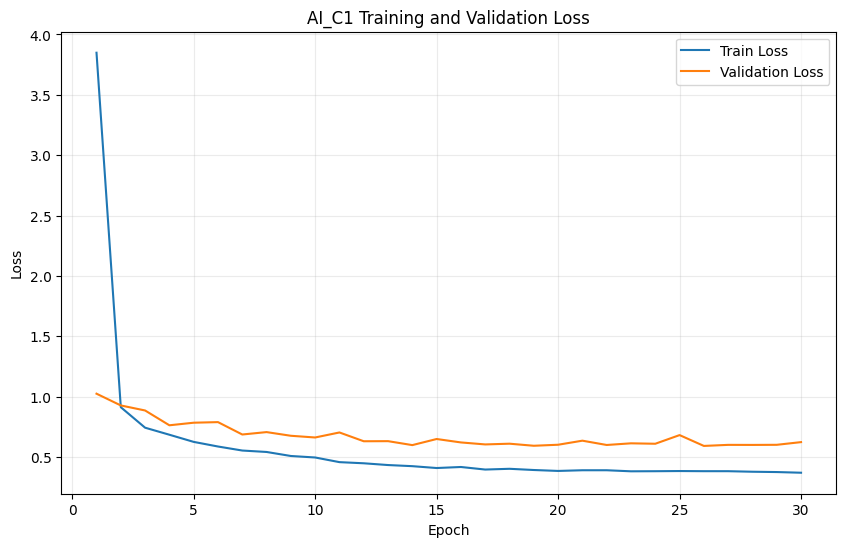

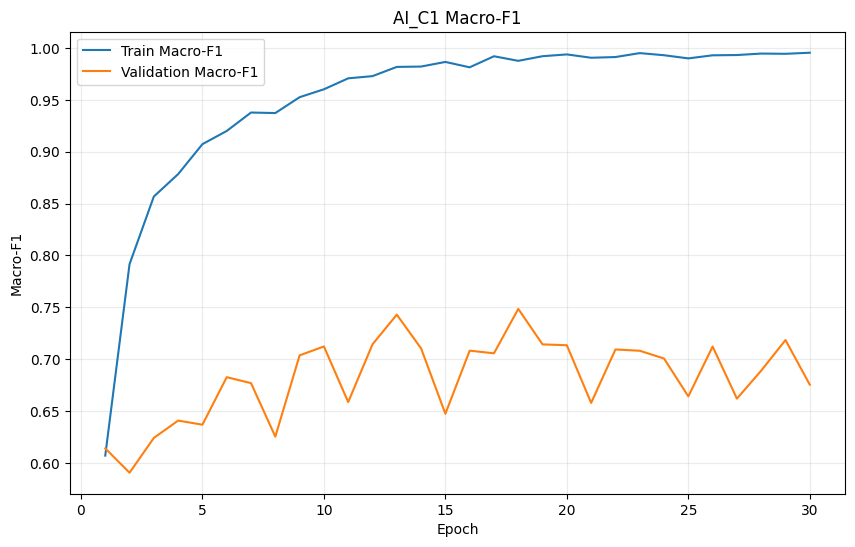

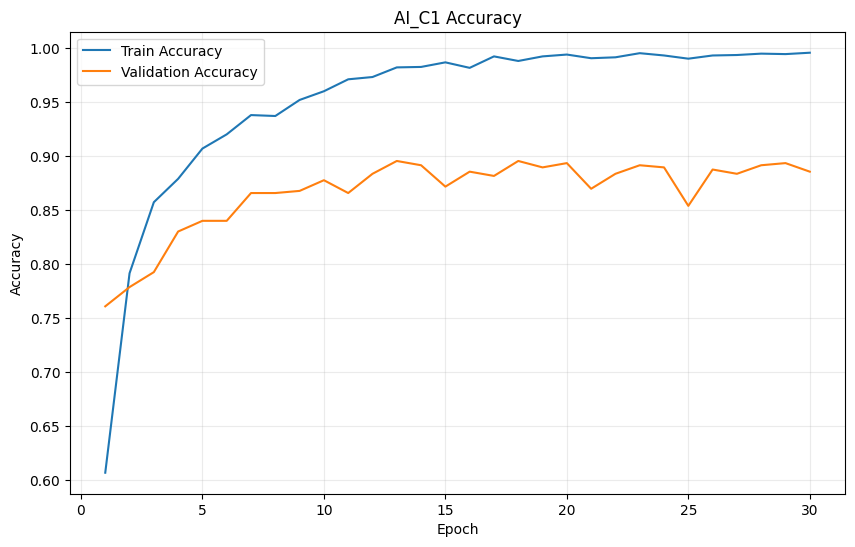

Best classifier model: /content/drive/MyDrive/OralScan_AI/classifier_training/models/ai_c1_efficientnetv2_b3_best.pt


In [ ]:
# ============================================================
# CELL 11: TRAIN AI_C1 + SHOW TRAINING CURVES
# ============================================================

training_history_df, training_summary = train_classifier(
    model=ai_c1_model,
    train_loader=train_loader,
    valid_loader=valid_loader,
    optimizer=optimizer,
    scheduler=scheduler,
    criterion=criterion,
    scaler=scaler,
    device=DEVICE,
    max_epochs=MAX_EPOCHS,
    patience=EARLY_STOPPING_PATIENCE
)

display(training_history_df.tail())


# ------------------------------------------------------------
# TRAINING CURVES
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    training_history_df["epoch"],
    training_history_df["train_loss"],
    label="Train Loss"
)

plt.plot(
    training_history_df["epoch"],
    training_history_df["valid_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("AI_C1 Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


plt.figure(figsize=(10, 6))

plt.plot(
    training_history_df["epoch"],
    training_history_df["train_f1_macro"],
    label="Train Macro-F1"
)

plt.plot(
    training_history_df["epoch"],
    training_history_df["valid_f1_macro"],
    label="Validation Macro-F1"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")
plt.title("AI_C1 Macro-F1")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


plt.figure(figsize=(10, 6))

plt.plot(
    training_history_df["epoch"],
    training_history_df["train_accuracy"],
    label="Train Accuracy"
)

plt.plot(
    training_history_df["epoch"],
    training_history_df["valid_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("AI_C1 Accuracy")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print("Best classifier model:", AI_C1_BEST_PATH)

# Test evaluation, confusion matrix, ROC and JSON report

Loaded best epoch: 18
Best validation macro-F1: 0.7485291513249479


Testing ai_c1:   0%|          | 0/16 [00:00<?, ?it/s]

,precision,recall,f1-score,support
Cancer,0.937500,0.933610,0.935551,241.000000
Leukoplakia,0.650000,0.684211,0.666667,38.000000
Leukoplakia-like Conditions,0.571429,0.363636,0.444444,22.000000
Normal Buccal Mucosa,0.910377,0.941463,0.925659,205.000000
accuracy,0.893281,0.893281,0.893281,0.893281
macro avg,0.767326,0.730730,0.743080,506.000000
weighted avg,0.889005,0.893281,0.889998,506.000000


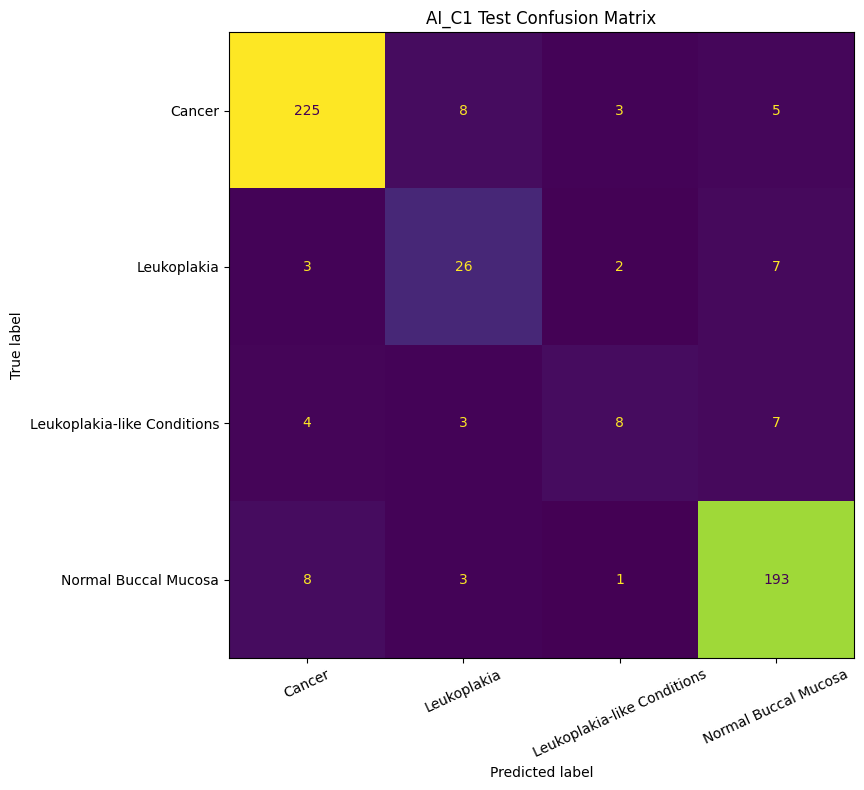

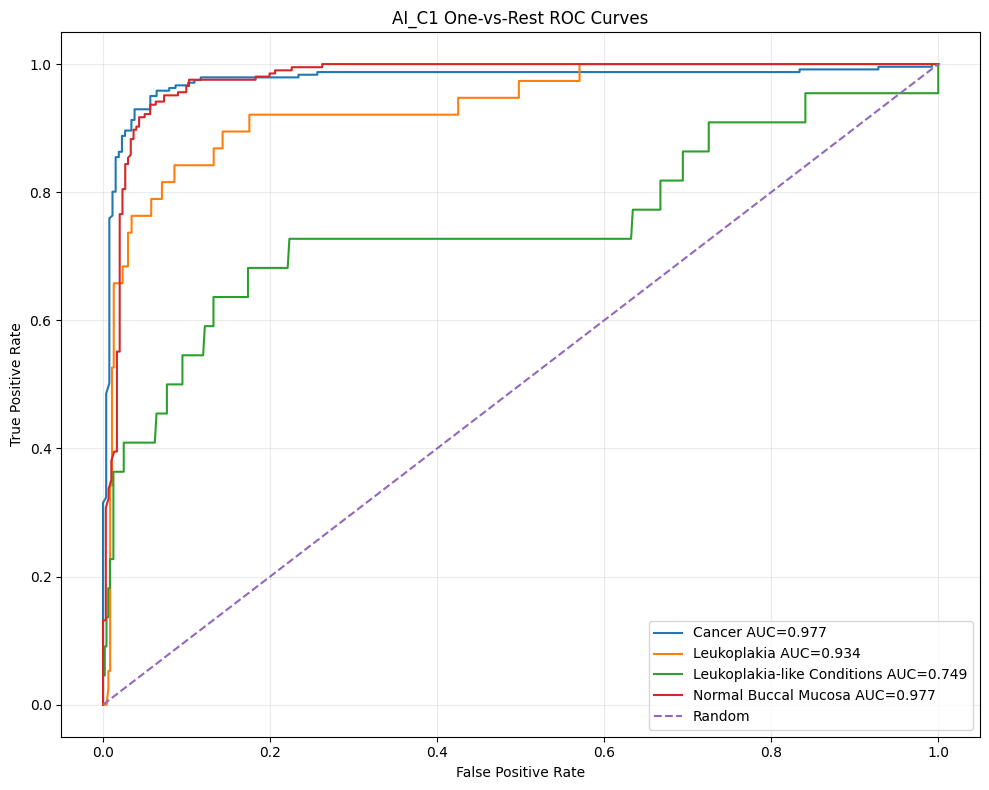


FINAL AI_C1 TEST RESULTS
Accuracy       : 0.8933
Macro Precision: 0.7673
Macro Recall   : 0.7307
Macro F1       : 0.7431
Macro ROC-AUC  : Not available
Mean inference : 0.86 ms/image
JSON report    : /content/drive/MyDrive/OralScan_AI/classifier_training/reports/ai_c1_test_report.json
Predictions CSV: /content/drive/MyDrive/OralScan_AI/classifier_training/reports/ai_c1_test_predictions.csv


In [ ]:
# ============================================================
# CELL 12: LOAD BEST MODEL + COMPLETE TEST EVALUATION
# ============================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve,
    auc,
    roc_auc_score,
    precision_recall_fscore_support,
    accuracy_score
)

from sklearn.preprocessing import label_binarize


AI_C1_TEST_REPORT_PATH = (
    REPORT_DIR /
    "ai_c1_test_report.json"
)

AI_C1_PREDICTIONS_PATH = (
    REPORT_DIR /
    "ai_c1_test_predictions.csv"
)

AI_C1_CONFUSION_MATRIX_PATH = (
    REPORT_DIR /
    "ai_c1_confusion_matrix.png"
)

AI_C1_ROC_CURVE_PATH = (
    REPORT_DIR /
    "ai_c1_multiclass_roc.png"
)


# ------------------------------------------------------------
# LOAD BEST CHECKPOINT
# ------------------------------------------------------------

best_checkpoint = torch.load(
    str(AI_C1_BEST_PATH),
    map_location=DEVICE,
    weights_only=False
)

ai_c1_model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

ai_c1_model.to(DEVICE)
ai_c1_model.eval()

print("Loaded best epoch:", best_checkpoint["epoch"])
print(
    "Best validation macro-F1:",
    best_checkpoint["best_validation_macro_f1"]
)


# ------------------------------------------------------------
# TEST INFERENCE
# ------------------------------------------------------------

test_start_time = time.perf_counter()

all_true_labels = []
all_predicted_labels = []
all_probabilities = []
all_image_paths = []
all_inference_times = []

with torch.inference_mode():

    for batch in tqdm(
        test_loader,
        desc="Testing ai_c1"
    ):

        images = batch["image"].to(
            DEVICE,
            non_blocking=True
        )

        labels = batch["label"].to(
            DEVICE,
            non_blocking=True
        )

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        batch_start_time = time.perf_counter()

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=torch.cuda.is_available()
        ):
            logits = ai_c1_model(images)

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        batch_duration = (
            time.perf_counter() -
            batch_start_time
        )

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        per_image_time = (
            batch_duration / images.size(0)
        )

        all_true_labels.extend(
            labels.cpu().numpy().tolist()
        )

        all_predicted_labels.extend(
            predictions.cpu().numpy().tolist()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy().tolist()
        )

        all_image_paths.extend(
            batch["image_path"]
        )

        all_inference_times.extend(
            [per_image_time] * images.size(0)
        )


all_true_labels = np.array(all_true_labels)
all_predicted_labels = np.array(all_predicted_labels)
all_probabilities = np.array(all_probabilities)

total_test_duration = (
    time.perf_counter() -
    test_start_time
)


# ------------------------------------------------------------
# GLOBAL TEST METRICS
# ------------------------------------------------------------

test_accuracy = accuracy_score(
    all_true_labels,
    all_predicted_labels
)

precision_macro, recall_macro, f1_macro, _ = (
    precision_recall_fscore_support(
        all_true_labels,
        all_predicted_labels,
        average="macro",
        zero_division=0
    )
)

precision_weighted, recall_weighted, f1_weighted, _ = (
    precision_recall_fscore_support(
        all_true_labels,
        all_predicted_labels,
        average="weighted",
        zero_division=0
    )
)

try:
    test_roc_auc_macro = roc_auc_score(
        all_true_labels,
        all_probabilities,
        multi_class="ovr",
        average="macro",
        labels=list(range(NUM_CLASSES))
    )
except ValueError:
    test_roc_auc_macro = None


# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

classification_report_dictionary = (
    classification_report(
        all_true_labels,
        all_predicted_labels,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )
)

classification_report_dataframe = (
    pd.DataFrame(
        classification_report_dictionary
    ).transpose()
)

display(classification_report_dataframe)


# ------------------------------------------------------------
# CONFUSION MATRIX + SENSITIVITY/SPECIFICITY
# ------------------------------------------------------------

confusion_matrix_array = confusion_matrix(
    all_true_labels,
    all_predicted_labels,
    labels=list(range(NUM_CLASSES))
)

per_class_medical_metrics = {}

for class_index, class_name in enumerate(CLASS_NAMES):

    true_positive = confusion_matrix_array[
        class_index,
        class_index
    ]

    false_negative = (
        confusion_matrix_array[
            class_index,
            :
        ].sum() - true_positive
    )

    false_positive = (
        confusion_matrix_array[
            :,
            class_index
        ].sum() - true_positive
    )

    true_negative = (
        confusion_matrix_array.sum()
        - true_positive
        - false_negative
        - false_positive
    )

    sensitivity = (
        true_positive /
        (true_positive + false_negative)
        if (true_positive + false_negative) > 0
        else 0.0
    )

    specificity = (
        true_negative /
        (true_negative + false_positive)
        if (true_negative + false_positive) > 0
        else 0.0
    )

    per_class_medical_metrics[class_name] = {
        "true_positive": int(true_positive),
        "false_positive": int(false_positive),
        "false_negative": int(false_negative),
        "true_negative": int(true_negative),
        "sensitivity_recall": float(sensitivity),
        "specificity": float(specificity)
    }


plt.figure(figsize=(10, 8))

confusion_display = ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix_array,
    display_labels=CLASS_NAMES
)

confusion_display.plot(
    values_format="d",
    xticks_rotation=25,
    ax=plt.gca(),
    colorbar=False
)

plt.title("AI_C1 Test Confusion Matrix")
plt.tight_layout()
plt.savefig(
    AI_C1_CONFUSION_MATRIX_PATH,
    dpi=200,
    bbox_inches="tight"
)
plt.show()


# ------------------------------------------------------------
# MULTICLASS ROC CURVE
# ------------------------------------------------------------

binarized_true_labels = label_binarize(
    all_true_labels,
    classes=list(range(NUM_CLASSES))
)

per_class_roc_auc = {}

plt.figure(figsize=(10, 8))

for class_index, class_name in enumerate(CLASS_NAMES):

    false_positive_rate, true_positive_rate, _ = (
        roc_curve(
            binarized_true_labels[:, class_index],
            all_probabilities[:, class_index]
        )
    )

    class_auc = auc(
        false_positive_rate,
        true_positive_rate
    )

    per_class_roc_auc[class_name] = float(
        class_auc
    )

    plt.plot(
        false_positive_rate,
        true_positive_rate,
        label=f"{class_name} AUC={class_auc:.3f}"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("AI_C1 One-vs-Rest ROC Curves")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    AI_C1_ROC_CURVE_PATH,
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# SAVE PER-IMAGE PREDICTIONS
# ------------------------------------------------------------

prediction_rows = []

for index in range(len(all_true_labels)):

    true_index = int(all_true_labels[index])
    predicted_index = int(
        all_predicted_labels[index]
    )

    row = {
        "image_path": all_image_paths[index],
        "true_class_index": true_index,
        "true_class_name":
            CLASS_NAMES[true_index],
        "predicted_class_index":
            predicted_index,
        "predicted_class_name":
            CLASS_NAMES[predicted_index],
        "correct":
            true_index == predicted_index,
        "inference_seconds":
            float(all_inference_times[index])
    }

    for class_index, class_name in enumerate(
        CLASS_NAMES
    ):
        safe_name = normalize_name(class_name)

        row[f"probability_{safe_name}"] = float(
            all_probabilities[
                index,
                class_index
            ]
        )

    prediction_rows.append(row)

test_predictions_df = pd.DataFrame(
    prediction_rows
)

test_predictions_df.to_csv(
    AI_C1_PREDICTIONS_PATH,
    index=False
)


# ------------------------------------------------------------
# FINAL TEST JSON REPORT
# ------------------------------------------------------------

test_report = {
    "model": {
        "model_id": "ai_c1",
        "architecture": AI_C1_MODEL_NAME,
        "checkpoint_path":
            str(AI_C1_BEST_PATH),
        "best_epoch":
            int(best_checkpoint["epoch"]),
        "class_names":
            CLASS_NAMES,
        "image_size":
            IMAGE_SIZE
    },

    "dataset": {
        "test_images":
            int(len(all_true_labels))
    },

    "global_metrics": {
        "accuracy":
            float(test_accuracy),
        "precision_macro":
            float(precision_macro),
        "recall_macro":
            float(recall_macro),
        "f1_macro":
            float(f1_macro),
        "precision_weighted":
            float(precision_weighted),
        "recall_weighted":
            float(recall_weighted),
        "f1_weighted":
            float(f1_weighted),
        "roc_auc_macro_ovr":
            (
                float(test_roc_auc_macro)
                if test_roc_auc_macro is not None
                else None
            )
    },

    "per_class_medical_metrics":
        per_class_medical_metrics,

    "per_class_roc_auc":
        per_class_roc_auc,

    "confusion_matrix":
        confusion_matrix_array.tolist(),

    "classification_report":
        classification_report_dictionary,

    "performance": {
        "total_test_seconds":
            float(total_test_duration),
        "mean_inference_seconds":
            float(
                np.mean(all_inference_times)
            ),
        "mean_inference_milliseconds":
            float(
                np.mean(all_inference_times)
                * 1000
            )
    },

    "files": {
        "predictions_csv":
            str(AI_C1_PREDICTIONS_PATH),
        "confusion_matrix_png":
            str(AI_C1_CONFUSION_MATRIX_PATH),
        "roc_curve_png":
            str(AI_C1_ROC_CURVE_PATH)
    }
}

with open(
    AI_C1_TEST_REPORT_PATH,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        test_report,
        file,
        indent=4
    )


print("\n" + "=" * 90)
print("FINAL AI_C1 TEST RESULTS")
print("=" * 90)
print(f"Accuracy       : {test_accuracy:.4f}")
print(f"Macro Precision: {precision_macro:.4f}")
print(f"Macro Recall   : {recall_macro:.4f}")
print(f"Macro F1       : {f1_macro:.4f}")
print(
    "Macro ROC-AUC  :",
    (
        f"{test_roc_auc_macro:.4f}"
        if test_roc_auc_macro is not None
        else "Not available"
    )
)
print(
    "Mean inference :",
    f"{np.mean(all_inference_times) * 1000:.2f} ms/image"
)
print("JSON report    :", AI_C1_TEST_REPORT_PATH)
print("Predictions CSV:", AI_C1_PREDICTIONS_PATH)
print("=" * 90)

# Final image prediction, masks, Layer-CAM, dashboard and JSON

✓ ai_c1 loaded
✓ ai_y1 loaded
Classifier classes: ['Cancer', 'Leukoplakia', 'Leukoplakia-like Conditions', 'Normal Buccal Mucosa']
YOLO classes: {0: 'processing_area', 1: 'lesion'}
Ek oral image select karke upload karein...


Saving aug_1_C087.jpeg to aug_1_C087.jpeg


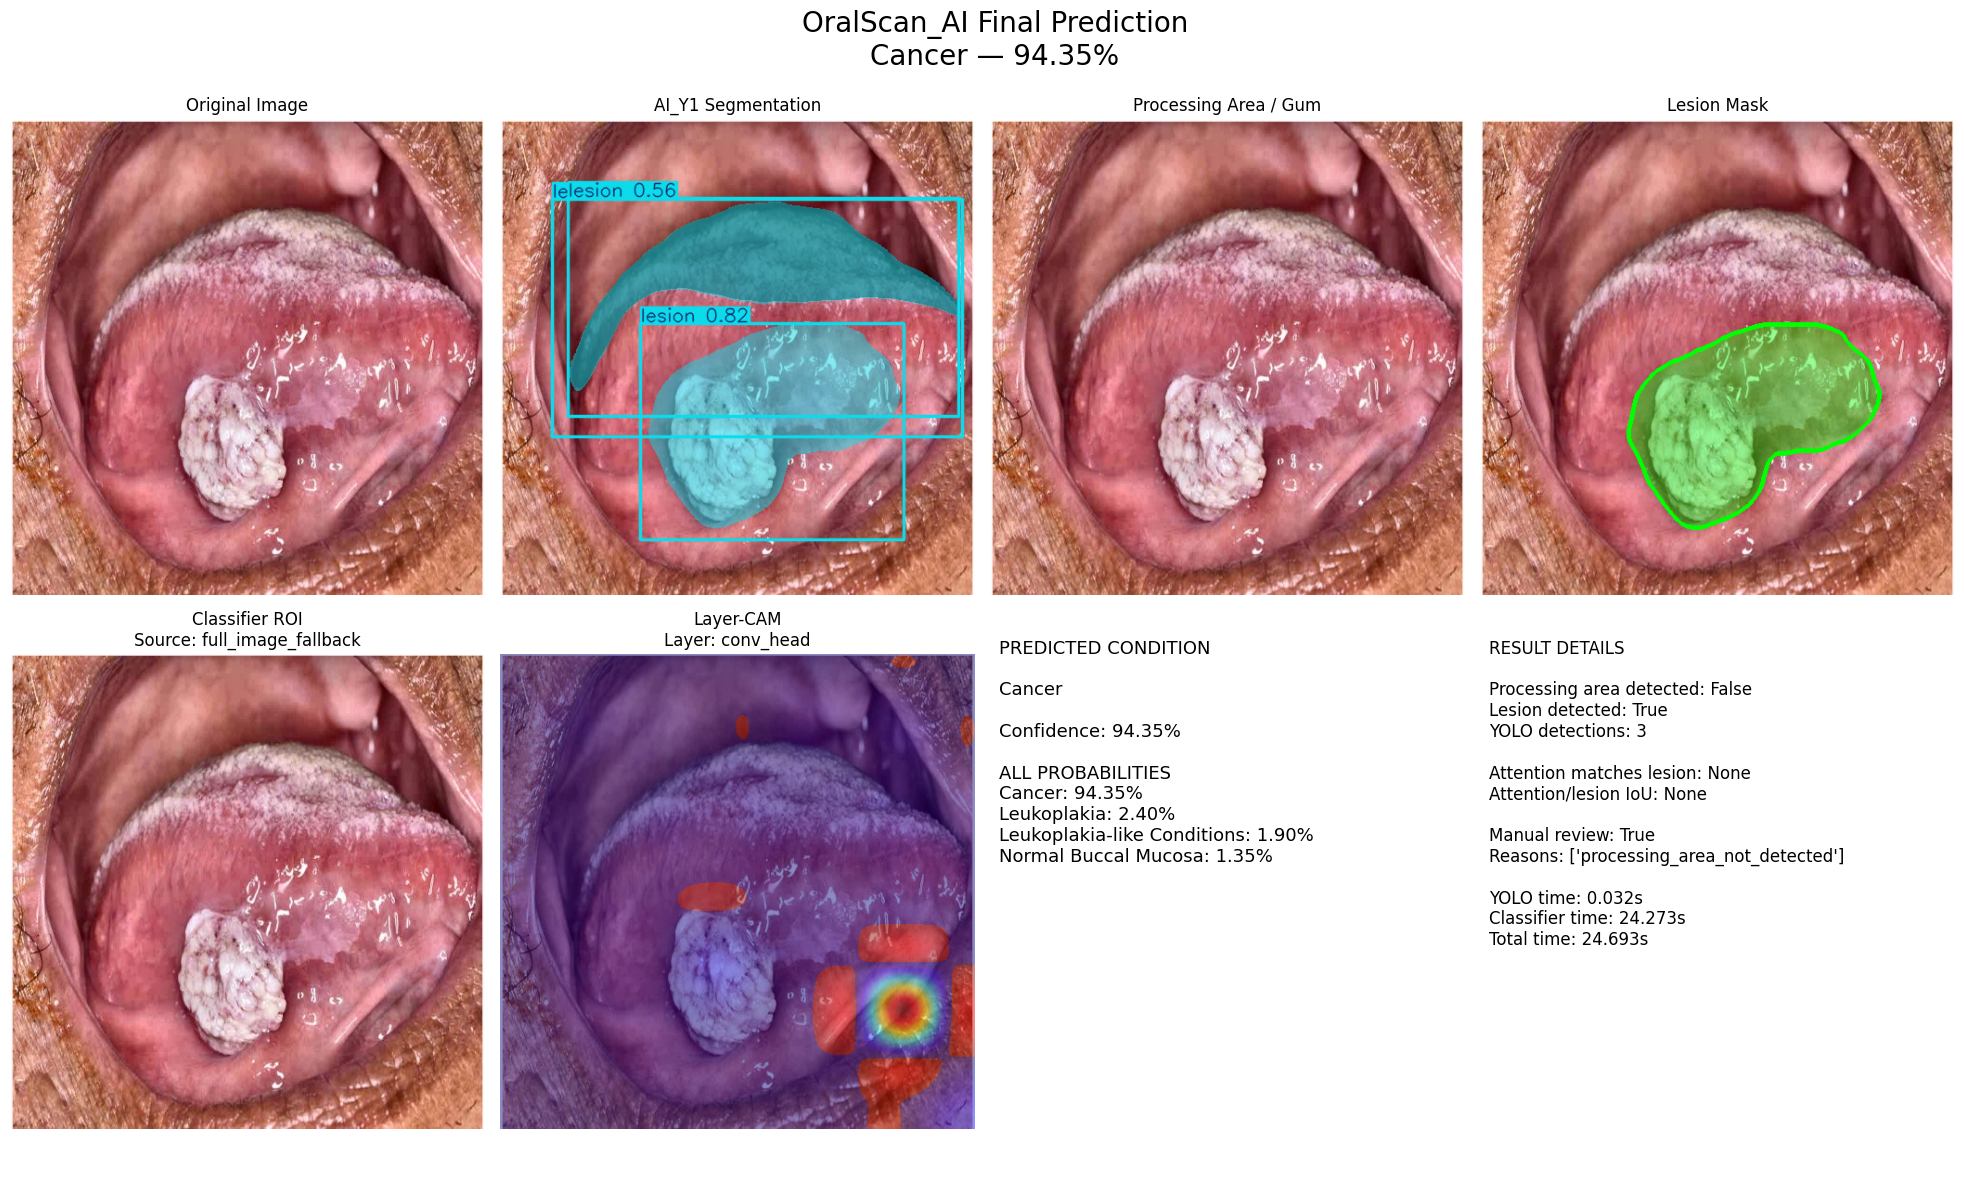


FINAL ORALSCAN RESULT
Request ID       : f8f07308-65bd-4bf7-b112-9b61bf42ada2
Prediction       : Cancer
Confidence       : 94.35%
Lesion detected  : True
Processing area  : False
Manual review    : True
Total time       : 24.693 seconds
Output folder    : /content/drive/MyDrive/OralScan_AI/classifier_training/final_predictions/f8f07308-65bd-4bf7-b112-9b61bf42ada2
Dashboard        : /content/drive/MyDrive/OralScan_AI/classifier_training/final_predictions/f8f07308-65bd-4bf7-b112-9b61bf42ada2/final_dashboard.png
JSON             : /content/drive/MyDrive/OralScan_AI/classifier_training/final_predictions/f8f07308-65bd-4bf7-b112-9b61bf42ada2/result.json
Lesion mask      : /content/drive/MyDrive/OralScan_AI/classifier_training/final_predictions/f8f07308-65bd-4bf7-b112-9b61bf42ada2/lesion_mask.png
Processing mask  : /content/drive/MyDrive/OralScan_AI/classifier_training/final_predictions/f8f07308-65bd-4bf7-b112-9b61bf42ada2/processing_area_mask.png

Returned JSON dictionary:
{
  "request_id":

In [ ]:
# ============================================================
# CELL 13: FINAL INTEGRATED ORALSCAN PREDICTION FUNCTION
# ============================================================

import uuid
import json
import time
import cv2
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from pathlib import Path
from datetime import datetime, timezone
from google.colab import files
from PIL import Image


FINAL_OUTPUT_DIR = (
    PROJECT_DIR /
    "final_predictions"
)

FINAL_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# LOAD BEST CLASSIFIER IF NOT ALREADY LOADED
# ------------------------------------------------------------

def load_best_ai_c1():
    """
    Load best ai_c1 checkpoint with frozen class mapping.
    """

    checkpoint = torch.load(
        str(AI_C1_BEST_PATH),
        map_location=DEVICE,
        weights_only=False
    )

    model = timm.create_model(
        checkpoint["architecture"],
        pretrained=False,
        num_classes=checkpoint["num_classes"],
        drop_rate=checkpoint.get(
            "dropout_rate",
            DROPOUT_RATE
        )
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model.to(DEVICE)
    model.eval()

    checkpoint_classes = checkpoint[
        "class_names"
    ]

    if checkpoint_classes != CLASS_NAMES:
        raise ValueError(
            "Classifier class order mismatch.\n"
            f"Checkpoint: {checkpoint_classes}\n"
            f"Current: {CLASS_NAMES}"
        )

    return model, checkpoint


final_classifier_model, final_classifier_checkpoint = (
    load_best_ai_c1()
)

print("✓ ai_c1 loaded")
print("✓ ai_y1 loaded")
print("Classifier classes:", CLASS_NAMES)
print("YOLO classes:", yolo_names)


# ------------------------------------------------------------
# LAYER-CAM IMPLEMENTATION
# ------------------------------------------------------------

def find_last_convolution_layer(model):
    """
    Automatically locate final Conv2d layer.
    Compatible with timm EfficientNet-style models.
    """

    last_layer = None
    last_layer_name = None

    for layer_name, layer in model.named_modules():

        if isinstance(layer, nn.Conv2d):
            last_layer = layer
            last_layer_name = layer_name

    if last_layer is None:
        raise RuntimeError(
            "Classifier mein Conv2d layer nahi mili."
        )

    return last_layer_name, last_layer


def generate_layer_cam(
    model,
    input_tensor,
    target_class_index
):
    """
    Generate Layer-CAM using positive gradients × activations.
    """

    activations = {}
    gradients = {}

    target_layer_name, target_layer = (
        find_last_convolution_layer(model)
    )

    def forward_hook(module, inputs, output):
        activations["value"] = output

    def backward_hook(module, grad_input, grad_output):
        gradients["value"] = grad_output[0]

    forward_handle = target_layer.register_forward_hook(
        forward_hook
    )

    backward_handle = (
        target_layer.register_full_backward_hook(
            backward_hook
        )
    )

    model.zero_grad(set_to_none=True)

    logits = model(input_tensor)

    target_score = logits[
        0,
        target_class_index
    ]

    target_score.backward()

    feature_maps = activations[
        "value"
    ][0]

    feature_gradients = gradients[
        "value"
    ][0]

    positive_gradients = torch.relu(
        feature_gradients
    )

    layer_cam = torch.sum(
        positive_gradients * feature_maps,
        dim=0
    )

    layer_cam = torch.relu(layer_cam)

    layer_cam = layer_cam.detach().cpu().numpy()

    layer_cam -= layer_cam.min()

    if layer_cam.max() > 0:
        layer_cam /= layer_cam.max()

    forward_handle.remove()
    backward_handle.remove()

    return layer_cam, target_layer_name


# ------------------------------------------------------------
# IMAGE PREPARATION
# ------------------------------------------------------------

def classifier_tensor_from_bgr(
    image_bgr
):
    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB
    )

    transformed = evaluation_transform(
        image=image_rgb
    )

    tensor = transformed["image"].unsqueeze(0)

    return tensor.to(DEVICE)


def save_binary_mask(
    mask,
    save_path
):
    mask_uint8 = (
        mask.astype(np.uint8) * 255
    )

    cv2.imwrite(
        str(save_path),
        mask_uint8
    )


def mask_overlay(
    image_bgr,
    binary_mask
):
    """
    Return image with visible segmentation overlay.
    """

    overlay = image_bgr.copy()

    mask_uint8 = (
        binary_mask.astype(np.uint8) * 255
    )

    contours, _ = cv2.findContours(
        mask_uint8,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cv2.drawContours(
        overlay,
        contours,
        -1,
        (0, 255, 0),
        3
    )

    tinted = overlay.copy()

    tinted[binary_mask.astype(bool)] = (
        0.60 *
        tinted[binary_mask.astype(bool)]
        +
        0.40 *
        np.array([0, 255, 0])
    ).astype(np.uint8)

    return tinted


def cam_overlay_on_image(
    image_bgr,
    cam
):
    resized_cam = cv2.resize(
        cam,
        (
            image_bgr.shape[1],
            image_bgr.shape[0]
        ),
        interpolation=cv2.INTER_CUBIC
    )

    heatmap = cv2.applyColorMap(
        np.uint8(255 * resized_cam),
        cv2.COLORMAP_JET
    )

    overlay = cv2.addWeighted(
        image_bgr,
        0.55,
        heatmap,
        0.45,
        0
    )

    return overlay, resized_cam


def extract_detection_information(
    result,
    image_width,
    image_height
):
    """
    Extract class, confidence, bbox, polygon and mask.
    """

    detections = []

    if (
        result.boxes is None
        or len(result.boxes) == 0
    ):
        return detections

    class_ids = (
        result.boxes.cls
        .detach()
        .cpu()
        .numpy()
        .astype(int)
    )

    confidences = (
        result.boxes.conf
        .detach()
        .cpu()
        .numpy()
    )

    bounding_boxes = (
        result.boxes.xyxy
        .detach()
        .cpu()
        .numpy()
    )

    raw_masks = None
    polygon_coordinates = None

    if result.masks is not None:

        raw_masks = (
            result.masks.data
            .detach()
            .cpu()
            .numpy()
        )

        polygon_coordinates = result.masks.xy

    for detection_index in range(
        len(class_ids)
    ):

        class_id = int(
            class_ids[detection_index]
        )

        confidence = float(
            confidences[detection_index]
        )

        bbox = [
            float(value)
            for value in bounding_boxes[
                detection_index
            ].tolist()
        ]

        binary_mask = None
        mask_area_ratio = None
        polygon = []

        if raw_masks is not None:

            resized_mask = cv2.resize(
                raw_masks[detection_index],
                (
                    image_width,
                    image_height
                ),
                interpolation=cv2.INTER_NEAREST
            )

            binary_mask = resized_mask > 0.5

            mask_area_ratio = float(
                binary_mask.mean()
            )

        if (
            polygon_coordinates is not None
            and detection_index <
            len(polygon_coordinates)
        ):

            polygon = [
                [
                    round(float(point[0]), 2),
                    round(float(point[1]), 2)
                ]
                for point in
                polygon_coordinates[
                    detection_index
                ]
            ]

        detections.append({
            "detection_index":
                detection_index,
            "class_id":
                class_id,
            "class_name":
                yolo_names.get(
                    class_id,
                    str(class_id)
                ),
            "confidence":
                confidence,
            "bounding_box_xyxy":
                bbox,
            "polygon_points":
                polygon,
            "mask_area_ratio":
                mask_area_ratio,
            "_binary_mask":
                binary_mask
        })

    return detections


def select_best_detection(
    detections,
    target_class_id
):
    candidates = [
        detection
        for detection in detections
        if detection["class_id"]
        == int(target_class_id)
    ]

    if not candidates:
        return None

    candidates.sort(
        key=lambda detection:
            detection["confidence"]
            *
            np.sqrt(
                max(
                    detection[
                        "mask_area_ratio"
                    ] or 0.0,
                    1e-8
                )
            ),
        reverse=True
    )

    return candidates[0]


# ------------------------------------------------------------
# FINAL PREDICTION FUNCTION
# ------------------------------------------------------------

def predict_oralscan_image(
    image_path,
    yolo_confidence=0.20,
    save_outputs=True,
    display_dashboard=True
):
    """
    Complete OralScan prediction.

    Input:
        Single oral image path.

    Output:
        - YOLO lesion and processing-area segmentation
        - Processing ROI crop
        - Four-class disease classification
        - Class probabilities
        - Layer-CAM
        - Combined dashboard
        - Detailed JSON
    """

    request_id = str(uuid.uuid4())

    request_folder = (
        FINAL_OUTPUT_DIR /
        request_id
    )

    if save_outputs:
        request_folder.mkdir(
            parents=True,
            exist_ok=True
        )

    total_start_time = time.perf_counter()

    image_path = Path(image_path)

    original_bgr = cv2.imread(
        str(image_path)
    )

    if original_bgr is None:
        raise ValueError(
            f"Image read nahi hui: {image_path}"
        )

    image_height, image_width = (
        original_bgr.shape[:2]
    )

    # --------------------------------------------------------
    # STAGE 1: YOLO SEGMENTATION
    # --------------------------------------------------------

    yolo_start_time = time.perf_counter()

    yolo_result = yolo_model.predict(
        source=original_bgr,
        imgsz=YOLO_IMAGE_SIZE,
        conf=yolo_confidence,
        device=0,
        retina_masks=True,
        verbose=False
    )[0]

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    yolo_seconds = (
        time.perf_counter() -
        yolo_start_time
    )

    detections = extract_detection_information(
        result=yolo_result,
        image_width=image_width,
        image_height=image_height
    )

    processing_detection = (
        select_best_detection(
            detections,
            PROCESSING_AREA_CLASS_ID
        )
    )

    lesion_detection = None

    if LESION_CLASS_ID is not None:
        lesion_detection = select_best_detection(
            detections,
            LESION_CLASS_ID
        )

    # --------------------------------------------------------
    # PROCESSING-AREA ROI
    # --------------------------------------------------------

    processing_mask = np.zeros(
        (image_height, image_width),
        dtype=bool
    )

    lesion_mask = np.zeros(
        (image_height, image_width),
        dtype=bool
    )

    roi_source = "full_image_fallback"
    roi_bbox = [
        0,
        0,
        image_width,
        image_height
    ]

    classifier_roi_bgr = original_bgr.copy()

    if processing_detection is not None:

        processing_mask = processing_detection[
            "_binary_mask"
        ]

        roi_result = create_processing_roi(
            image_bgr=original_bgr,
            binary_mask=processing_mask.astype(
                np.uint8
            ),
            padding_ratio=ROI_PADDING_RATIO,
            use_masked_roi=False
        )

        if roi_result is not None:

            classifier_roi_bgr = roi_result[
                "roi_image"
            ]

            roi_bbox = roi_result["bbox"]

            roi_source = (
                "processing_area_segmentation"
            )

    if lesion_detection is not None:
        lesion_mask = lesion_detection[
            "_binary_mask"
        ]

    # --------------------------------------------------------
    # STAGE 2: CLASSIFIER
    # --------------------------------------------------------

    classifier_input_tensor = (
        classifier_tensor_from_bgr(
            classifier_roi_bgr
        )
    )

    classifier_start_time = time.perf_counter()

    final_classifier_model.eval()

    with torch.inference_mode():

        classifier_logits = (
            final_classifier_model(
                classifier_input_tensor
            )
        )

        classifier_probabilities = (
            torch.softmax(
                classifier_logits,
                dim=1
            )[0]
            .detach()
            .cpu()
            .numpy()
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    classifier_seconds = (
        time.perf_counter() -
        classifier_start_time
    )

    predicted_class_index = int(
        np.argmax(
            classifier_probabilities
        )
    )

    predicted_class_name = CLASS_NAMES[
        predicted_class_index
    ]

    predicted_confidence = float(
        classifier_probabilities[
            predicted_class_index
        ]
    )

    # --------------------------------------------------------
    # LAYER-CAM
    # --------------------------------------------------------

    layer_cam_start_time = time.perf_counter()

    cam_input_tensor = (
        classifier_input_tensor
        .detach()
        .clone()
    )

    cam_input_tensor.requires_grad_(True)

    layer_cam, cam_layer_name = (
        generate_layer_cam(
            model=final_classifier_model,
            input_tensor=cam_input_tensor,
            target_class_index=
                predicted_class_index
        )
    )

    layer_cam_overlay_bgr, resized_cam = (
        cam_overlay_on_image(
            classifier_roi_bgr,
            layer_cam
        )
    )

    layer_cam_seconds = (
        time.perf_counter() -
        layer_cam_start_time
    )

    # --------------------------------------------------------
    # ATTENTION / LESION AGREEMENT
    # --------------------------------------------------------

    attention_matches_lesion = None
    attention_lesion_iou = None

    if (
        lesion_detection is not None
        and roi_source
        == "processing_area_segmentation"
    ):

        x1, y1, x2, y2 = roi_bbox

        lesion_roi_mask = lesion_mask[
            y1:y2,
            x1:x2
        ]

        lesion_roi_mask = cv2.resize(
            lesion_roi_mask.astype(
                np.uint8
            ),
            (
                classifier_roi_bgr.shape[1],
                classifier_roi_bgr.shape[0]
            ),
            interpolation=cv2.INTER_NEAREST
        ).astype(bool)

        attention_binary = (
            resized_cam >= 0.50
        )

        intersection = np.logical_and(
            attention_binary,
            lesion_roi_mask
        ).sum()

        union = np.logical_or(
            attention_binary,
            lesion_roi_mask
        ).sum()

        attention_lesion_iou = (
            float(intersection / union)
            if union > 0
            else 0.0
        )

        attention_matches_lesion = (
            attention_lesion_iou >= 0.10
        )

    # --------------------------------------------------------
    # VISUAL OUTPUTS
    # --------------------------------------------------------

    processing_overlay_bgr = (
        mask_overlay(
            original_bgr,
            processing_mask
        )
        if processing_mask.any()
        else original_bgr.copy()
    )

    lesion_overlay_bgr = (
        mask_overlay(
            original_bgr,
            lesion_mask
        )
        if lesion_mask.any()
        else original_bgr.copy()
    )

    yolo_annotated_bgr = yolo_result.plot()

    total_seconds = (
        time.perf_counter() -
        total_start_time
    )

    # --------------------------------------------------------
    # CLEAN JSON DETECTIONS
    # --------------------------------------------------------

    json_detections = []

    for detection in detections:

        clean_detection = {
            key: value
            for key, value in detection.items()
            if key != "_binary_mask"
        }

        json_detections.append(
            clean_detection
        )

    probability_dictionary = {
        CLASS_NAMES[class_index]:
            float(
                classifier_probabilities[
                    class_index
                ]
            )
        for class_index in range(
            NUM_CLASSES
        )
    }

    manual_review_reasons = []

    if processing_detection is None:
        manual_review_reasons.append(
            "processing_area_not_detected"
        )

    if predicted_confidence < 0.60:
        manual_review_reasons.append(
            "classifier_low_confidence"
        )

    if (
        attention_matches_lesion is False
    ):
        manual_review_reasons.append(
            "classifier_attention_does_not_match_lesion"
        )

    manual_review_required = (
        len(manual_review_reasons) > 0
    )

    result_json = {
        "request_id": request_id,

        "generated_at_utc":
            datetime.now(
                timezone.utc
            ).isoformat(),

        "system": {
            "detector_model_id": "ai_y1",
            "detector_model_path":
                str(YOLO_MODEL_PATH),
            "classifier_model_id": "ai_c1",
            "classifier_model_path":
                str(AI_C1_BEST_PATH),
            "classifier_architecture":
                AI_C1_MODEL_NAME
        },

        "input": {
            "filename": image_path.name,
            "image_path": str(image_path),
            "width": int(image_width),
            "height": int(image_height)
        },

        "segmentation": {
            "yolo_class_names":
                yolo_names,
            "confidence_threshold":
                float(yolo_confidence),
            "number_of_detections":
                len(json_detections),
            "detections":
                json_detections,

            "processing_area": {
                "detected":
                    processing_detection
                    is not None,
                "confidence":
                    (
                        float(
                            processing_detection[
                                "confidence"
                            ]
                        )
                        if processing_detection
                        is not None
                        else None
                    ),
                "roi_source":
                    roi_source,
                "roi_bbox_xyxy":
                    roi_bbox,
                "mask_area_ratio":
                    float(
                        processing_mask.mean()
                    )
            },

            "lesion": {
                "detected":
                    lesion_detection
                    is not None,
                "confidence":
                    (
                        float(
                            lesion_detection[
                                "confidence"
                            ]
                        )
                        if lesion_detection
                        is not None
                        else None
                    ),
                "mask_area_ratio":
                    float(
                        lesion_mask.mean()
                    )
            }
        },

        "classification": {
            "predicted_class_index":
                predicted_class_index,
            "predicted_class_name":
                predicted_class_name,
            "confidence":
                predicted_confidence,
            "probabilities":
                probability_dictionary
        },

        "explainability": {
            "method": "Layer-CAM",
            "target_layer":
                cam_layer_name,
            "attention_threshold":
                0.50,
            "attention_matches_lesion":
                attention_matches_lesion,
            "attention_lesion_iou":
                attention_lesion_iou
        },

        "manual_review": {
            "required":
                manual_review_required,
            "reasons":
                manual_review_reasons
        },

        "timing_seconds": {
            "yolo_segmentation":
                float(yolo_seconds),
            "classification":
                float(classifier_seconds),
            "layer_cam":
                float(layer_cam_seconds),
            "total":
                float(total_seconds)
        },

        "disclaimer": (
            "Research diagnostic-support output. "
            "This prediction is not a substitute "
            "for clinical diagnosis or biopsy."
        )
    }

    # --------------------------------------------------------
    # SAVE OUTPUTS
    # --------------------------------------------------------

    dashboard_path = (
        request_folder /
        "final_dashboard.png"
    )

    json_path = (
        request_folder /
        "result.json"
    )

    processing_mask_path = (
        request_folder /
        "processing_area_mask.png"
    )

    lesion_mask_path = (
        request_folder /
        "lesion_mask.png"
    )

    roi_path = (
        request_folder /
        "classifier_roi.png"
    )

    layer_cam_path = (
        request_folder /
        "layer_cam_overlay.png"
    )

    if save_outputs:

        save_binary_mask(
            processing_mask,
            processing_mask_path
        )

        save_binary_mask(
            lesion_mask,
            lesion_mask_path
        )

        cv2.imwrite(
            str(roi_path),
            classifier_roi_bgr
        )

        cv2.imwrite(
            str(layer_cam_path),
            layer_cam_overlay_bgr
        )

        with open(
            json_path,
            "w",
            encoding="utf-8"
        ) as file:

            json.dump(
                result_json,
                file,
                indent=4,
                ensure_ascii=False
            )

    # --------------------------------------------------------
    # FINAL DASHBOARD
    # --------------------------------------------------------

    probability_text = "\n".join([
        f"{class_name}: "
        f"{probability_dictionary[class_name] * 100:.2f}%"
        for class_name in CLASS_NAMES
    ])

    figure = plt.figure(
        figsize=(20, 12)
    )

    images_for_dashboard = [
        (
            cv2.cvtColor(
                original_bgr,
                cv2.COLOR_BGR2RGB
            ),
            "Original Image"
        ),

        (
            cv2.cvtColor(
                yolo_annotated_bgr,
                cv2.COLOR_BGR2RGB
            ),
            "AI_Y1 Segmentation"
        ),

        (
            cv2.cvtColor(
                processing_overlay_bgr,
                cv2.COLOR_BGR2RGB
            ),
            "Processing Area / Gum"
        ),

        (
            cv2.cvtColor(
                lesion_overlay_bgr,
                cv2.COLOR_BGR2RGB
            ),
            "Lesion Mask"
        ),

        (
            cv2.cvtColor(
                classifier_roi_bgr,
                cv2.COLOR_BGR2RGB
            ),
            f"Classifier ROI\nSource: {roi_source}"
        ),

        (
            cv2.cvtColor(
                layer_cam_overlay_bgr,
                cv2.COLOR_BGR2RGB
            ),
            f"Layer-CAM\nLayer: {cam_layer_name}"
        )
    ]

    for plot_index, (
        display_image,
        title
    ) in enumerate(
        images_for_dashboard,
        start=1
    ):

        axis = figure.add_subplot(
            2,
            4,
            plot_index
        )

        axis.imshow(display_image)
        axis.set_title(title)
        axis.axis("off")

    probability_axis = figure.add_subplot(
        2,
        4,
        7
    )

    probability_axis.axis("off")

    probability_axis.text(
        0.02,
        0.95,
        (
            f"PREDICTED CONDITION\n\n"
            f"{predicted_class_name}\n\n"
            f"Confidence: "
            f"{predicted_confidence * 100:.2f}%\n\n"
            f"ALL PROBABILITIES\n"
            f"{probability_text}"
        ),
        fontsize=13,
        verticalalignment="top"
    )

    summary_axis = figure.add_subplot(
        2,
        4,
        8
    )

    summary_axis.axis("off")

    summary_axis.text(
        0.02,
        0.95,
        (
            f"RESULT DETAILS\n\n"
            f"Processing area detected: "
            f"{processing_detection is not None}\n"
            f"Lesion detected: "
            f"{lesion_detection is not None}\n"
            f"YOLO detections: "
            f"{len(detections)}\n\n"
            f"Attention matches lesion: "
            f"{attention_matches_lesion}\n"
            f"Attention/lesion IoU: "
            f"{attention_lesion_iou}\n\n"
            f"Manual review: "
            f"{manual_review_required}\n"
            f"Reasons: "
            f"{manual_review_reasons}\n\n"
            f"YOLO time: "
            f"{yolo_seconds:.3f}s\n"
            f"Classifier time: "
            f"{classifier_seconds:.3f}s\n"
            f"Total time: "
            f"{total_seconds:.3f}s"
        ),
        fontsize=12,
        verticalalignment="top"
    )

    figure.suptitle(
        (
            "OralScan_AI Final Prediction\n"
            f"{predicted_class_name} — "
            f"{predicted_confidence * 100:.2f}%"
        ),
        fontsize=20
    )

    plt.tight_layout()

    if save_outputs:
        plt.savefig(
            dashboard_path,
            dpi=180,
            bbox_inches="tight"
        )

    if display_dashboard:
        plt.show()
    else:
        plt.close()

    print("\n" + "=" * 90)
    print("FINAL ORALSCAN RESULT")
    print("=" * 90)
    print("Request ID       :", request_id)
    print("Prediction       :", predicted_class_name)
    print(
        "Confidence       :",
        f"{predicted_confidence * 100:.2f}%"
    )
    print(
        "Lesion detected  :",
        lesion_detection is not None
    )
    print(
        "Processing area  :",
        processing_detection is not None
    )
    print(
        "Manual review    :",
        manual_review_required
    )
    print(
        "Total time       :",
        f"{total_seconds:.3f} seconds"
    )

    if save_outputs:
        print("Output folder    :", request_folder)
        print("Dashboard        :", dashboard_path)
        print("JSON             :", json_path)
        print("Lesion mask      :", lesion_mask_path)
        print(
            "Processing mask  :",
            processing_mask_path
        )

    print("=" * 90)

    return {
        "result": result_json,
        "dashboard_path":
            str(dashboard_path)
            if save_outputs else None,
        "json_path":
            str(json_path)
            if save_outputs else None,
        "output_folder":
            str(request_folder)
            if save_outputs else None
    }


# ------------------------------------------------------------
# COLAB UPLOAD FUNCTION
# ------------------------------------------------------------

def upload_and_predict_oralscan():
    """
    Upload one image directly in Colab and run full pipeline.
    """

    print(
        "Ek oral image select karke upload karein..."
    )

    uploaded_files = files.upload()

    if not uploaded_files:
        raise RuntimeError(
            "Koi image upload nahi hui."
        )

    uploaded_filename = next(
        iter(uploaded_files.keys())
    )

    uploaded_path = Path(
        "/content"
    ) / uploaded_filename

    with open(
        uploaded_path,
        "wb"
    ) as file:
        file.write(
            uploaded_files[
                uploaded_filename
            ]
        )

    return predict_oralscan_image(
        image_path=uploaded_path,
        yolo_confidence=YOLO_CONFIDENCE,
        save_outputs=True,
        display_dashboard=True
    )


# ------------------------------------------------------------
# RUN FINAL UPLOAD + PREDICTION
# ------------------------------------------------------------

final_prediction_output = (
    upload_and_predict_oralscan()
)

print("\nReturned JSON dictionary:")
print(
    json.dumps(
        final_prediction_output["result"],
        indent=2,
        ensure_ascii=False
    )
)

In [ ]:
# ============================================================
# CELL 13 — FINAL ORALSCAN INFERENCE
# Saves:
#   input image
#   dashboard
#   YOLO annotated image
#   processing-area mask
#   lesion mask
#   classifier ROI
#   focused Layer-CAM heatmap
#   result.json
#
# JSON is SAVED AS A FILE — NOT PRINTED IN NOTEBOOK.
# ============================================================

import os
import re
import cv2
import json
import time
import uuid
import shutil
import hashlib
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import timm

from pathlib import Path
from datetime import datetime, timezone
from google.colab import files


# ------------------------------------------------------------
# OUTPUT ROOT
# ------------------------------------------------------------

FINAL_OUTPUT_DIR = (
    PROJECT_DIR /
    "final_predictions"
)

FINAL_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# INFERENCE SETTINGS
# ------------------------------------------------------------

FINAL_YOLO_CONFIDENCE = 0.20

# Prediction confidence below this → manual review
CLASSIFIER_REVIEW_THRESHOLD = 0.60

# Detection confidence below this → manual review
DETECTION_REVIEW_THRESHOLD = 0.25

# CAM threshold used for attention overlap
CAM_BINARY_THRESHOLD = 0.45

# Minimum attention-lesion overlap
MIN_ATTENTION_LESION_IOU = 0.10

# When lesion exists, CAM outside lesion remains visible but reduced.
LESION_CAM_OUTSIDE_WEIGHT = 0.12

# Add some context around lesion mask before focusing CAM.
LESION_CAM_DILATION_PIXELS = 17


# ------------------------------------------------------------
# LOAD CLASSIFIER
# ------------------------------------------------------------

def load_final_ai_c1():
    """
    Load the best trained classifier checkpoint.
    """

    if not Path(AI_C1_BEST_PATH).exists():
        raise FileNotFoundError(
            f"Classifier checkpoint nahi mila:\n"
            f"{AI_C1_BEST_PATH}"
        )

    checkpoint = torch.load(
        str(AI_C1_BEST_PATH),
        map_location=DEVICE,
        weights_only=False
    )

    architecture = checkpoint[
        "architecture"
    ]

    checkpoint_class_names = checkpoint[
        "class_names"
    ]

    if checkpoint_class_names != CLASS_NAMES:
        raise ValueError(
            "Classifier class order mismatch.\n\n"
            f"Checkpoint classes:\n"
            f"{checkpoint_class_names}\n\n"
            f"Current classes:\n"
            f"{CLASS_NAMES}"
        )

    model = timm.create_model(
        architecture,
        pretrained=False,
        num_classes=checkpoint[
            "num_classes"
        ],
        drop_rate=checkpoint.get(
            "dropout_rate",
            DROPOUT_RATE
        )
    )

    model.load_state_dict(
        checkpoint[
            "model_state_dict"
        ]
    )

    model.to(DEVICE)
    model.eval()

    return model, checkpoint


final_classifier_model, final_classifier_checkpoint = (
    load_final_ai_c1()
)

print("✓ ai_c1 classifier loaded")
print("✓ ai_y1 segmentation model loaded")
print("Classifier classes:", CLASS_NAMES)
print("YOLO classes:", yolo_names)


# ------------------------------------------------------------
# GENERAL HELPERS
# ------------------------------------------------------------

def sanitize_filename_component(
    value: str
) -> str:
    """
    Convert filename into folder-safe text.
    """

    value = Path(value).stem

    value = re.sub(
        r"[^A-Za-z0-9_-]+",
        "_",
        value
    )

    value = value.strip("_")

    return value or "oral_image"


def calculate_sha256(
    file_path: Path
) -> str:

    digest = hashlib.sha256()

    with open(file_path, "rb") as file:

        for block in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            digest.update(block)

    return digest.hexdigest()


def convert_to_json_safe(value):
    """
    Recursively convert NumPy/PyTorch values
    into JSON-serializable Python values.
    """

    if isinstance(value, dict):
        return {
            str(key): convert_to_json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            convert_to_json_safe(item)
            for item in value
        ]

    if isinstance(value, np.ndarray):
        return value.tolist()

    if isinstance(
        value,
        (
            np.integer,
            np.int8,
            np.int16,
            np.int32,
            np.int64
        )
    ):
        return int(value)

    if isinstance(
        value,
        (
            np.floating,
            np.float16,
            np.float32,
            np.float64
        )
    ):
        return float(value)

    if isinstance(value, np.bool_):
        return bool(value)

    if torch.is_tensor(value):
        return value.detach().cpu().tolist()

    if isinstance(value, Path):
        return str(value)

    return value


def save_json_file(
    data: dict,
    destination: Path
):
    """
    Save JSON to disk. It does not print JSON.
    """

    safe_data = convert_to_json_safe(data)

    with open(
        destination,
        "w",
        encoding="utf-8"
    ) as file:

        json.dump(
            safe_data,
            file,
            indent=4,
            ensure_ascii=False
        )


def save_binary_mask(
    binary_mask: np.ndarray,
    destination: Path
):

    image = (
        binary_mask.astype(np.uint8)
        * 255
    )

    success = cv2.imwrite(
        str(destination),
        image
    )

    if not success:
        raise IOError(
            f"Mask save nahi hui:\n"
            f"{destination}"
        )


def classifier_tensor_from_bgr(
    image_bgr: np.ndarray
):

    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB
    )

    transformed = evaluation_transform(
        image=image_rgb
    )

    tensor = transformed[
        "image"
    ].unsqueeze(0)

    return tensor.to(DEVICE)


# ------------------------------------------------------------
# MASK / ROI HELPERS
# ------------------------------------------------------------

def mask_to_bounding_box(
    binary_mask: np.ndarray
):

    y_points, x_points = np.where(
        binary_mask > 0
    )

    if len(x_points) == 0:
        return None

    return [
        int(x_points.min()),
        int(y_points.min()),
        int(x_points.max()) + 1,
        int(y_points.max()) + 1
    ]


def clamp_value(
    value: int,
    minimum: int,
    maximum: int
) -> int:

    return max(
        minimum,
        min(value, maximum)
    )


def add_box_padding(
    bbox,
    image_width,
    image_height,
    padding_ratio=0.08
):

    x1, y1, x2, y2 = bbox

    width = x2 - x1
    height = y2 - y1

    padding_x = int(
        width * padding_ratio
    )

    padding_y = int(
        height * padding_ratio
    )

    return [
        clamp_value(
            x1 - padding_x,
            0,
            image_width
        ),
        clamp_value(
            y1 - padding_y,
            0,
            image_height
        ),
        clamp_value(
            x2 + padding_x,
            0,
            image_width
        ),
        clamp_value(
            y2 + padding_y,
            0,
            image_height
        )
    ]


def create_processing_roi(
    image_bgr,
    binary_mask,
    padding_ratio=0.08
):

    bbox = mask_to_bounding_box(
        binary_mask
    )

    if bbox is None:
        return None

    image_height, image_width = (
        image_bgr.shape[:2]
    )

    bbox = add_box_padding(
        bbox=bbox,
        image_width=image_width,
        image_height=image_height,
        padding_ratio=padding_ratio
    )

    x1, y1, x2, y2 = bbox

    if (
        x2 <= x1
        or y2 <= y1
        or (x2 - x1) < 32
        or (y2 - y1) < 32
    ):
        return None

    roi_image = image_bgr[
        y1:y2,
        x1:x2
    ].copy()

    return {
        "roi_image": roi_image,
        "bbox": bbox
    }


def create_mask_overlay(
    image_bgr,
    binary_mask,
    contour_color=(0, 255, 0),
    alpha=0.38
):

    output = image_bgr.copy()

    if binary_mask is None:
        return output

    binary_mask = binary_mask.astype(
        bool
    )

    if not binary_mask.any():
        return output

    tint = np.zeros_like(output)

    tint[:] = contour_color

    output[binary_mask] = cv2.addWeighted(
        output[binary_mask],
        1.0 - alpha,
        tint[binary_mask],
        alpha,
        0
    )

    mask_uint8 = (
        binary_mask.astype(np.uint8)
        * 255
    )

    contours, _ = cv2.findContours(
        mask_uint8,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cv2.drawContours(
        output,
        contours,
        -1,
        contour_color,
        3
    )

    return output


# ------------------------------------------------------------
# YOLO DETECTION EXTRACTION
# ------------------------------------------------------------

def extract_yolo_detections(
    result,
    image_width,
    image_height
):

    detections = []

    if (
        result.boxes is None
        or len(result.boxes) == 0
    ):
        return detections

    class_ids = (
        result.boxes.cls
        .detach()
        .cpu()
        .numpy()
        .astype(int)
    )

    confidences = (
        result.boxes.conf
        .detach()
        .cpu()
        .numpy()
    )

    boxes_xyxy = (
        result.boxes.xyxy
        .detach()
        .cpu()
        .numpy()
    )

    masks_array = None
    polygons_array = None

    if result.masks is not None:

        masks_array = (
            result.masks.data
            .detach()
            .cpu()
            .numpy()
        )

        polygons_array = result.masks.xy

    for detection_index in range(
        len(class_ids)
    ):

        class_id = int(
            class_ids[detection_index]
        )

        confidence = float(
            confidences[detection_index]
        )

        bbox = [
            round(float(value), 3)
            for value in boxes_xyxy[
                detection_index
            ].tolist()
        ]

        binary_mask = None
        mask_area_ratio = None
        polygon_points = []

        if masks_array is not None:

            resized_mask = cv2.resize(
                masks_array[detection_index],
                (
                    image_width,
                    image_height
                ),
                interpolation=cv2.INTER_NEAREST
            )

            binary_mask = (
                resized_mask > 0.5
            )

            mask_area_ratio = float(
                binary_mask.mean()
            )

        if (
            polygons_array is not None
            and detection_index
            < len(polygons_array)
        ):

            polygon_points = [
                [
                    round(
                        float(point[0]),
                        2
                    ),
                    round(
                        float(point[1]),
                        2
                    )
                ]
                for point in
                polygons_array[
                    detection_index
                ]
            ]

        detections.append({
            "detection_index":
                detection_index,

            "class_id":
                class_id,

            "class_name":
                yolo_names.get(
                    class_id,
                    str(class_id)
                ),

            "confidence":
                confidence,

            "bounding_box_xyxy":
                bbox,

            "polygon_points":
                polygon_points,

            "mask_area_ratio":
                mask_area_ratio,

            "_binary_mask":
                binary_mask
        })

    return detections


def select_best_detection(
    detections,
    target_class_id
):

    candidates = [
        item
        for item in detections
        if item["class_id"]
        == int(target_class_id)
    ]

    if not candidates:
        return None

    def detection_score(item):

        area = item.get(
            "mask_area_ratio"
        )

        if area is None:
            area = 0.0

        return (
            item["confidence"]
            *
            np.sqrt(
                max(area, 1e-8)
            )
        )

    return max(
        candidates,
        key=detection_score
    )


# ------------------------------------------------------------
# LAYER-CAM
# ------------------------------------------------------------

def find_last_conv_layer(
    model
):

    final_layer_name = None
    final_layer = None

    for name, layer in model.named_modules():

        if isinstance(layer, nn.Conv2d):
            final_layer_name = name
            final_layer = layer

    if final_layer is None:
        raise RuntimeError(
            "Classifier mein Conv2d layer nahi mili."
        )

    return (
        final_layer_name,
        final_layer
    )


def generate_layer_cam(
    model,
    input_tensor,
    target_class_index
):

    activations = {}
    gradients = {}

    layer_name, target_layer = (
        find_last_conv_layer(model)
    )

    def forward_hook(
        module,
        inputs,
        output
    ):
        activations["value"] = output

    def backward_hook(
        module,
        gradient_input,
        gradient_output
    ):
        gradients["value"] = (
            gradient_output[0]
        )

    forward_handle = (
        target_layer
        .register_forward_hook(
            forward_hook
        )
    )

    backward_handle = (
        target_layer
        .register_full_backward_hook(
            backward_hook
        )
    )

    model.zero_grad(
        set_to_none=True
    )

    logits = model(
        input_tensor
    )

    target_score = logits[
        0,
        target_class_index
    ]

    target_score.backward()

    feature_maps = (
        activations["value"][0]
    )

    positive_gradients = torch.relu(
        gradients["value"][0]
    )

    layer_cam = torch.sum(
        positive_gradients
        * feature_maps,
        dim=0
    )

    layer_cam = torch.relu(
        layer_cam
    )

    layer_cam = (
        layer_cam
        .detach()
        .cpu()
        .numpy()
    )

    layer_cam -= layer_cam.min()

    if layer_cam.max() > 0:
        layer_cam /= layer_cam.max()

    forward_handle.remove()
    backward_handle.remove()

    return layer_cam, layer_name


def create_focused_cam(
    raw_cam,
    roi_image_bgr,
    lesion_mask_in_roi=None,
    predicted_class_name=None
):
    """
    Focus heatmap around disease/lesion area.

    For abnormal prediction:
        CAM inside lesion is preserved.
        CAM outside lesion is strongly reduced.

    For Normal Buccal Mucosa:
        Raw classifier CAM is shown because no disease
        region should be asserted.
    """

    roi_height, roi_width = (
        roi_image_bgr.shape[:2]
    )

    resized_cam = cv2.resize(
        raw_cam,
        (
            roi_width,
            roi_height
        ),
        interpolation=cv2.INTER_CUBIC
    )

    resized_cam = np.clip(
        resized_cam,
        0.0,
        1.0
    )

    abnormal_prediction = (
        predicted_class_name
        != "Normal Buccal Mucosa"
    )

    focused_cam = resized_cam.copy()

    lesion_focus_applied = False

    if (
        abnormal_prediction
        and lesion_mask_in_roi is not None
        and lesion_mask_in_roi.any()
    ):

        lesion_mask_uint8 = (
            lesion_mask_in_roi.astype(
                np.uint8
            ) * 255
        )

        kernel_size = max(
            3,
            int(
                LESION_CAM_DILATION_PIXELS
            )
        )

        if kernel_size % 2 == 0:
            kernel_size += 1

        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE,
            (
                kernel_size,
                kernel_size
            )
        )

        expanded_lesion_mask = cv2.dilate(
            lesion_mask_uint8,
            kernel,
            iterations=1
        ) > 0

        # Keep strong CAM inside lesion and suppress outside area.
        focused_cam = (
            resized_cam
            *
            np.where(
                expanded_lesion_mask,
                1.0,
                LESION_CAM_OUTSIDE_WEIGHT
            )
        )

        # Preserve lesion visibility even when classifier gradient is weak.
        lesion_support = (
            expanded_lesion_mask.astype(
                np.float32
            ) * 0.22
        )

        focused_cam = np.maximum(
            focused_cam,
            lesion_support
        )

        focused_cam -= focused_cam.min()

        if focused_cam.max() > 0:
            focused_cam /= focused_cam.max()

        lesion_focus_applied = True

    heatmap_uint8 = np.uint8(
        focused_cam * 255
    )

    heatmap_bgr = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    # Suppress blue background for clearer clinical visualization.
    heatmap_alpha = (
        focused_cam[..., None]
        * 0.60
    )

    overlay_bgr = (
        roi_image_bgr.astype(
            np.float32
        )
        *
        (
            1.0
            -
            heatmap_alpha
        )
        +
        heatmap_bgr.astype(
            np.float32
        )
        *
        heatmap_alpha
    )

    overlay_bgr = np.clip(
        overlay_bgr,
        0,
        255
    ).astype(np.uint8)

    if (
        lesion_mask_in_roi is not None
        and lesion_mask_in_roi.any()
    ):

        contours, _ = cv2.findContours(
            (
                lesion_mask_in_roi.astype(
                    np.uint8
                )
                * 255
            ),
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )

        cv2.drawContours(
            overlay_bgr,
            contours,
            -1,
            (255, 255, 255),
            2
        )

    return {
        "overlay_bgr":
            overlay_bgr,

        "focused_cam":
            focused_cam,

        "lesion_focus_applied":
            lesion_focus_applied
    }


# ------------------------------------------------------------
# FINAL PREDICTION FUNCTION
# ------------------------------------------------------------

def predict_oralscan_image(
    image_path,
    yolo_confidence=FINAL_YOLO_CONFIDENCE,
    display_dashboard=True
):
    """
    Run complete OralScan prediction.

    Every input creates its own result folder:

    final_predictions/
      imageName_YYYYMMDD_HHMMSS_requestID/
        input_original.ext
        final_dashboard.png
        yolo_annotated.png
        processing_area_mask.png
        processing_area_overlay.png
        lesion_mask.png
        lesion_overlay.png
        classifier_roi.png
        layer_cam_focused.png
        result.json
    """

    total_start = time.perf_counter()

    image_path = Path(
        image_path
    )

    if not image_path.exists():
        raise FileNotFoundError(
            f"Input image nahi mili:\n"
            f"{image_path}"
        )

    original_bgr = cv2.imread(
        str(image_path)
    )

    if original_bgr is None:
        raise ValueError(
            f"OpenCV image read nahi kar saka:\n"
            f"{image_path}"
        )

    image_height, image_width = (
        original_bgr.shape[:2]
    )

    # --------------------------------------------------------
    # CREATE IMAGE-SPECIFIC RESULT FOLDER
    # --------------------------------------------------------

    timestamp = datetime.now().strftime(
        "%Y%m%d_%H%M%S"
    )

    request_id = str(
        uuid.uuid4()
    )

    short_request_id = (
        request_id.split("-")[0]
    )

    safe_image_name = (
        sanitize_filename_component(
            image_path.name
        )
    )

    result_folder_name = (
        f"{safe_image_name}_"
        f"{timestamp}_"
        f"{short_request_id}"
    )

    result_folder = (
        FINAL_OUTPUT_DIR /
        result_folder_name
    )

    result_folder.mkdir(
        parents=True,
        exist_ok=False
    )

    # --------------------------------------------------------
    # OUTPUT FILE PATHS
    # --------------------------------------------------------

    copied_input_path = (
        result_folder /
        f"input_original"
        f"{image_path.suffix.lower()}"
    )

    dashboard_path = (
        result_folder /
        "final_dashboard.png"
    )

    json_path = (
        result_folder /
        "result.json"
    )

    yolo_annotated_path = (
        result_folder /
        "yolo_annotated.png"
    )

    processing_mask_path = (
        result_folder /
        "processing_area_mask.png"
    )

    processing_overlay_path = (
        result_folder /
        "processing_area_overlay.png"
    )

    lesion_mask_path = (
        result_folder /
        "lesion_mask.png"
    )

    lesion_overlay_path = (
        result_folder /
        "lesion_overlay.png"
    )

    classifier_roi_path = (
        result_folder /
        "classifier_roi.png"
    )

    layer_cam_path = (
        result_folder /
        "layer_cam_focused.png"
    )

    raw_cam_path = (
        result_folder /
        "layer_cam_raw.png"
    )

    # Save a copy of input image in its result folder.
    shutil.copy2(
        image_path,
        copied_input_path
    )

    image_sha256 = calculate_sha256(
        copied_input_path
    )

    # --------------------------------------------------------
    # STAGE 1 — YOLO SEGMENTATION
    # --------------------------------------------------------

    yolo_start = time.perf_counter()

    yolo_result = yolo_model.predict(
        source=original_bgr,
        imgsz=YOLO_IMAGE_SIZE,
        conf=yolo_confidence,
        device=0,
        retina_masks=True,
        verbose=False
    )[0]

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    yolo_seconds = (
        time.perf_counter()
        - yolo_start
    )

    detections = extract_yolo_detections(
        result=yolo_result,
        image_width=image_width,
        image_height=image_height
    )

    processing_detection = (
        select_best_detection(
            detections,
            PROCESSING_AREA_CLASS_ID
        )
    )

    lesion_detection = None

    if LESION_CLASS_ID is not None:

        lesion_detection = (
            select_best_detection(
                detections,
                LESION_CLASS_ID
            )
        )

    processing_mask = np.zeros(
        (
            image_height,
            image_width
        ),
        dtype=bool
    )

    lesion_mask = np.zeros(
        (
            image_height,
            image_width
        ),
        dtype=bool
    )

    if (
        processing_detection is not None
        and processing_detection[
            "_binary_mask"
        ] is not None
    ):
        processing_mask = (
            processing_detection[
                "_binary_mask"
            ].astype(bool)
        )

    if (
        lesion_detection is not None
        and lesion_detection[
            "_binary_mask"
        ] is not None
    ):
        lesion_mask = (
            lesion_detection[
                "_binary_mask"
            ].astype(bool)
        )

    # --------------------------------------------------------
    # CREATE CLASSIFIER ROI
    # --------------------------------------------------------

    classifier_roi_bgr = (
        original_bgr.copy()
    )

    roi_bbox = [
        0,
        0,
        image_width,
        image_height
    ]

    roi_source = (
        "full_image_fallback"
    )

    if processing_mask.any():

        roi_result = create_processing_roi(
            image_bgr=original_bgr,
            binary_mask=processing_mask,
            padding_ratio=ROI_PADDING_RATIO
        )

        if roi_result is not None:

            classifier_roi_bgr = (
                roi_result[
                    "roi_image"
                ]
            )

            roi_bbox = (
                roi_result[
                    "bbox"
                ]
            )

            roi_source = (
                "processing_area_segmentation"
            )

    # --------------------------------------------------------
    # CLASSIFIER INFERENCE
    # --------------------------------------------------------

    classifier_tensor = (
        classifier_tensor_from_bgr(
            classifier_roi_bgr
        )
    )

    classifier_start = (
        time.perf_counter()
    )

    final_classifier_model.eval()

    with torch.inference_mode():

        logits = (
            final_classifier_model(
                classifier_tensor
            )
        )

        class_probabilities = (
            torch.softmax(
                logits,
                dim=1
            )[0]
            .detach()
            .cpu()
            .numpy()
        )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    classifier_seconds = (
        time.perf_counter()
        - classifier_start
    )

    predicted_class_index = int(
        np.argmax(
            class_probabilities
        )
    )

    predicted_class_name = (
        CLASS_NAMES[
            predicted_class_index
        ]
    )

    predicted_confidence = float(
        class_probabilities[
            predicted_class_index
        ]
    )

    probability_dictionary = {
        class_name: float(
            class_probabilities[
                class_index
            ]
        )
        for class_index, class_name
        in enumerate(CLASS_NAMES)
    }

    # --------------------------------------------------------
    # PREPARE LESION MASK INSIDE CLASSIFIER ROI
    # --------------------------------------------------------

    x1, y1, x2, y2 = roi_bbox

    lesion_mask_in_roi = lesion_mask[
        y1:y2,
        x1:x2
    ]

    if lesion_mask_in_roi.size == 0:

        lesion_mask_in_roi = np.zeros(
            (
                classifier_roi_bgr.shape[0],
                classifier_roi_bgr.shape[1]
            ),
            dtype=bool
        )

    else:

        lesion_mask_in_roi = cv2.resize(
            lesion_mask_in_roi.astype(
                np.uint8
            ),
            (
                classifier_roi_bgr.shape[1],
                classifier_roi_bgr.shape[0]
            ),
            interpolation=cv2.INTER_NEAREST
        ).astype(bool)

    # --------------------------------------------------------
    # LAYER-CAM
    # --------------------------------------------------------

    cam_start = time.perf_counter()

    cam_input = (
        classifier_tensor
        .detach()
        .clone()
    )

    cam_input.requires_grad_(
        True
    )

    raw_layer_cam, cam_layer_name = (
        generate_layer_cam(
            model=final_classifier_model,
            input_tensor=cam_input,
            target_class_index=
                predicted_class_index
        )
    )

    focused_cam_result = (
        create_focused_cam(
            raw_cam=raw_layer_cam,
            roi_image_bgr=
                classifier_roi_bgr,
            lesion_mask_in_roi=
                lesion_mask_in_roi,
            predicted_class_name=
                predicted_class_name
        )
    )

    focused_cam_overlay_bgr = (
        focused_cam_result[
            "overlay_bgr"
        ]
    )

    focused_cam = (
        focused_cam_result[
            "focused_cam"
        ]
    )

    lesion_focus_applied = (
        focused_cam_result[
            "lesion_focus_applied"
        ]
    )

    cam_seconds = (
        time.perf_counter()
        - cam_start
    )

    # --------------------------------------------------------
    # ATTENTION / LESION OVERLAP
    # --------------------------------------------------------

    attention_matches_lesion = None
    attention_lesion_iou = None

    if lesion_mask_in_roi.any():

        attention_binary = (
            focused_cam
            >= CAM_BINARY_THRESHOLD
        )

        intersection = np.logical_and(
            attention_binary,
            lesion_mask_in_roi
        ).sum()

        union = np.logical_or(
            attention_binary,
            lesion_mask_in_roi
        ).sum()

        attention_lesion_iou = (
            float(intersection / union)
            if union > 0
            else 0.0
        )

        attention_matches_lesion = (
            attention_lesion_iou
            >= MIN_ATTENTION_LESION_IOU
        )

    # --------------------------------------------------------
    # CREATE AND SAVE IMAGES
    # --------------------------------------------------------

    yolo_annotated_bgr = (
        yolo_result.plot()
    )

    processing_overlay_bgr = (
        create_mask_overlay(
            image_bgr=original_bgr,
            binary_mask=processing_mask,
            contour_color=(0, 255, 0),
            alpha=0.32
        )
    )

    lesion_overlay_bgr = (
        create_mask_overlay(
            image_bgr=original_bgr,
            binary_mask=lesion_mask,
            contour_color=(0, 0, 255),
            alpha=0.40
        )
    )

    save_binary_mask(
        processing_mask,
        processing_mask_path
    )

    save_binary_mask(
        lesion_mask,
        lesion_mask_path
    )

    cv2.imwrite(
        str(yolo_annotated_path),
        yolo_annotated_bgr
    )

    cv2.imwrite(
        str(processing_overlay_path),
        processing_overlay_bgr
    )

    cv2.imwrite(
        str(lesion_overlay_path),
        lesion_overlay_bgr
    )

    cv2.imwrite(
        str(classifier_roi_path),
        classifier_roi_bgr
    )

    cv2.imwrite(
        str(layer_cam_path),
        focused_cam_overlay_bgr
    )

    raw_cam_uint8 = np.uint8(
        cv2.resize(
            raw_layer_cam,
            (
                classifier_roi_bgr.shape[1],
                classifier_roi_bgr.shape[0]
            ),
            interpolation=cv2.INTER_CUBIC
        ) * 255
    )

    cv2.imwrite(
        str(raw_cam_path),
        raw_cam_uint8
    )

    # --------------------------------------------------------
    # MANUAL REVIEW LOGIC
    # --------------------------------------------------------

    manual_review_reasons = []

    processing_confidence = (
        float(
            processing_detection[
                "confidence"
            ]
        )
        if processing_detection
        is not None
        else None
    )

    lesion_confidence = (
        float(
            lesion_detection[
                "confidence"
            ]
        )
        if lesion_detection
        is not None
        else None
    )

    if processing_detection is None:

        manual_review_reasons.append(
            "processing_area_not_detected"
        )

    elif (
        processing_confidence
        < DETECTION_REVIEW_THRESHOLD
    ):

        manual_review_reasons.append(
            "processing_area_low_confidence"
        )

    if (
        lesion_detection is not None
        and lesion_confidence
        < DETECTION_REVIEW_THRESHOLD
    ):

        manual_review_reasons.append(
            "lesion_detection_low_confidence"
        )

    if (
        predicted_confidence
        < CLASSIFIER_REVIEW_THRESHOLD
    ):

        manual_review_reasons.append(
            "classifier_low_confidence"
        )

    # Logical contradiction:
    # normal prediction but lesion detected.
    if (
        predicted_class_name
        == "Normal Buccal Mucosa"
        and lesion_detection is not None
    ):

        manual_review_reasons.append(
            "normal_prediction_but_lesion_detected"
        )

    # Abnormal prediction but no lesion detected.
    if (
        predicted_class_name
        != "Normal Buccal Mucosa"
        and lesion_detection is None
    ):

        manual_review_reasons.append(
            "abnormal_prediction_but_no_lesion_detected"
        )

    if (
        predicted_class_name
        != "Normal Buccal Mucosa"
        and attention_matches_lesion
        is False
    ):

        manual_review_reasons.append(
            "classifier_attention_does_not_match_lesion"
        )

    manual_review_required = (
        len(manual_review_reasons)
        > 0
    )

    # --------------------------------------------------------
    # CLEAN DETECTIONS FOR JSON
    # --------------------------------------------------------

    json_detections = []

    for detection in detections:

        json_detection = {
            key: value
            for key, value
            in detection.items()
            if key != "_binary_mask"
        }

        json_detections.append(
            json_detection
        )

    total_seconds = (
        time.perf_counter()
        - total_start
    )

    # --------------------------------------------------------
    # JSON CONTENT
    # --------------------------------------------------------

    result_json = {
        "request": {
            "request_id":
                request_id,

            "result_folder_name":
                result_folder_name,

            "generated_at_utc":
                datetime.now(
                    timezone.utc
                ).isoformat()
        },

        "input": {
            "original_filename":
                image_path.name,

            "saved_input_filename":
                copied_input_path.name,

            "saved_input_path":
                str(copied_input_path),

            "sha256":
                image_sha256,

            "width":
                int(image_width),

            "height":
                int(image_height)
        },

        "models": {
            "detector": {
                "model_id":
                    "ai_y1",

                "model_path":
                    str(YOLO_MODEL_PATH),

                "task":
                    "instance_segmentation",

                "class_names":
                    yolo_names,

                "confidence_threshold":
                    float(
                        yolo_confidence
                    )
            },

            "classifier": {
                "model_id":
                    "ai_c1",

                "checkpoint_path":
                    str(AI_C1_BEST_PATH),

                "architecture":
                    final_classifier_checkpoint[
                        "architecture"
                    ],

                "checkpoint_epoch":
                    int(
                        final_classifier_checkpoint[
                            "epoch"
                        ]
                    ),

                "validation_macro_f1":
                    float(
                        final_classifier_checkpoint[
                            "best_validation_macro_f1"
                        ]
                    ),

                "class_names":
                    CLASS_NAMES
            }
        },

        "segmentation": {
            "number_of_detections":
                int(
                    len(json_detections)
                ),

            "detections":
                json_detections,

            "processing_area": {
                "detected":
                    processing_detection
                    is not None,

                "confidence":
                    processing_confidence,

                "mask_area_ratio":
                    float(
                        processing_mask.mean()
                    ),

                "roi_source":
                    roi_source,

                "classifier_roi_bbox_xyxy":
                    [
                        int(value)
                        for value
                        in roi_bbox
                    ]
            },

            "lesion": {
                "detected":
                    lesion_detection
                    is not None,

                "confidence":
                    lesion_confidence,

                "mask_area_ratio":
                    float(
                        lesion_mask.mean()
                    )
            }
        },

        "classification": {
            "predicted_class_index":
                predicted_class_index,

            "predicted_class_name":
                predicted_class_name,

            "confidence":
                predicted_confidence,

            "confidence_percent":
                round(
                    predicted_confidence
                    * 100,
                    3
                ),

            "probabilities":
                probability_dictionary
        },

        "explainability": {
            "method":
                "Layer-CAM",

            "target_layer":
                cam_layer_name,

            "heatmap_mode":
                (
                    "lesion_focused"
                    if lesion_focus_applied
                    else "classifier_roi"
                ),

            "lesion_focus_applied":
                lesion_focus_applied,

            "cam_binary_threshold":
                CAM_BINARY_THRESHOLD,

            "attention_matches_lesion":
                attention_matches_lesion,

            "attention_lesion_iou":
                attention_lesion_iou
        },

        "manual_review": {
            "required":
                manual_review_required,

            "reasons":
                manual_review_reasons
        },

        "timing_seconds": {
            "yolo_segmentation":
                float(yolo_seconds),

            "classification":
                float(
                    classifier_seconds
                ),

            "layer_cam":
                float(cam_seconds),

            "total":
                float(total_seconds)
        },

        "saved_files": {
            "result_folder":
                str(result_folder),

            "input_image":
                str(copied_input_path),

            "dashboard":
                str(dashboard_path),

            "json":
                str(json_path),

            "yolo_annotated":
                str(
                    yolo_annotated_path
                ),

            "processing_area_mask":
                str(
                    processing_mask_path
                ),

            "processing_area_overlay":
                str(
                    processing_overlay_path
                ),

            "lesion_mask":
                str(lesion_mask_path),

            "lesion_overlay":
                str(
                    lesion_overlay_path
                ),

            "classifier_roi":
                str(
                    classifier_roi_path
                ),

            "focused_layer_cam":
                str(layer_cam_path),

            "raw_layer_cam":
                str(raw_cam_path)
        },

        "training_behavior": {
            "retrained_during_prediction":
                False,

            "reason":
                (
                    "Automatic retraining requires a verified "
                    "ground-truth class label. Prediction alone "
                    "cannot be used as its own training label."
                )
        },

        "disclaimer": (
            "Research diagnostic-support output only. "
            "This result is not a substitute for examination, "
            "histopathology, biopsy, or clinician diagnosis."
        )
    }

    # Save JSON file BEFORE dashboard so its path is guaranteed.
    save_json_file(
        result_json,
        json_path
    )

    # --------------------------------------------------------
    # DASHBOARD
    # --------------------------------------------------------

    probability_text = "\n".join([
        (
            f"{class_name}: "
            f"{probability_dictionary[class_name] * 100:.2f}%"
        )
        for class_name in CLASS_NAMES
    ])

    figure = plt.figure(
        figsize=(21, 12)
    )

    dashboard_images = [
        (
            original_bgr,
            "Original Input"
        ),

        (
            yolo_annotated_bgr,
            "AI_Y1 Segmentation"
        ),

        (
            processing_overlay_bgr,
            (
                "Processing Area / Gum\n"
                f"Confidence: "
                f"{processing_confidence:.3f}"
                if processing_confidence
                is not None
                else
                "Processing Area / Gum\nNot detected"
            )
        ),

        (
            lesion_overlay_bgr,
            (
                "Detected Lesion\n"
                f"Confidence: "
                f"{lesion_confidence:.3f}"
                if lesion_confidence
                is not None
                else
                "Detected Lesion\nNot detected"
            )
        ),

        (
            classifier_roi_bgr,
            (
                "Classifier ROI\n"
                f"Source: {roi_source}"
            )
        ),

        (
            focused_cam_overlay_bgr,
            (
                "Focused Layer-CAM\n"
                f"Mode: "
                f"{'Lesion focused' if lesion_focus_applied else 'ROI attention'}"
            )
        )
    ]

    for plot_index, (
        image_bgr,
        title
    ) in enumerate(
        dashboard_images,
        start=1
    ):

        axis = figure.add_subplot(
            2,
            4,
            plot_index
        )

        axis.imshow(
            cv2.cvtColor(
                image_bgr,
                cv2.COLOR_BGR2RGB
            )
        )

        axis.set_title(
            title,
            fontsize=12
        )

        axis.axis("off")

    prediction_axis = (
        figure.add_subplot(
            2,
            4,
            7
        )
    )

    prediction_axis.axis("off")

    prediction_axis.text(
        0.02,
        0.97,
        (
            "CLASSIFIER RESULT\n\n"
            f"Prediction:\n"
            f"{predicted_class_name}\n\n"
            f"Confidence:\n"
            f"{predicted_confidence * 100:.2f}%\n\n"
            "CLASS PROBABILITIES\n"
            f"{probability_text}"
        ),
        fontsize=12,
        verticalalignment="top"
    )

    review_axis = (
        figure.add_subplot(
            2,
            4,
            8
        )
    )

    review_axis.axis("off")

    review_reasons_text = (
        "\n".join([
            f"• {reason}"
            for reason
            in manual_review_reasons
        ])
        if manual_review_reasons
        else "None"
    )

    review_axis.text(
        0.02,
        0.97,
        (
            "ANALYSIS SUMMARY\n\n"
            f"Lesion detected: "
            f"{lesion_detection is not None}\n"
            f"Processing area detected: "
            f"{processing_detection is not None}\n"
            f"CAM-lesion agreement: "
            f"{attention_matches_lesion}\n"
            f"CAM-lesion IoU: "
            f"{attention_lesion_iou}\n\n"
            f"Manual review required: "
            f"{manual_review_required}\n\n"
            f"Reasons:\n"
            f"{review_reasons_text}\n\n"
            f"Total processing time: "
            f"{total_seconds:.3f} sec"
        ),
        fontsize=11,
        verticalalignment="top"
    )

    figure.suptitle(
        (
            "OralScan_AI Final Result\n"
            f"{image_path.name}  |  "
            f"{predicted_class_name}  |  "
            f"{predicted_confidence * 100:.2f}%"
        ),
        fontsize=19
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.95]
    )

    plt.savefig(
        dashboard_path,
        dpi=180,
        bbox_inches="tight"
    )

    if display_dashboard:
        plt.show()
    else:
        plt.close(figure)

    # --------------------------------------------------------
    # SMALL TEXT SUMMARY ONLY — NO JSON PRINTING
    # --------------------------------------------------------

    print("\n" + "=" * 90)
    print("ORALSCAN RESULT SAVED")
    print("=" * 90)
    print("Input image       :", image_path.name)
    print("Prediction        :", predicted_class_name)
    print(
        "Confidence        :",
        f"{predicted_confidence * 100:.2f}%"
    )
    print(
        "Lesion detected   :",
        lesion_detection is not None
    )
    print(
        "Processing area   :",
        processing_detection is not None
    )
    print(
        "Manual review     :",
        manual_review_required
    )
    print("Result folder     :", result_folder)
    print("Dashboard file    :", dashboard_path)
    print("JSON file         :", json_path)
    print("=" * 90)

    return {
        "result_folder":
            str(result_folder),

        "dashboard_path":
            str(dashboard_path),

        "json_path":
            str(json_path),

        "prediction":
            predicted_class_name,

        "confidence":
            predicted_confidence,

        "manual_review_required":
            manual_review_required
    }


# ------------------------------------------------------------
# COLAB UPLOAD + PREDICT
# ------------------------------------------------------------

def upload_and_predict_oralscan():
    """
    Upload one image and run complete saved-output inference.
    """

    print(
        "Ek oral image select karke upload karein..."
    )

    uploaded = files.upload()

    if not uploaded:
        raise RuntimeError(
            "Koi image upload nahi hui."
        )

    uploaded_filename = next(
        iter(uploaded.keys())
    )

    temporary_upload_path = (
        Path("/content")
        / uploaded_filename
    )

    with open(
        temporary_upload_path,
        "wb"
    ) as file:

        file.write(
            uploaded[
                uploaded_filename
            ]
        )

    output = predict_oralscan_image(
        image_path=
            temporary_upload_path,

        yolo_confidence=
            FINAL_YOLO_CONFIDENCE,

        display_dashboard=True
    )

    return output


# ------------------------------------------------------------
# RUN
# ------------------------------------------------------------

final_prediction_output = (
    upload_and_predict_oralscan()
)

# Deliberately do not print result.json.
# JSON is saved as a real file in the image-specific result folder.

NameError: name 'AI_C1_BEST_PATH' is not defined

# Upgradation

# Upgrad New Version

# Cell V1 — Configuration, improved dataset and model

In [ ]:
DUAL_ROI_ROOT = Path(
    "/content/drive/MyDrive/OralScan_AI/classifier_training/dual_roi_dataset"
)

DUAL_ROI_MANIFEST_PATH = (
    REPORT_DIR /
    "dual_roi_manifest.csv"
)

DUAL_ROI_FAILURE_PATH = (
    REPORT_DIR /
    "dual_roi_failures.csv"
)

In [ ]:
# ============================================================
# CELL U1 — DRIVE-SAFE DUAL-ROI DATASET GENERATION
# ============================================================

import cv2
import json
import shutil
import numpy as np
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm


# ------------------------------------------------------------
# PERMANENT GOOGLE DRIVE PATHS
# ------------------------------------------------------------

DUAL_ROI_ROOT = Path(
    "/content/drive/MyDrive/OralScan_AI/classifier_training/dual_roi_dataset"
)

DUAL_ROI_MANIFEST_PATH = (
    REPORT_DIR /
    "dual_roi_manifest.csv"
)

DUAL_ROI_FAILURE_PATH = (
    REPORT_DIR /
    "dual_roi_failures.csv"
)


# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

DUAL_YOLO_CONFIDENCE = 0.15

PROCESSING_PADDING_RATIO = 0.12
LESION_CONTEXT_PADDING_RATIO = 0.30

MIN_PROCESSING_AREA_RATIO = 0.010
MIN_LESION_AREA_RATIO = 0.0005

MIN_ROI_SIZE = 32
JPEG_QUALITY = 95


# ------------------------------------------------------------
# REQUIRED VARIABLE CHECK
# ------------------------------------------------------------

required_variables = [
    "final_manifest_df",
    "yolo_model",
    "YOLO_IMAGE_SIZE",
    "PROCESSING_AREA_CLASS_ID",
    "LESION_CLASS_ID",
    "CLASS_NAMES",
    "REPORT_DIR"
]

missing_variables = [
    variable_name
    for variable_name in required_variables
    if variable_name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Required variables missing hain:\n"
        f"{missing_variables}\n\n"
        "Pehle Cells 1–5 aur YOLO load cell run karein."
    )


# ------------------------------------------------------------
# CREATE / RESET OUTPUT STRUCTURE
# ------------------------------------------------------------

if DUAL_ROI_ROOT.exists():
    print("Existing dual ROI dataset found.")
    print("Recreating:", DUAL_ROI_ROOT)

    shutil.rmtree(
        DUAL_ROI_ROOT
    )

for split_name in [
    "train",
    "valid",
    "test"
]:

    for class_name in CLASS_NAMES:

        safe_class_name = normalize_name(
            class_name
        )

        (
            DUAL_ROI_ROOT /
            split_name /
            safe_class_name /
            "processing"
        ).mkdir(
            parents=True,
            exist_ok=True
        )

        (
            DUAL_ROI_ROOT /
            split_name /
            safe_class_name /
            "lesion"
        ).mkdir(
            parents=True,
            exist_ok=True
        )


# ------------------------------------------------------------
# HELPERS
# ------------------------------------------------------------

def dual_mask_bbox(binary_mask):

    y_coords, x_coords = np.where(
        binary_mask > 0
    )

    if len(x_coords) == 0:
        return None

    return [
        int(x_coords.min()),
        int(y_coords.min()),
        int(x_coords.max()) + 1,
        int(y_coords.max()) + 1
    ]


def dual_padded_bbox(
    bbox,
    image_width,
    image_height,
    padding_ratio
):

    x1, y1, x2, y2 = bbox

    width = x2 - x1
    height = y2 - y1

    pad_x = int(
        round(width * padding_ratio)
    )

    pad_y = int(
        round(height * padding_ratio)
    )

    return [
        max(0, x1 - pad_x),
        max(0, y1 - pad_y),
        min(image_width, x2 + pad_x),
        min(image_height, y2 + pad_y)
    ]


def dual_crop_from_mask(
    image_bgr,
    binary_mask,
    padding_ratio
):

    bbox = dual_mask_bbox(
        binary_mask
    )

    if bbox is None:
        return None

    image_height, image_width = (
        image_bgr.shape[:2]
    )

    bbox = dual_padded_bbox(
        bbox=bbox,
        image_width=image_width,
        image_height=image_height,
        padding_ratio=padding_ratio
    )

    x1, y1, x2, y2 = bbox

    if (
        x2 <= x1 or
        y2 <= y1 or
        (x2 - x1) < MIN_ROI_SIZE or
        (y2 - y1) < MIN_ROI_SIZE
    ):
        return None

    crop = image_bgr[
        y1:y2,
        x1:x2
    ].copy()

    return {
        "image": crop,
        "bbox": bbox,
        "mask": binary_mask[
            y1:y2,
            x1:x2
        ].copy()
    }


def dual_extract_detections(
    yolo_result,
    image_width,
    image_height
):

    detections = []

    if (
        yolo_result.boxes is None or
        yolo_result.masks is None or
        len(yolo_result.boxes) == 0
    ):
        return detections

    class_ids = (
        yolo_result.boxes.cls
        .detach()
        .cpu()
        .numpy()
        .astype(int)
    )

    confidences = (
        yolo_result.boxes.conf
        .detach()
        .cpu()
        .numpy()
    )

    masks = (
        yolo_result.masks.data
        .detach()
        .cpu()
        .numpy()
    )

    boxes = (
        yolo_result.boxes.xyxy
        .detach()
        .cpu()
        .numpy()
    )

    for index in range(
        len(class_ids)
    ):

        resized_mask = cv2.resize(
            masks[index],
            (
                image_width,
                image_height
            ),
            interpolation=cv2.INTER_NEAREST
        ) > 0.5

        detections.append({
            "class_id":
                int(
                    class_ids[index]
                ),

            "confidence":
                float(
                    confidences[index]
                ),

            "mask":
                resized_mask,

            "mask_area_ratio":
                float(
                    resized_mask.mean()
                ),

            "bbox":
                boxes[
                    index
                ].tolist()
        })

    return detections


def dual_select_best(
    detections,
    target_class_id
):

    candidates = [
        detection
        for detection in detections
        if detection["class_id"]
        == int(target_class_id)
    ]

    if not candidates:
        return None

    return max(
        candidates,
        key=lambda detection:
            detection["confidence"]
            *
            np.sqrt(
                max(
                    detection[
                        "mask_area_ratio"
                    ],
                    1e-8
                )
            )
    )


def save_roi(
    image_bgr,
    output_path
):

    success = cv2.imwrite(
        str(output_path),
        image_bgr,
        [
            int(
                cv2.IMWRITE_JPEG_QUALITY
            ),
            JPEG_QUALITY
        ]
    )

    if not success:
        raise IOError(
            f"ROI save failed:\n{output_path}"
        )


# ------------------------------------------------------------
# GENERATE DUAL-ROI DATASET
# ------------------------------------------------------------

records = []
failures = []

print("=" * 90)
print("GENERATING DRIVE-SAFE DUAL-ROI DATASET")
print("=" * 90)
print("Images :", len(final_manifest_df))
print("Output :", DUAL_ROI_ROOT)
print("=" * 90)


for row_index, row in tqdm(
    final_manifest_df.iterrows(),
    total=len(final_manifest_df),
    desc="Generating Dual ROI"
):

    source_path = Path(
        row["source_path"]
    )

    split_name = str(
        row["split"]
    )

    class_name = str(
        row["class_name"]
    )

    class_index = int(
        row["class_index"]
    )

    image_hash = str(
        row["sha1"]
    )

    image_bgr = cv2.imread(
        str(source_path)
    )

    if image_bgr is None:

        failures.append({
            "source_path":
                str(source_path),

            "reason":
                "image_read_failed"
        })

        continue

    image_height, image_width = (
        image_bgr.shape[:2]
    )

    try:

        result = yolo_model.predict(
            source=image_bgr,
            imgsz=YOLO_IMAGE_SIZE,
            conf=DUAL_YOLO_CONFIDENCE,
            device=0,
            retina_masks=True,
            verbose=False
        )[0]

    except Exception as error:

        failures.append({
            "source_path":
                str(source_path),

            "reason":
                f"yolo_error: {error}"
        })

        continue

    detections = dual_extract_detections(
        yolo_result=result,
        image_width=image_width,
        image_height=image_height
    )

    processing_detection = (
        dual_select_best(
            detections,
            PROCESSING_AREA_CLASS_ID
        )
    )

    lesion_detection = None

    if LESION_CLASS_ID is not None:

        lesion_detection = (
            dual_select_best(
                detections,
                LESION_CLASS_ID
            )
        )

    # --------------------------------------------------------
    # PROCESSING ROI
    # --------------------------------------------------------

    processing_roi = (
        image_bgr.copy()
    )

    processing_bbox = [
        0,
        0,
        image_width,
        image_height
    ]

    processing_source = (
        "full_image_fallback"
    )

    processing_confidence = None

    if (
        processing_detection
        is not None
        and processing_detection[
            "mask_area_ratio"
        ] >= MIN_PROCESSING_AREA_RATIO
    ):

        processing_crop = (
            dual_crop_from_mask(
                image_bgr=image_bgr,
                binary_mask=
                    processing_detection[
                        "mask"
                    ],
                padding_ratio=
                    PROCESSING_PADDING_RATIO
            )
        )

        if processing_crop is not None:

            processing_roi = (
                processing_crop[
                    "image"
                ]
            )

            processing_bbox = (
                processing_crop[
                    "bbox"
                ]
            )

            processing_source = (
                "processing_area_mask"
            )

            processing_confidence = (
                processing_detection[
                    "confidence"
                ]
            )

    # --------------------------------------------------------
    # LESION ROI
    # --------------------------------------------------------

    lesion_present = 0
    lesion_roi = None
    lesion_bbox = None
    lesion_confidence = None
    lesion_area_ratio = 0.0

    if (
        lesion_detection
        is not None
        and lesion_detection[
            "mask_area_ratio"
        ] >= MIN_LESION_AREA_RATIO
    ):

        lesion_crop = (
            dual_crop_from_mask(
                image_bgr=image_bgr,
                binary_mask=
                    lesion_detection[
                        "mask"
                    ],
                padding_ratio=
                    LESION_CONTEXT_PADDING_RATIO
            )
        )

        if lesion_crop is not None:

            lesion_roi = (
                lesion_crop[
                    "image"
                ]
            )

            lesion_bbox = (
                lesion_crop[
                    "bbox"
                ]
            )

            lesion_present = 1

            lesion_confidence = (
                lesion_detection[
                    "confidence"
                ]
            )

            lesion_area_ratio = (
                lesion_detection[
                    "mask_area_ratio"
                ]
            )

    # --------------------------------------------------------
    # SAVE FILES
    # --------------------------------------------------------

    safe_class_name = normalize_name(
        class_name
    )

    base_filename = (
        f"{class_index}_"
        f"{image_hash[:12]}_"
        f"{row_index:06d}"
    )

    processing_path = (
        DUAL_ROI_ROOT /
        split_name /
        safe_class_name /
        "processing" /
        f"{base_filename}.jpg"
    )

    save_roi(
        processing_roi,
        processing_path
    )

    lesion_path = ""

    if lesion_roi is not None:

        lesion_path_obj = (
            DUAL_ROI_ROOT /
            split_name /
            safe_class_name /
            "lesion" /
            f"{base_filename}.jpg"
        )

        save_roi(
            lesion_roi,
            lesion_path_obj
        )

        lesion_path = str(
            lesion_path_obj
        )

    records.append({
        "source_path":
            str(source_path),

        "processing_roi_path":
            str(processing_path),

        "lesion_roi_path":
            lesion_path,

        "class_name":
            class_name,

        "class_index":
            class_index,

        "split":
            split_name,

        "sha1":
            image_hash,

        "lesion_present":
            int(lesion_present),

        "processing_source":
            processing_source,

        "processing_confidence":
            processing_confidence,

        "lesion_confidence":
            lesion_confidence,

        "lesion_mask_area_ratio":
            lesion_area_ratio,

        "processing_bbox":
            json.dumps(
                processing_bbox
            ),

        "lesion_bbox":
            (
                json.dumps(
                    lesion_bbox
                )
                if lesion_bbox
                is not None
                else ""
            )
    })


# ------------------------------------------------------------
# SAVE MANIFEST
# ------------------------------------------------------------

dual_roi_df = pd.DataFrame(
    records
)

dual_roi_df.to_csv(
    DUAL_ROI_MANIFEST_PATH,
    index=False
)

pd.DataFrame(
    failures
).to_csv(
    DUAL_ROI_FAILURE_PATH,
    index=False
)


# ------------------------------------------------------------
# VERIFY THAT FILE REALLY EXISTS
# ------------------------------------------------------------

if not DUAL_ROI_MANIFEST_PATH.exists():

    raise RuntimeError(
        "dual_roi_manifest.csv save nahi hua."
    )


print("\n" + "=" * 90)
print("DUAL-ROI GENERATION COMPLETE")
print("=" * 90)

print(
    "Manifest:",
    DUAL_ROI_MANIFEST_PATH
)

print(
    "Manifest exists:",
    DUAL_ROI_MANIFEST_PATH.exists()
)

print(
    "Rows:",
    len(dual_roi_df)
)

print(
    "Failures:",
    len(failures)
)

print("\nSplit/Class distribution:")

display(
    pd.crosstab(
        dual_roi_df[
            "class_name"
        ],
        dual_roi_df[
            "split"
        ]
    )
)

print("\nLesion availability:")

display(
    pd.crosstab(
        dual_roi_df[
            "class_name"
        ],
        dual_roi_df[
            "lesion_present"
        ]
    )
)

print("=" * 90)
print("✓ dual_roi_df is ready")
print("✓ dual_roi_manifest.csv saved permanently on Drive")
print("=" * 90)

RuntimeError: Required variables missing hain:
['final_manifest_df', 'yolo_model', 'YOLO_IMAGE_SIZE', 'PROCESSING_AREA_CLASS_ID', 'LESION_CLASS_ID']

Pehle Cells 1–5 aur YOLO load cell run karein.

# EMA, staged training and medical checkpoint score

In [ ]:
# ================================================================
# ORALSCAN_AI — ALL-IN-ONE UPGRADED DUAL-ROI CLASSIFIER TRAINING
# ================================================================
#
# ONE CELL ONLY
#
# Includes:
#   1. Drive/path configuration
#   2. Dual-ROI manifest loading
#   3. ROI file verification
#   4. Train/valid/test leakage verification
#   5. Safe oral-image augmentation
#   6. ImprovedDualROIDataset
#   7. WeightedRandomSampler
#   8. DataLoaders
#   9. Improved Dual-ROI EfficientNetV2-B3
#  10. Learned missing-lesion embedding
#  11. Lesion reliability gate
#  12. EMA model
#  13. Three-stage fine-tuning
#  14. Label smoothing CE
#  15. AMP / gradient clipping
#  16. Macro-F1 + medical score
#  17. Early stopping
#  18. Best F1 / Medical / EMA checkpoints
#  19. Held-out test evaluation
#  20. Confusion matrix + JSON + CSV reports
#
# ================================================================


# ================================================================
# 0. IMPORTS
# ================================================================

import os
import cv2
import gc
import json
import copy
import time
import math
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F

import timm
import albumentations as A

from albumentations.pytorch import ToTensorV2

from torch.utils.data import (
    Dataset,
    DataLoader,
    WeightedRandomSampler
)

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score
)

from tqdm.auto import tqdm


warnings.filterwarnings("ignore")


# ================================================================
# 1. GOOGLE DRIVE
# ================================================================

try:

    from google.colab import drive

    if not Path(
        "/content/drive/MyDrive"
    ).exists():

        drive.mount(
            "/content/drive"
        )

except Exception as drive_error:

    print(
        "Drive mount note:",
        drive_error
    )


# ================================================================
# 2. REPRODUCIBILITY
# ================================================================

SEED = 42


def seed_everything(seed=42):

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():

        torch.cuda.manual_seed(seed)

        torch.cuda.manual_seed_all(seed)


seed_everything(SEED)


# ================================================================
# 3. CUDA SETTINGS
# ================================================================

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

if torch.cuda.is_available():

    torch.backends.cudnn.benchmark = True

    torch.backends.cuda.matmul.allow_tf32 = True

    torch.backends.cudnn.allow_tf32 = True


print("=" * 100)
print("ORALSCAN_AI — ALL-IN-ONE DUAL-ROI TRAINING")
print("=" * 100)

print("Device:", DEVICE)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

print("=" * 100)


# ================================================================
# 4. CLASS CONFIGURATION
# ================================================================

CLASS_NAMES = [
    "Cancer",
    "Leukoplakia",
    "Leukoplakia-like Conditions",
    "Normal Buccal Mucosa"
]

CLASS_TO_INDEX = {
    class_name: class_index
    for class_index, class_name
    in enumerate(CLASS_NAMES)
}

NUM_CLASSES = len(
    CLASS_NAMES
)

NORMAL_CLASS_NAME = (
    "Normal Buccal Mucosa"
)


# ================================================================
# 5. DRIVE PATHS
# ================================================================

PROJECT_DIR = Path(
    "/content/drive/MyDrive/OralScan_AI/classifier_training"
)

REPORT_DIR = (
    PROJECT_DIR /
    "reports"
)

MODEL_SAVE_DIR = (
    PROJECT_DIR /
    "models"
)

REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_SAVE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


DUAL_ROI_MANIFEST_PATH = (
    REPORT_DIR /
    "dual_roi_manifest.csv"
)


# ================================================================
# 6. MODEL OUTPUT PATHS
# ================================================================

UPGRADE_MODEL_ID = (
    "ai_c1_dual_roi_v2"
)

UPGRADE_ARCHITECTURE = (
    "tf_efficientnetv2_b3"
)


UPGRADE_BEST_F1_PATH = (
    MODEL_SAVE_DIR /
    "ai_c1_dual_roi_v2_best_macro_f1.pt"
)

UPGRADE_BEST_MEDICAL_PATH = (
    MODEL_SAVE_DIR /
    "ai_c1_dual_roi_v2_best_medical_score.pt"
)

UPGRADE_BEST_EMA_PATH = (
    MODEL_SAVE_DIR /
    "ai_c1_dual_roi_v2_best_ema.pt"
)

UPGRADE_LAST_PATH = (
    MODEL_SAVE_DIR /
    "ai_c1_dual_roi_v2_last.pt"
)


UPGRADE_HISTORY_PATH = (
    REPORT_DIR /
    "ai_c1_dual_roi_v2_history.csv"
)

UPGRADE_TEST_REPORT_PATH = (
    REPORT_DIR /
    "ai_c1_dual_roi_v2_test_report.json"
)

UPGRADE_TEST_PREDICTIONS_PATH = (
    REPORT_DIR /
    "ai_c1_dual_roi_v2_test_predictions.csv"
)

UPGRADE_CONFUSION_MATRIX_PATH = (
    REPORT_DIR /
    "ai_c1_dual_roi_v2_confusion_matrix.png"
)


# ================================================================
# 7. TRAINING CONFIGURATION
# ================================================================

UPGRADE_IMAGE_SIZE = 300

# A100 par 16 safe baseline.
# Memory comfortable ho to 24/32 experiment kar sakte hain.
UPGRADE_BATCH_SIZE = 16

# Drive I/O stability ke liye 2.
UPGRADE_NUM_WORKERS = 2


# ------------------------------------------------
# THREE-STAGE TRAINING
# ------------------------------------------------

STAGE_1_EPOCHS = 6
STAGE_2_EPOCHS = 18
STAGE_3_EPOCHS = 20


STAGE_1_HEAD_LR = 1e-3

STAGE_2_BACKBONE_LR = 1e-5
STAGE_2_HEAD_LR = 1e-4

STAGE_3_BACKBONE_LR = 4e-6
STAGE_3_HEAD_LR = 3e-5


UPGRADE_WEIGHT_DECAY = 1e-4

UPGRADE_LABEL_SMOOTHING = 0.05

UPGRADE_DROPOUT = 0.35

UPGRADE_EARLY_STOPPING = 10


# ------------------------------------------------
# DUAL-ROI REGULARIZATION
# ------------------------------------------------

LESION_BRANCH_DROPOUT_PROBABILITY = 0.15

LESION_REPLACEMENT_PROBABILITY = 0.05


# ------------------------------------------------
# MIXUP
# ------------------------------------------------

# Initially False.
# Baseline establish hone ke baad separate experiment karna better hai.

ENABLE_DUAL_MIXUP = False

DUAL_MIXUP_ALPHA = 0.10

DUAL_MIXUP_PROBABILITY = 0.15


# ------------------------------------------------
# EMA
# ------------------------------------------------

EMA_DECAY = 0.999


# ================================================================
# 8. LOAD DUAL-ROI MANIFEST
# ================================================================

print("\n" + "=" * 100)
print("LOADING DUAL-ROI MANIFEST")
print("=" * 100)

print(
    "Manifest:",
    DUAL_ROI_MANIFEST_PATH
)


if not DUAL_ROI_MANIFEST_PATH.exists():

    raise FileNotFoundError(
        "\nDual ROI manifest nahi mila:\n"
        f"{DUAL_ROI_MANIFEST_PATH}\n\n"
        "Pehle Dual-ROI dataset generation U1 run karna hoga."
    )


dual_roi_df = pd.read_csv(
    DUAL_ROI_MANIFEST_PATH
)


print(
    "Manifest rows:",
    len(dual_roi_df)
)


# ================================================================
# 9. MANIFEST COLUMN VALIDATION
# ================================================================

required_columns = {
    "source_path",
    "processing_roi_path",
    "lesion_roi_path",
    "class_name",
    "class_index",
    "split",
    "sha1",
    "lesion_present"
}


missing_columns = (
    required_columns
    - set(
        dual_roi_df.columns
    )
)


if missing_columns:

    raise RuntimeError(
        "\nManifest incomplete hai.\n"
        f"Missing columns:\n"
        f"{sorted(missing_columns)}"
    )


# ================================================================
# 10. CLEAN MANIFEST VALUES
# ================================================================

dual_roi_df[
    "processing_roi_path"
] = (
    dual_roi_df[
        "processing_roi_path"
    ]
    .fillna("")
    .astype(str)
)


dual_roi_df[
    "lesion_roi_path"
] = (
    dual_roi_df[
        "lesion_roi_path"
    ]
    .fillna("")
    .astype(str)
)


dual_roi_df[
    "class_name"
] = (
    dual_roi_df[
        "class_name"
    ]
    .astype(str)
    .str.strip()
)


dual_roi_df[
    "split"
] = (
    dual_roi_df[
        "split"
    ]
    .astype(str)
    .str.lower()
    .str.strip()
)


# Normalize possible split variants.

dual_roi_df[
    "split"
] = (
    dual_roi_df[
        "split"
    ]
    .replace({
        "validation": "valid",
        "val": "valid",
        "training": "train",
        "testing": "test"
    })
)


dual_roi_df[
    "class_index"
] = (
    dual_roi_df[
        "class_index"
    ]
    .astype(int)
)


dual_roi_df[
    "lesion_present"
] = (
    dual_roi_df[
        "lesion_present"
    ]
    .fillna(0)
    .astype(int)
)


# ================================================================
# 11. VERIFY CLASS ORDER
# ================================================================

unknown_classes = sorted(
    set(
        dual_roi_df[
            "class_name"
        ].unique()
    )
    -
    set(
        CLASS_NAMES
    )
)


if unknown_classes:

    raise RuntimeError(
        "\nUnknown classes manifest mein mile:\n"
        f"{unknown_classes}\n\n"
        f"Expected:\n{CLASS_NAMES}"
    )


for _, row in (
    dual_roi_df[
        [
            "class_name",
            "class_index"
        ]
    ]
    .drop_duplicates()
    .iterrows()
):

    expected_index = (
        CLASS_TO_INDEX[
            row["class_name"]
        ]
    )

    if int(
        row["class_index"]
    ) != expected_index:

        raise RuntimeError(
            "\nClass ID mismatch detected.\n"
            f"Class: {row['class_name']}\n"
            f"Manifest ID: {row['class_index']}\n"
            f"Expected ID: {expected_index}"
        )


print(
    "✓ Class mapping correct:"
)

print(
    CLASS_TO_INDEX
)


# ================================================================
# 12. VERIFY FILE EXISTENCE
# ================================================================

print("\nChecking processing ROI files...")


dual_roi_df[
    "_processing_exists"
] = (
    dual_roi_df[
        "processing_roi_path"
    ]
    .apply(
        lambda path:
            Path(path).is_file()
    )
)


print("Checking lesion ROI files...")


dual_roi_df[
    "_lesion_exists"
] = dual_roi_df.apply(

    lambda row:

        True

        if int(
            row["lesion_present"]
        ) == 0

        else (
            bool(
                str(
                    row[
                        "lesion_roi_path"
                    ]
                ).strip()
            )
            and
            Path(
                row[
                    "lesion_roi_path"
                ]
            ).is_file()
        ),

    axis=1
)


missing_processing = int(
    (
        ~dual_roi_df[
            "_processing_exists"
        ]
    ).sum()
)


missing_lesion = int(
    (
        ~dual_roi_df[
            "_lesion_exists"
        ]
    ).sum()
)


print(
    "Missing processing ROI:",
    missing_processing
)

print(
    "Missing lesion ROI:",
    missing_lesion
)


# ------------------------------------------------
# DO NOT SILENTLY DROP LARGE PORTIONS
# ------------------------------------------------

if missing_processing > 0:

    bad_processing_path = (
        REPORT_DIR /
        "missing_processing_roi_v2.csv"
    )

    dual_roi_df[
        ~dual_roi_df[
            "_processing_exists"
        ]
    ].to_csv(
        bad_processing_path,
        index=False
    )

    raise RuntimeError(
        f"\n{missing_processing} processing ROI missing hain.\n"
        f"Report:\n{bad_processing_path}"
    )


if missing_lesion > 0:

    bad_lesion_path = (
        REPORT_DIR /
        "missing_lesion_roi_v2.csv"
    )

    dual_roi_df[
        ~dual_roi_df[
            "_lesion_exists"
        ]
    ].to_csv(
        bad_lesion_path,
        index=False
    )

    raise RuntimeError(
        f"\n{missing_lesion} required lesion ROI missing hain.\n"
        f"Report:\n{bad_lesion_path}"
    )


dual_roi_df.drop(
    columns=[
        "_processing_exists",
        "_lesion_exists"
    ],
    inplace=True
)


print(
    "✓ All required ROI files available"
)


# ================================================================
# 13. VERIFY SPLITS
# ================================================================

required_splits = {
    "train",
    "valid",
    "test"
}


available_splits = set(
    dual_roi_df[
        "split"
    ].unique()
)


missing_splits = (
    required_splits
    - available_splits
)


if missing_splits:

    raise RuntimeError(
        "\nRequired dataset splits missing hain:\n"
        f"{sorted(missing_splits)}\n\n"
        f"Available: {sorted(available_splits)}"
    )


# ================================================================
# 14. VERIFY HASH LEAKAGE
# ================================================================

train_hashes = set(
    dual_roi_df.loc[
        dual_roi_df[
            "split"
        ] == "train",
        "sha1"
    ]
)


valid_hashes = set(
    dual_roi_df.loc[
        dual_roi_df[
            "split"
        ] == "valid",
        "sha1"
    ]
)


test_hashes = set(
    dual_roi_df.loc[
        dual_roi_df[
            "split"
        ] == "test",
        "sha1"
    ]
)


train_valid_overlap = (
    train_hashes
    & valid_hashes
)

train_test_overlap = (
    train_hashes
    & test_hashes
)

valid_test_overlap = (
    valid_hashes
    & test_hashes
)


if (
    train_valid_overlap
    or train_test_overlap
    or valid_test_overlap
):

    raise RuntimeError(
        "\nDATA LEAKAGE DETECTED\n"
        f"Train/Valid overlap: "
        f"{len(train_valid_overlap)}\n"
        f"Train/Test overlap: "
        f"{len(train_test_overlap)}\n"
        f"Valid/Test overlap: "
        f"{len(valid_test_overlap)}"
    )


print(
    "✓ No exact-hash train/valid/test leakage"
)


# ================================================================
# 15. DATASET DISTRIBUTION
# ================================================================

distribution = pd.crosstab(
    dual_roi_df[
        "class_name"
    ],
    dual_roi_df[
        "split"
    ]
)


distribution = distribution.reindex(
    index=CLASS_NAMES,
    columns=[
        "train",
        "valid",
        "test"
    ],
    fill_value=0
)


distribution[
    "total"
] = (
    distribution.sum(
        axis=1
    )
)


print("\nDataset distribution:")

display(
    distribution
)


print(
    "\nLesion availability:"
)


display(
    pd.crosstab(
        dual_roi_df[
            "class_name"
        ],
        dual_roi_df[
            "lesion_present"
        ]
    ).reindex(
        CLASS_NAMES,
        fill_value=0
    )
)


# ================================================================
# 16. TRANSFORMS
# ================================================================

IMAGENET_MEAN = (
    0.485,
    0.456,
    0.406
)

IMAGENET_STD = (
    0.229,
    0.224,
    0.225
)


# ------------------------------------------------
# SAFE TRAIN AUGMENTATION
# ------------------------------------------------

dual_train_transform = A.Compose([

    A.Resize(
        UPGRADE_IMAGE_SIZE,
        UPGRADE_IMAGE_SIZE
    ),

    A.HorizontalFlip(
        p=0.50
    ),

    A.Affine(
        scale=(
            0.95,
            1.05
        ),

        translate_percent=(
            -0.03,
            0.03
        ),

        rotate=(
            -10,
            10
        ),

        shear=(
            -2,
            2
        ),

        border_mode=
            cv2.BORDER_REFLECT_101,

        p=0.50
    ),

    A.OneOf([

        A.RandomBrightnessContrast(
            brightness_limit=0.12,
            contrast_limit=0.12,
            p=1.0
        ),

        A.HueSaturationValue(
            hue_shift_limit=4,
            sat_shift_limit=8,
            val_shift_limit=8,
            p=1.0
        ),

        A.CLAHE(
            clip_limit=2.0,
            p=1.0
        )

    ], p=0.35),

    A.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    ),

    ToTensorV2()
])


# ------------------------------------------------
# VALID / TEST
# ------------------------------------------------

dual_eval_transform = A.Compose([

    A.Resize(
        UPGRADE_IMAGE_SIZE,
        UPGRADE_IMAGE_SIZE
    ),

    A.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    ),

    ToTensorV2()
])


print(
    "✓ Train and evaluation transforms created"
)


# ================================================================
# 17. DATASET CLASS
# ================================================================

class ImprovedDualROIDataset(
    Dataset
):

    def __init__(
        self,
        dataframe,
        transform,
        training=False,
        lesion_dropout_probability=0.0,
        lesion_replacement_probability=0.0
    ):

        self.dataframe = (
            dataframe
            .reset_index(
                drop=True
            )
            .copy()
        )

        self.transform = transform

        self.training = training

        self.lesion_dropout_probability = (
            lesion_dropout_probability
        )

        self.lesion_replacement_probability = (
            lesion_replacement_probability
        )


    def __len__(
        self
    ):

        return len(
            self.dataframe
        )


    @staticmethod
    def read_rgb(
        path
    ):

        image_bgr = cv2.imread(
            str(path)
        )

        if image_bgr is None:

            raise RuntimeError(
                f"Image read failed:\n{path}"
            )

        return cv2.cvtColor(
            image_bgr,
            cv2.COLOR_BGR2RGB
        )


    @staticmethod
    def center_crop(
        image_rgb
    ):

        height, width = (
            image_rgb.shape[:2]
        )

        crop_size = int(
            min(
                height,
                width
            )
            * 0.60
        )

        crop_size = max(
            crop_size,
            16
        )

        center_x = (
            width // 2
        )

        center_y = (
            height // 2
        )

        x1 = max(
            0,
            center_x
            - crop_size // 2
        )

        y1 = max(
            0,
            center_y
            - crop_size // 2
        )

        x2 = min(
            width,
            x1 + crop_size
        )

        y2 = min(
            height,
            y1 + crop_size
        )

        return image_rgb[
            y1:y2,
            x1:x2
        ].copy()


    def __getitem__(
        self,
        index
    ):

        row = (
            self.dataframe.iloc[
                index
            ]
        )


        # --------------------------------------------------------
        # PROCESSING / GUM ROI
        # --------------------------------------------------------

        processing_rgb = (
            self.read_rgb(
                row[
                    "processing_roi_path"
                ]
            )
        )


        # --------------------------------------------------------
        # LESION ROI
        # --------------------------------------------------------

        true_lesion_present = bool(
            int(
                row[
                    "lesion_present"
                ]
            )
        )


        lesion_path = str(
            row[
                "lesion_roi_path"
            ]
        ).strip()


        lesion_rgb = None


        if (
            true_lesion_present
            and lesion_path
            and Path(
                lesion_path
            ).is_file()
        ):

            lesion_rgb = (
                self.read_rgb(
                    lesion_path
                )
            )


        effective_lesion_present = (
            true_lesion_present
            and lesion_rgb
            is not None
        )


        # --------------------------------------------------------
        # LESION BRANCH DROPOUT
        # --------------------------------------------------------

        lesion_was_dropped = False


        if (
            self.training
            and effective_lesion_present
            and random.random()
            <
            self.lesion_dropout_probability
        ):

            lesion_rgb = None

            effective_lesion_present = (
                False
            )

            lesion_was_dropped = (
                True
            )


        # --------------------------------------------------------
        # NEUTRAL ORAL PATCH REPLACEMENT
        # --------------------------------------------------------

        lesion_was_replaced = (
            False
        )


        if (
            self.training
            and not effective_lesion_present
            and random.random()
            <
            self.lesion_replacement_probability
        ):

            lesion_rgb = (
                self.center_crop(
                    processing_rgb
                )
            )

            # IMPORTANT:
            # replacement is NOT a real lesion.
            effective_lesion_present = (
                False
            )

            lesion_was_replaced = (
                True
            )


        # --------------------------------------------------------
        # TRANSFORMS
        # --------------------------------------------------------

        processing_tensor = (
            self.transform(
                image=
                    processing_rgb
            )[
                "image"
            ]
        )


        if lesion_rgb is not None:

            lesion_tensor = (
                self.transform(
                    image=
                        lesion_rgb
                )[
                    "image"
                ]
            )

        else:

            # After ImageNet normalization,
            # zero tensor acts as neutral mean-color input.

            lesion_tensor = (
                torch.zeros(
                    3,
                    UPGRADE_IMAGE_SIZE,
                    UPGRADE_IMAGE_SIZE,
                    dtype=
                        torch.float32
                )
            )


        return {

            "processing_image":
                processing_tensor,

            "lesion_image":
                lesion_tensor,

            "lesion_present":
                torch.tensor(
                    [
                        float(
                            effective_lesion_present
                        )
                    ],
                    dtype=
                        torch.float32
                ),

            "true_lesion_present":
                torch.tensor(
                    [
                        float(
                            true_lesion_present
                        )
                    ],
                    dtype=
                        torch.float32
                ),

            "label":
                torch.tensor(
                    int(
                        row[
                            "class_index"
                        ]
                    ),
                    dtype=
                        torch.long
                ),

            "source_path":
                str(
                    row[
                        "source_path"
                    ]
                ),

            "processing_roi_path":
                str(
                    row[
                        "processing_roi_path"
                    ]
                ),

            "lesion_roi_path":
                lesion_path,

            "lesion_was_dropped":
                lesion_was_dropped,

            "lesion_was_replaced":
                lesion_was_replaced
        }


print(
    "✓ ImprovedDualROIDataset created"
)


# ================================================================
# 18. SPLIT DATAFRAMES
# ================================================================

upgrade_train_df = (
    dual_roi_df[
        dual_roi_df[
            "split"
        ] == "train"
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


upgrade_valid_df = (
    dual_roi_df[
        dual_roi_df[
            "split"
        ] == "valid"
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


upgrade_test_df = (
    dual_roi_df[
        dual_roi_df[
            "split"
        ] == "test"
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


print(
    "\nTrain:",
    len(
        upgrade_train_df
    )
)

print(
    "Valid:",
    len(
        upgrade_valid_df
    )
)

print(
    "Test :",
    len(
        upgrade_test_df
    )
)


if (
    len(
        upgrade_train_df
    ) == 0
    or
    len(
        upgrade_valid_df
    ) == 0
    or
    len(
        upgrade_test_df
    ) == 0
):

    raise RuntimeError(
        "Train/valid/test split mein se koi empty hai."
    )


# ================================================================
# 19. CREATE DATASETS
# ================================================================

upgrade_train_dataset = (
    ImprovedDualROIDataset(

        dataframe=
            upgrade_train_df,

        transform=
            dual_train_transform,

        training=True,

        lesion_dropout_probability=
            LESION_BRANCH_DROPOUT_PROBABILITY,

        lesion_replacement_probability=
            LESION_REPLACEMENT_PROBABILITY
    )
)


upgrade_valid_dataset = (
    ImprovedDualROIDataset(

        dataframe=
            upgrade_valid_df,

        transform=
            dual_eval_transform,

        training=False
    )
)


upgrade_test_dataset = (
    ImprovedDualROIDataset(

        dataframe=
            upgrade_test_df,

        transform=
            dual_eval_transform,

        training=False
    )
)


# ================================================================
# 20. BALANCED SAMPLER
# ================================================================

upgrade_class_counts = (
    upgrade_train_df[
        "class_index"
    ]
    .value_counts()
    .sort_index()
    .reindex(
        range(
            NUM_CLASSES
        ),
        fill_value=0
    )
)


print(
    "\nTraining class counts:"
)

for class_index in range(
    NUM_CLASSES
):

    print(
        f"  {class_index} "
        f"{CLASS_NAMES[class_index]}: "
        f"{upgrade_class_counts.loc[class_index]}"
    )


if (
    upgrade_class_counts
    == 0
).any():

    raise RuntimeError(
        "\nTraining split mein at least ek class missing hai."
    )


upgrade_class_sampling_weights = (

    len(
        upgrade_train_df
    )

    /

    (
        NUM_CLASSES
        *
        upgrade_class_counts.values
    )
)


upgrade_sample_weights = [

    upgrade_class_sampling_weights[
        int(
            class_index
        )
    ]

    for class_index in

    upgrade_train_df[
        "class_index"
    ].values
]


upgrade_sampler = (
    WeightedRandomSampler(

        weights=
            torch.DoubleTensor(
                upgrade_sample_weights
            ),

        num_samples=
            len(
                upgrade_sample_weights
            ),

        replacement=True
    )
)


print(
    "✓ WeightedRandomSampler created"
)


# ================================================================
# 21. DATA LOADERS
# ================================================================

loader_settings = {

    "batch_size":
        UPGRADE_BATCH_SIZE,

    "num_workers":
        UPGRADE_NUM_WORKERS,

    "pin_memory":
        torch.cuda.is_available(),

    "persistent_workers":
        UPGRADE_NUM_WORKERS > 0
}


upgrade_train_loader = DataLoader(

    upgrade_train_dataset,

    sampler=
        upgrade_sampler,

    shuffle=False,

    **loader_settings
)


upgrade_valid_loader = DataLoader(

    upgrade_valid_dataset,

    shuffle=False,

    **loader_settings
)


upgrade_test_loader = DataLoader(

    upgrade_test_dataset,

    shuffle=False,

    **loader_settings
)


print(
    "\nTrain batches:",
    len(
        upgrade_train_loader
    )
)

print(
    "Valid batches:",
    len(
        upgrade_valid_loader
    )
)

print(
    "Test batches :",
    len(
        upgrade_test_loader
    )
)


print(
    "✓ DataLoaders created"
)


# ================================================================
# 22. TEST ONE DATA BATCH
# ================================================================

test_batch = next(
    iter(
        upgrade_train_loader
    )
)


print(
    "\nBatch processing shape:",
    tuple(
        test_batch[
            "processing_image"
        ].shape
    )
)

print(
    "Batch lesion shape    :",
    tuple(
        test_batch[
            "lesion_image"
        ].shape
    )
)

print(
    "Batch labels shape    :",
    tuple(
        test_batch[
            "label"
        ].shape
    )
)


# ================================================================
# 23. IMPROVED DUAL-ROI MODEL
# ================================================================

class ImprovedDualROIEfficientNet(
    nn.Module
):

    def __init__(
        self,
        architecture,
        num_classes,
        dropout=0.35,
        pretrained=True
    ):

        super().__init__()


        self.architecture = (
            architecture
        )

        self.num_classes = (
            num_classes
        )


        # --------------------------------------------------------
        # SHARED BACKBONE
        # --------------------------------------------------------

        self.backbone = (
            timm.create_model(

                architecture,

                pretrained=
                    pretrained,

                num_classes=0,

                global_pool="avg"
            )
        )


        self.feature_dimension = (
            self.backbone.num_features
        )


        feature_dimension = (
            self.feature_dimension
        )


        # --------------------------------------------------------
        # LEARNED MISSING-LESION EMBEDDING
        # --------------------------------------------------------

        self.missing_lesion_embedding = (
            nn.Parameter(

                torch.zeros(
                    1,
                    feature_dimension
                )
            )
        )


        nn.init.normal_(

            self.missing_lesion_embedding,

            mean=0.0,

            std=0.02
        )


        # --------------------------------------------------------
        # PROCESSING PROJECTION
        # --------------------------------------------------------

        self.processing_projection = (
            nn.Sequential(

                nn.LayerNorm(
                    feature_dimension
                ),

                nn.Linear(
                    feature_dimension,
                    512
                ),

                nn.SiLU(),

                nn.Dropout(
                    dropout
                )
            )
        )


        # --------------------------------------------------------
        # LESION PROJECTION
        # --------------------------------------------------------

        self.lesion_projection = (
            nn.Sequential(

                nn.LayerNorm(
                    feature_dimension
                ),

                nn.Linear(
                    feature_dimension,
                    512
                ),

                nn.SiLU(),

                nn.Dropout(
                    dropout
                )
            )
        )


        # --------------------------------------------------------
        # LESION RELIABILITY GATE
        # --------------------------------------------------------

        self.lesion_gate = (
            nn.Sequential(

                nn.Linear(
                    feature_dimension
                    + 1,
                    256
                ),

                nn.SiLU(),

                nn.Dropout(
                    dropout * 0.5
                ),

                nn.Linear(
                    256,
                    1
                ),

                nn.Sigmoid()
            )
        )


        # --------------------------------------------------------
        # FUSION HEAD
        # --------------------------------------------------------

        fusion_dimension = (
            512
            + 512
            + 1
        )


        self.fusion_head = (
            nn.Sequential(

                nn.LayerNorm(
                    fusion_dimension
                ),

                nn.Dropout(
                    dropout
                ),

                nn.Linear(
                    fusion_dimension,
                    512
                ),

                nn.SiLU(),

                nn.Dropout(
                    dropout
                ),

                nn.Linear(
                    512,
                    num_classes
                )
            )
        )


    def encode_image(
        self,
        image
    ):

        return self.backbone(
            image
        )


    def forward(
        self,
        processing_image,
        lesion_image,
        lesion_present,
        return_features=False
    ):

        batch_size = (
            processing_image.size(0)
        )


        processing_features = (
            self.encode_image(
                processing_image
            )
        )


        observed_lesion_features = (
            self.encode_image(
                lesion_image
            )
        )


        missing_embedding = (

            self.missing_lesion_embedding

            .expand(
                batch_size,
                -1
            )
        )


        lesion_features = (

            lesion_present
            *
            observed_lesion_features

            +

            (
                1.0
                - lesion_present
            )
            *
            missing_embedding
        )


        gate_input = torch.cat(

            [
                lesion_features,
                lesion_present
            ],

            dim=1
        )


        lesion_gate = (
            self.lesion_gate(
                gate_input
            )
        )


        gated_lesion_features = (
            lesion_features
            *
            lesion_gate
        )


        processing_projected = (
            self.processing_projection(
                processing_features
            )
        )


        lesion_projected = (
            self.lesion_projection(
                gated_lesion_features
            )
        )


        fused_features = torch.cat(

            [
                processing_projected,
                lesion_projected,
                lesion_present
            ],

            dim=1
        )


        logits = (
            self.fusion_head(
                fused_features
            )
        )


        if return_features:

            return {

                "logits":
                    logits,

                "processing_features":
                    processing_features,

                "lesion_features":
                    lesion_features,

                "observed_lesion_features":
                    observed_lesion_features,

                "lesion_gate":
                    lesion_gate,

                "fused_features":
                    fused_features
            }


        return logits


# ================================================================
# 24. CREATE MODEL
# ================================================================

print(
    "\nCreating upgraded model..."
)


upgrade_model = (
    ImprovedDualROIEfficientNet(

        architecture=
            UPGRADE_ARCHITECTURE,

        num_classes=
            NUM_CLASSES,

        dropout=
            UPGRADE_DROPOUT,

        pretrained=True
    )
    .to(
        DEVICE
    )
)


print(
    "✓ upgrade_model created"
)


# ================================================================
# 25. FORWARD TEST
# ================================================================

upgrade_model.eval()


with torch.no_grad():

    test_logits = (
        upgrade_model(

            test_batch[
                "processing_image"
            ][:2].to(
                DEVICE
            ),

            test_batch[
                "lesion_image"
            ][:2].to(
                DEVICE
            ),

            test_batch[
                "lesion_present"
            ][:2].to(
                DEVICE
            )
        )
    )


print(
    "Forward output:",
    tuple(
        test_logits.shape
    )
)


if test_logits.shape != (
    2,
    NUM_CLASSES
):

    raise RuntimeError(
        "Model output shape incorrect."
    )


print(
    "✓ Model forward test passed"
)


# ================================================================
# 26. EMA MODEL
# ================================================================

class ModelEMA:

    def __init__(
        self,
        model,
        decay=0.999
    ):

        self.decay = (
            decay
        )

        self.ema_model = (
            copy.deepcopy(
                model
            )
            .eval()
        )


        for parameter in (
            self.ema_model.parameters()
        ):

            parameter.requires_grad = (
                False
            )


    @torch.no_grad()
    def update(
        self,
        model
    ):

        ema_state = (
            self.ema_model.state_dict()
        )

        model_state = (
            model.state_dict()
        )


        for key, ema_value in (
            ema_state.items()
        ):

            model_value = (
                model_state[
                    key
                ]
                .detach()
            )


            if not torch.is_floating_point(
                ema_value
            ):

                ema_value.copy_(
                    model_value
                )

            else:

                ema_value.mul_(
                    self.decay
                )

                ema_value.add_(

                    model_value,

                    alpha=
                        1.0
                        - self.decay
                )


upgrade_ema = (
    ModelEMA(

        upgrade_model,

        decay=
            EMA_DECAY
    )
)


print(
    "✓ EMA created"
)


# ================================================================
# 27. LOSS FUNCTION
# ================================================================

# Important:
# WeightedRandomSampler already balances training.
# Isliye loss mein strong class weights dobara use nahi karenge.

upgrade_criterion = (
    nn.CrossEntropyLoss(

        label_smoothing=
            UPGRADE_LABEL_SMOOTHING
    )
)


print(
    "✓ Loss created:",
    upgrade_criterion
)


# ================================================================
# 28. OPTIONAL DUAL MIXUP
# ================================================================

def apply_dual_mixup(
    processing_images,
    lesion_images,
    lesion_present,
    labels,
    alpha=0.1
):

    if alpha <= 0:

        return (
            processing_images,
            lesion_images,
            lesion_present,
            labels,
            labels,
            1.0
        )


    lambda_value = float(

        np.random.beta(
            alpha,
            alpha
        )
    )


    batch_size = (
        processing_images.size(0)
    )


    permutation = torch.randperm(

        batch_size,

        device=
            processing_images.device
    )


    mixed_processing = (

        lambda_value
        *
        processing_images

        +

        (
            1.0
            - lambda_value
        )
        *
        processing_images[
            permutation
        ]
    )


    mixed_lesion = (

        lambda_value
        *
        lesion_images

        +

        (
            1.0
            - lambda_value
        )
        *
        lesion_images[
            permutation
        ]
    )


    mixed_presence = (

        lambda_value
        *
        lesion_present

        +

        (
            1.0
            - lambda_value
        )
        *
        lesion_present[
            permutation
        ]
    )


    return (

        mixed_processing,

        mixed_lesion,

        mixed_presence,

        labels,

        labels[
            permutation
        ],

        lambda_value
    )


# ================================================================
# 29. SPECIFICITY
# ================================================================

def calculate_specificity_from_cm(
    cm
):

    specificities = []


    for class_index in range(
        NUM_CLASSES
    ):

        true_positive = (
            cm[
                class_index,
                class_index
            ]
        )


        false_negative = (

            cm[
                class_index,
                :
            ].sum()

            -

            true_positive
        )


        false_positive = (

            cm[
                :,
                class_index
            ].sum()

            -

            true_positive
        )


        true_negative = (

            cm.sum()

            -

            true_positive

            -

            false_negative

            -

            false_positive
        )


        denominator = (

            true_negative
            +
            false_positive
        )


        specificity = (

            float(
                true_negative
                /
                denominator
            )

            if denominator > 0

            else 0.0
        )


        specificities.append(
            specificity
        )


    return specificities


# ================================================================
# 30. METRICS
# ================================================================

def calculate_upgrade_metrics(
    labels,
    predictions,
    probabilities
):

    accuracy = (
        accuracy_score(
            labels,
            predictions
        )
    )


    (
        precision,
        recall,
        f1,
        support
    ) = (

        precision_recall_fscore_support(

            labels,

            predictions,

            labels=
                list(
                    range(
                        NUM_CLASSES
                    )
                ),

            average=None,

            zero_division=0
        )
    )


    precision_macro = float(
        np.mean(
            precision
        )
    )


    recall_macro = float(
        np.mean(
            recall
        )
    )


    f1_macro = float(
        np.mean(
            f1
        )
    )


    cm = confusion_matrix(

        labels,

        predictions,

        labels=
            list(
                range(
                    NUM_CLASSES
                )
            )
    )


    specificities = (
        calculate_specificity_from_cm(
            cm
        )
    )


    specificity_macro = float(
        np.mean(
            specificities
        )
    )


    try:

        roc_auc = float(

            roc_auc_score(

                labels,

                probabilities,

                multi_class="ovr",

                average="macro",

                labels=
                    list(
                        range(
                            NUM_CLASSES
                        )
                    )
            )
        )


    except Exception:

        roc_auc = 0.0


    cancer_index = (
        CLASS_TO_INDEX[
            "Cancer"
        ]
    )


    leukoplakia_index = (
        CLASS_TO_INDEX[
            "Leukoplakia"
        ]
    )


    leukoplakia_like_index = (
        CLASS_TO_INDEX[
            "Leukoplakia-like Conditions"
        ]
    )


    # Research model-selection heuristic.
    # Not a clinical probability.

    medical_score = (

        0.35
        *
        f1_macro

        +

        0.25
        *
        float(
            recall[
                cancer_index
            ]
        )

        +

        0.15
        *
        float(
            recall[
                leukoplakia_index
            ]
        )

        +

        0.10
        *
        float(
            recall[
                leukoplakia_like_index
            ]
        )

        +

        0.10
        *
        specificity_macro

        +

        0.05
        *
        roc_auc
    )


    return {

        "accuracy":
            float(
                accuracy
            ),

        "precision_macro":
            precision_macro,

        "recall_macro":
            recall_macro,

        "f1_macro":
            f1_macro,

        "roc_auc_macro":
            roc_auc,

        "specificity_macro":
            specificity_macro,

        "medical_score":
            float(
                medical_score
            ),

        "per_class_precision":
            precision.tolist(),

        "per_class_recall":
            recall.tolist(),

        "per_class_f1":
            f1.tolist(),

        "per_class_specificity":
            specificities,

        "support":
            support.tolist(),

        "confusion_matrix":
            cm.tolist()
    }


# ================================================================
# 31. ONE EPOCH
# ================================================================

def run_upgrade_epoch(
    model,
    loader,
    criterion,
    optimizer=None,
    scaler=None,
    ema=None,
    training=False
):

    if training:

        model.train()

    else:

        model.eval()


    running_loss = 0.0


    all_labels = []

    all_predictions = []

    all_probabilities = []

    all_paths = []

    all_gates = []


    progress = tqdm(

        loader,

        leave=False,

        desc=(
            "Training"
            if training
            else "Evaluation"
        )
    )


    for batch in progress:


        processing_images = (

            batch[
                "processing_image"
            ]

            .to(
                DEVICE,
                non_blocking=True
            )
        )


        lesion_images = (

            batch[
                "lesion_image"
            ]

            .to(
                DEVICE,
                non_blocking=True
            )
        )


        lesion_present = (

            batch[
                "lesion_present"
            ]

            .to(
                DEVICE,
                non_blocking=True
            )
        )


        labels = (

            batch[
                "label"
            ]

            .to(
                DEVICE,
                non_blocking=True
            )
        )


        original_labels = (
            labels
        )


        if training:

            optimizer.zero_grad(
                set_to_none=True
            )


        use_mixup = (

            training

            and ENABLE_DUAL_MIXUP

            and random.random()
            <
            DUAL_MIXUP_PROBABILITY
        )


        if use_mixup:

            (
                processing_images,
                lesion_images,
                lesion_present,
                labels_a,
                labels_b,
                mixup_lambda
            ) = (

                apply_dual_mixup(

                    processing_images,

                    lesion_images,

                    lesion_present,

                    labels,

                    alpha=
                        DUAL_MIXUP_ALPHA
                )
            )


        with torch.set_grad_enabled(
            training
        ):


            with torch.autocast(

                device_type="cuda",

                dtype=torch.float16,

                enabled=
                    torch.cuda.is_available()
            ):


                model_output = model(

                    processing_images,

                    lesion_images,

                    lesion_present,

                    return_features=True
                )


                logits = (
                    model_output[
                        "logits"
                    ]
                )


                if use_mixup:

                    loss = (

                        mixup_lambda

                        *

                        criterion(
                            logits,
                            labels_a
                        )

                        +

                        (
                            1.0
                            - mixup_lambda
                        )

                        *

                        criterion(
                            logits,
                            labels_b
                        )
                    )


                else:

                    loss = (
                        criterion(
                            logits,
                            labels
                        )
                    )


            if training:


                scaler.scale(
                    loss
                ).backward()


                scaler.unscale_(
                    optimizer
                )


                torch.nn.utils.clip_grad_norm_(

                    model.parameters(),

                    max_norm=1.0
                )


                scaler.step(
                    optimizer
                )


                scaler.update()


                if ema is not None:

                    ema.update(
                        model
                    )


        probabilities = (
            torch.softmax(
                logits,
                dim=1
            )
        )


        predictions = (
            torch.argmax(
                probabilities,
                dim=1
            )
        )


        batch_size = (
            original_labels.size(0)
        )


        running_loss += (

            float(
                loss.item()
            )

            *

            batch_size
        )


        all_labels.extend(

            original_labels

            .detach()

            .cpu()

            .numpy()

            .tolist()
        )


        all_predictions.extend(

            predictions

            .detach()

            .cpu()

            .numpy()

            .tolist()
        )


        all_probabilities.extend(

            probabilities

            .detach()

            .cpu()

            .numpy()

            .tolist()
        )


        all_gates.extend(

            model_output[
                "lesion_gate"
            ]

            .detach()

            .cpu()

            .numpy()

            .reshape(-1)

            .tolist()
        )


        all_paths.extend(
            list(
                batch[
                    "source_path"
                ]
            )
        )


        progress.set_postfix(
            loss=
                f"{loss.item():.4f}"
        )


    labels_array = (
        np.asarray(
            all_labels,
            dtype=np.int64
        )
    )


    predictions_array = (
        np.asarray(
            all_predictions,
            dtype=np.int64
        )
    )


    probabilities_array = (
        np.asarray(
            all_probabilities,
            dtype=np.float32
        )
    )


    metrics = (
        calculate_upgrade_metrics(

            labels_array,

            predictions_array,

            probabilities_array
        )
    )


    metrics[
        "loss"
    ] = float(

        running_loss

        /

        max(
            len(
                loader.dataset
            ),
            1
        )
    )


    metrics[
        "mean_lesion_gate"
    ] = float(

        np.mean(
            all_gates
        )

        if all_gates

        else 0.0
    )


    return {

        "metrics":
            metrics,

        "labels":
            labels_array,

        "predictions":
            predictions_array,

        "probabilities":
            probabilities_array,

        "source_paths":
            all_paths,

        "lesion_gates":
            np.asarray(
                all_gates
            )
    }


# ================================================================
# 32. CHECKPOINT SAVE
# ================================================================

def save_upgrade_checkpoint(
    path,
    model,
    epoch,
    stage,
    history,
    best_macro_f1,
    best_medical_score,
    is_ema=False
):

    torch.save(

        {

            "model_id":
                UPGRADE_MODEL_ID,

            "architecture":
                UPGRADE_ARCHITECTURE,

            "model_state_dict":
                model.state_dict(),

            "epoch":
                int(
                    epoch
                ),

            "stage":
                stage,

            "class_names":
                CLASS_NAMES,

            "class_to_index":
                CLASS_TO_INDEX,

            "num_classes":
                NUM_CLASSES,

            "image_size":
                UPGRADE_IMAGE_SIZE,

            "dropout":
                UPGRADE_DROPOUT,

            "imagenet_mean":
                IMAGENET_MEAN,

            "imagenet_std":
                IMAGENET_STD,

            "best_macro_f1":
                float(
                    best_macro_f1
                ),

            "best_medical_score":
                float(
                    best_medical_score
                ),

            "lesion_branch_dropout_probability":
                LESION_BRANCH_DROPOUT_PROBABILITY,

            "lesion_replacement_probability":
                LESION_REPLACEMENT_PROBABILITY,

            "learned_missing_lesion_embedding":
                True,

            "lesion_gate":
                True,

            "ema_checkpoint":
                bool(
                    is_ema
                ),

            "history":
                history
        },

        str(
            path
        )
    )


# ================================================================
# 33. FREEZE / UNFREEZE
# ================================================================

def freeze_everything_except_head(
    model
):

    for parameter in (
        model.parameters()
    ):

        parameter.requires_grad = (
            False
        )


    modules_to_train = [

        model.processing_projection,

        model.lesion_projection,

        model.lesion_gate,

        model.fusion_head
    ]


    for module in (
        modules_to_train
    ):

        for parameter in (
            module.parameters()
        ):

            parameter.requires_grad = (
                True
            )


    model.missing_lesion_embedding.requires_grad = (
        True
    )


def unfreeze_last_backbone_blocks(
    model
):

    freeze_everything_except_head(
        model
    )


    if hasattr(
        model.backbone,
        "blocks"
    ):

        blocks = list(
            model.backbone.blocks.children()
        )


        for block in (
            blocks[-2:]
        ):

            for parameter in (
                block.parameters()
            ):

                parameter.requires_grad = (
                    True
                )


    if hasattr(
        model.backbone,
        "conv_head"
    ):

        for parameter in (
            model.backbone.conv_head.parameters()
        ):

            parameter.requires_grad = (
                True
            )


    if hasattr(
        model.backbone,
        "bn2"
    ):

        for parameter in (
            model.backbone.bn2.parameters()
        ):

            parameter.requires_grad = (
                True
            )


def unfreeze_all(
    model
):

    for parameter in (
        model.parameters()
    ):

        parameter.requires_grad = (
            True
        )


# ================================================================
# 34. TRAINABLE PARAMETER REPORT
# ================================================================

def count_trainable_parameters(
    model
):

    trainable = sum(

        parameter.numel()

        for parameter
        in model.parameters()

        if parameter.requires_grad
    )


    total = sum(

        parameter.numel()

        for parameter
        in model.parameters()
    )


    return (
        trainable,
        total
    )


# ================================================================
# 35. AMP SCALER
# ================================================================

try:

    upgrade_scaler = (
        torch.amp.GradScaler(

            "cuda",

            enabled=
                torch.cuda.is_available()
        )
    )


except TypeError:

    upgrade_scaler = (
        torch.cuda.amp.GradScaler(

            enabled=
                torch.cuda.is_available()
        )
    )


# ================================================================
# 36. TRAINING STAGES
# ================================================================

training_stages = [

    {

        "name":
            "fusion_head_only",

        "epochs":
            STAGE_1_EPOCHS,

        "setup":
            freeze_everything_except_head,

        "backbone_lr":
            None,

        "head_lr":
            STAGE_1_HEAD_LR
    },

    {

        "name":
            "last_backbone_blocks",

        "epochs":
            STAGE_2_EPOCHS,

        "setup":
            unfreeze_last_backbone_blocks,

        "backbone_lr":
            STAGE_2_BACKBONE_LR,

        "head_lr":
            STAGE_2_HEAD_LR
    },

    {

        "name":
            "full_fine_tuning",

        "epochs":
            STAGE_3_EPOCHS,

        "setup":
            unfreeze_all,

        "backbone_lr":
            STAGE_3_BACKBONE_LR,

        "head_lr":
            STAGE_3_HEAD_LR
    }
]


# ================================================================
# 37. TRAINING
# ================================================================

upgrade_history = []


best_macro_f1 = -1.0

best_medical_score = -1.0

best_ema_f1 = -1.0

best_ema_medical_score = -1.0


best_epoch = 0

global_epoch = 0


print("\n" + "=" * 100)
print("STARTING THREE-STAGE TRAINING")
print("=" * 100)


for stage_configuration in (
    training_stages
):


    stage_name = (
        stage_configuration[
            "name"
        ]
    )


    stage_configuration[
        "setup"
    ](
        upgrade_model
    )


    trainable_count, total_count = (
        count_trainable_parameters(
            upgrade_model
        )
    )


    print("\n" + "=" * 100)

    print(
        "TRAINING STAGE:",
        stage_name
    )

    print(
        "Epochs:",
        stage_configuration[
            "epochs"
        ]
    )

    print(
        f"Trainable parameters: "
        f"{trainable_count:,} / "
        f"{total_count:,}"
    )

    print("=" * 100)


    backbone_parameters = [

        parameter

        for parameter in
        upgrade_model.backbone.parameters()

        if parameter.requires_grad
    ]


    non_backbone_parameters = [

        parameter

        for name, parameter
        in upgrade_model.named_parameters()

        if (
            parameter.requires_grad

            and not name.startswith(
                "backbone."
            )
        )
    ]


    parameter_groups = []


    if backbone_parameters:

        parameter_groups.append({

            "params":
                backbone_parameters,

            "lr":
                stage_configuration[
                    "backbone_lr"
                ]
        })


    if non_backbone_parameters:

        parameter_groups.append({

            "params":
                non_backbone_parameters,

            "lr":
                stage_configuration[
                    "head_lr"
                ]
        })


    if not parameter_groups:

        raise RuntimeError(
            f"No trainable parameters: {stage_name}"
        )


    optimizer = (
        torch.optim.AdamW(

            parameter_groups,

            weight_decay=
                UPGRADE_WEIGHT_DECAY
        )
    )


    scheduler = (
        torch.optim.lr_scheduler
        .CosineAnnealingLR(

            optimizer,

            T_max=
                max(
                    stage_configuration[
                        "epochs"
                    ],
                    1
                ),

            eta_min=
                1e-6
        )
    )


    # Early stopping counter reset for each stage.
    no_improvement = 0


    for stage_epoch in range(

        1,

        stage_configuration[
            "epochs"
        ] + 1
    ):


        global_epoch += 1


        # --------------------------------------------------------
        # TRAIN
        # --------------------------------------------------------

        train_output = (
            run_upgrade_epoch(

                model=
                    upgrade_model,

                loader=
                    upgrade_train_loader,

                criterion=
                    upgrade_criterion,

                optimizer=
                    optimizer,

                scaler=
                    upgrade_scaler,

                ema=
                    upgrade_ema,

                training=True
            )
        )


        # --------------------------------------------------------
        # VALIDATE CURRENT MODEL
        # --------------------------------------------------------

        validation_output = (
            run_upgrade_epoch(

                model=
                    upgrade_model,

                loader=
                    upgrade_valid_loader,

                criterion=
                    upgrade_criterion,

                training=False
            )
        )


        # --------------------------------------------------------
        # VALIDATE EMA
        # --------------------------------------------------------

        ema_validation_output = (
            run_upgrade_epoch(

                model=
                    upgrade_ema.ema_model,

                loader=
                    upgrade_valid_loader,

                criterion=
                    upgrade_criterion,

                training=False
            )
        )


        scheduler.step()


        train_metrics = (
            train_output[
                "metrics"
            ]
        )


        validation_metrics = (
            validation_output[
                "metrics"
            ]
        )


        ema_metrics = (
            ema_validation_output[
                "metrics"
            ]
        )


        cancer_index = (
            CLASS_TO_INDEX[
                "Cancer"
            ]
        )


        record = {

            "epoch":
                global_epoch,

            "stage":
                stage_name,

            "stage_epoch":
                stage_epoch,

            "train_loss":
                train_metrics[
                    "loss"
                ],

            "train_accuracy":
                train_metrics[
                    "accuracy"
                ],

            "train_macro_f1":
                train_metrics[
                    "f1_macro"
                ],

            "valid_loss":
                validation_metrics[
                    "loss"
                ],

            "valid_accuracy":
                validation_metrics[
                    "accuracy"
                ],

            "valid_macro_f1":
                validation_metrics[
                    "f1_macro"
                ],

            "valid_recall_macro":
                validation_metrics[
                    "recall_macro"
                ],

            "valid_specificity_macro":
                validation_metrics[
                    "specificity_macro"
                ],

            "valid_roc_auc":
                validation_metrics[
                    "roc_auc_macro"
                ],

            "valid_medical_score":
                validation_metrics[
                    "medical_score"
                ],

            "valid_cancer_recall":
                validation_metrics[
                    "per_class_recall"
                ][
                    cancer_index
                ],

            "ema_valid_macro_f1":
                ema_metrics[
                    "f1_macro"
                ],

            "ema_valid_medical_score":
                ema_metrics[
                    "medical_score"
                ],

            "mean_lesion_gate":
                validation_metrics[
                    "mean_lesion_gate"
                ],

            "lr_head":
                optimizer.param_groups[
                    -1
                ][
                    "lr"
                ]
        }


        upgrade_history.append(
            record
        )


        pd.DataFrame(
            upgrade_history
        ).to_csv(

            UPGRADE_HISTORY_PATH,

            index=False
        )


        print(
            f"\nEpoch {global_epoch:03d}"
            f" | {stage_name}"
            f" | Train F1={train_metrics['f1_macro']:.4f}"
            f" | Valid F1={validation_metrics['f1_macro']:.4f}"
            f" | EMA F1={ema_metrics['f1_macro']:.4f}"
            f" | Medical={validation_metrics['medical_score']:.4f}"
            f" | Cancer Recall="
            f"{validation_metrics['per_class_recall'][cancer_index]:.4f}"
        )


        # --------------------------------------------------------
        # SAVE LAST
        # --------------------------------------------------------

        save_upgrade_checkpoint(

            path=
                UPGRADE_LAST_PATH,

            model=
                upgrade_model,

            epoch=
                global_epoch,

            stage=
                stage_name,

            history=
                upgrade_history,

            best_macro_f1=
                max(
                    best_macro_f1,
                    validation_metrics[
                        "f1_macro"
                    ]
                ),

            best_medical_score=
                max(
                    best_medical_score,
                    validation_metrics[
                        "medical_score"
                    ]
                )
        )


        improved = False


        # --------------------------------------------------------
        # BEST MACRO F1
        # --------------------------------------------------------

        if (
            validation_metrics[
                "f1_macro"
            ]
            >
            best_macro_f1
        ):

            best_macro_f1 = (
                validation_metrics[
                    "f1_macro"
                ]
            )

            best_epoch = (
                global_epoch
            )


            save_upgrade_checkpoint(

                path=
                    UPGRADE_BEST_F1_PATH,

                model=
                    upgrade_model,

                epoch=
                    global_epoch,

                stage=
                    stage_name,

                history=
                    upgrade_history,

                best_macro_f1=
                    best_macro_f1,

                best_medical_score=
                    max(
                        best_medical_score,
                        validation_metrics[
                            "medical_score"
                        ]
                    )
            )


            print(
                "  ✓ New BEST Macro-F1"
            )


            improved = True


        # --------------------------------------------------------
        # BEST MEDICAL SCORE
        # --------------------------------------------------------

        if (
            validation_metrics[
                "medical_score"
            ]
            >
            best_medical_score
        ):

            best_medical_score = (
                validation_metrics[
                    "medical_score"
                ]
            )


            save_upgrade_checkpoint(

                path=
                    UPGRADE_BEST_MEDICAL_PATH,

                model=
                    upgrade_model,

                epoch=
                    global_epoch,

                stage=
                    stage_name,

                history=
                    upgrade_history,

                best_macro_f1=
                    best_macro_f1,

                best_medical_score=
                    best_medical_score
            )


            print(
                "  ✓ New BEST Medical Score"
            )


            improved = True


        # --------------------------------------------------------
        # BEST EMA F1
        # --------------------------------------------------------

        if (
            ema_metrics[
                "f1_macro"
            ]
            >
            best_ema_f1
        ):

            best_ema_f1 = (
                ema_metrics[
                    "f1_macro"
                ]
            )


            best_ema_medical_score = (
                ema_metrics[
                    "medical_score"
                ]
            )


            save_upgrade_checkpoint(

                path=
                    UPGRADE_BEST_EMA_PATH,

                model=
                    upgrade_ema.ema_model,

                epoch=
                    global_epoch,

                stage=
                    stage_name,

                history=
                    upgrade_history,

                best_macro_f1=
                    best_ema_f1,

                best_medical_score=
                    best_ema_medical_score,

                is_ema=True
            )


            print(
                "  ✓ New BEST EMA"
            )


        # --------------------------------------------------------
        # EARLY STOPPING
        # --------------------------------------------------------

        if improved:

            no_improvement = 0

        else:

            no_improvement += 1


        # Only final fine-tuning uses early stop.

        if (
            stage_name
            == "full_fine_tuning"

            and no_improvement
            >= UPGRADE_EARLY_STOPPING
        ):

            print(
                "\n✓ Early stopping activated."
            )

            break


    if (
        stage_name
        == "full_fine_tuning"

        and no_improvement
        >= UPGRADE_EARLY_STOPPING
    ):

        break


# ================================================================
# 38. TRAINING SUMMARY
# ================================================================

print("\n" + "=" * 100)
print("TRAINING COMPLETE")
print("=" * 100)


print(
    "Best Macro-F1      :",
    round(
        best_macro_f1,
        6
    )
)


print(
    "Best Medical Score :",
    round(
        best_medical_score,
        6
    )
)


print(
    "Best EMA Macro-F1  :",
    round(
        best_ema_f1,
        6
    )
)


print(
    "Best epoch         :",
    best_epoch
)


print("\nSaved checkpoints:")

print(
    "Best F1     :",
    UPGRADE_BEST_F1_PATH
)

print(
    "Best Medical:",
    UPGRADE_BEST_MEDICAL_PATH
)

print(
    "Best EMA    :",
    UPGRADE_BEST_EMA_PATH
)

print(
    "Last        :",
    UPGRADE_LAST_PATH
)


# ================================================================
# 39. SELECT BEST CHECKPOINT FOR TESTING
# ================================================================

# Primary evaluation:
# Prefer EMA if it has >= normal model best Macro-F1.

if (
    UPGRADE_BEST_EMA_PATH.exists()
    and best_ema_f1
    >= best_macro_f1
):

    selected_checkpoint_path = (
        UPGRADE_BEST_EMA_PATH
    )

    selected_checkpoint_type = (
        "best_ema"
    )


else:

    selected_checkpoint_path = (
        UPGRADE_BEST_F1_PATH
    )

    selected_checkpoint_type = (
        "best_macro_f1"
    )


print("\n" + "=" * 100)

print(
    "TEST CHECKPOINT:",
    selected_checkpoint_type
)

print(
    selected_checkpoint_path
)

print("=" * 100)


# ================================================================
# 40. LOAD SELECTED CHECKPOINT
# ================================================================

selected_checkpoint = torch.load(

    str(
        selected_checkpoint_path
    ),

    map_location=
        DEVICE,

    weights_only=False
)


test_model = (
    ImprovedDualROIEfficientNet(

        architecture=
            selected_checkpoint[
                "architecture"
            ],

        num_classes=
            selected_checkpoint[
                "num_classes"
            ],

        dropout=
            selected_checkpoint[
                "dropout"
            ],

        pretrained=False
    )
    .to(
        DEVICE
    )
)


test_model.load_state_dict(

    selected_checkpoint[
        "model_state_dict"
    ]
)


test_model.eval()


print(
    "✓ Selected model loaded"
)


# ================================================================
# 41. HELD-OUT TEST EVALUATION
# ================================================================

test_output = (
    run_upgrade_epoch(

        model=
            test_model,

        loader=
            upgrade_test_loader,

        criterion=
            upgrade_criterion,

        training=False
    )
)


test_metrics = (
    test_output[
        "metrics"
    ]
)


test_labels = (
    test_output[
        "labels"
    ]
)


test_predictions = (
    test_output[
        "predictions"
    ]
)


test_probabilities = (
    test_output[
        "probabilities"
    ]
)


# ================================================================
# 42. CLASSIFICATION REPORT
# ================================================================

classification_report_dictionary = (
    classification_report(

        test_labels,

        test_predictions,

        labels=
            list(
                range(
                    NUM_CLASSES
                )
            ),

        target_names=
            CLASS_NAMES,

        output_dict=True,

        zero_division=0
    )
)


print("\n" + "=" * 100)
print("HELD-OUT TEST RESULTS")
print("=" * 100)


print(
    "Accuracy           :",
    f"{test_metrics['accuracy']:.4f}"
)

print(
    "Macro Precision    :",
    f"{test_metrics['precision_macro']:.4f}"
)

print(
    "Macro Recall       :",
    f"{test_metrics['recall_macro']:.4f}"
)

print(
    "Macro F1           :",
    f"{test_metrics['f1_macro']:.4f}"
)

print(
    "Macro Specificity  :",
    f"{test_metrics['specificity_macro']:.4f}"
)

print(
    "Macro ROC-AUC      :",
    f"{test_metrics['roc_auc_macro']:.4f}"
)

print(
    "Medical Score      :",
    f"{test_metrics['medical_score']:.4f}"
)


print("\nPer-class results:")


per_class_result_df = pd.DataFrame({

    "Class":
        CLASS_NAMES,

    "Precision":
        test_metrics[
            "per_class_precision"
        ],

    "Recall/Sensitivity":
        test_metrics[
            "per_class_recall"
        ],

    "F1":
        test_metrics[
            "per_class_f1"
        ],

    "Specificity":
        test_metrics[
            "per_class_specificity"
        ],

    "Support":
        test_metrics[
            "support"
        ]
})


display(
    per_class_result_df
)


# ================================================================
# 43. CONFUSION MATRIX
# ================================================================

test_cm = np.asarray(
    test_metrics[
        "confusion_matrix"
    ]
)


figure, axis = plt.subplots(
    figsize=(
        10,
        8
    )
)


ConfusionMatrixDisplay(

    confusion_matrix=
        test_cm,

    display_labels=
        CLASS_NAMES

).plot(

    ax=axis,

    xticks_rotation=25,

    colorbar=False,

    values_format="d"
)


plt.title(
    "OralScan_AI Dual-ROI V2 — Held-Out Test Confusion Matrix"
)


plt.tight_layout()


plt.savefig(

    UPGRADE_CONFUSION_MATRIX_PATH,

    dpi=180,

    bbox_inches="tight"
)


plt.show()


# ================================================================
# 44. TEST PREDICTIONS CSV
# ================================================================

test_predictions_df = pd.DataFrame({

    "source_path":
        test_output[
            "source_paths"
        ],

    "true_index":
        test_labels,

    "true_class":
        [
            CLASS_NAMES[
                index
            ]
            for index
            in test_labels
        ],

    "predicted_index":
        test_predictions,

    "predicted_class":
        [
            CLASS_NAMES[
                index
            ]
            for index
            in test_predictions
        ],

    "correct":
        (
            test_labels
            ==
            test_predictions
        ),

    "lesion_gate":
        test_output[
            "lesion_gates"
        ]
})


for class_index, class_name in enumerate(
    CLASS_NAMES
):

    safe_probability_name = (

        class_name

        .lower()

        .replace(
            " ",
            "_"
        )

        .replace(
            "-",
            "_"
        )
    )


    test_predictions_df[

        f"prob_{safe_probability_name}"

    ] = (

        test_probabilities[
            :,
            class_index
        ]
    )


test_predictions_df[
    "confidence"
] = (
    test_probabilities.max(
        axis=1
    )
)


sorted_probabilities = np.sort(
    test_probabilities,
    axis=1
)


test_predictions_df[
    "top1_top2_margin"
] = (

    sorted_probabilities[
        :,
        -1
    ]

    -

    sorted_probabilities[
        :,
        -2
    ]
)


test_predictions_df.to_csv(

    UPGRADE_TEST_PREDICTIONS_PATH,

    index=False
)


# ================================================================
# 45. SAVE TEST REPORT JSON
# ================================================================

test_report_json = {

    "model_id":
        UPGRADE_MODEL_ID,

    "selected_checkpoint_type":
        selected_checkpoint_type,

    "selected_checkpoint":
        str(
            selected_checkpoint_path
        ),

    "architecture":
        UPGRADE_ARCHITECTURE,

    "class_names":
        CLASS_NAMES,

    "test_sample_count":
        int(
            len(
                test_labels
            )
        ),

    "metrics": {

        "accuracy":
            test_metrics[
                "accuracy"
            ],

        "precision_macro":
            test_metrics[
                "precision_macro"
            ],

        "recall_macro":
            test_metrics[
                "recall_macro"
            ],

        "f1_macro":
            test_metrics[
                "f1_macro"
            ],

        "specificity_macro":
            test_metrics[
                "specificity_macro"
            ],

        "roc_auc_macro":
            test_metrics[
                "roc_auc_macro"
            ],

        "medical_score":
            test_metrics[
                "medical_score"
            ]
    },

    "per_class": {

        CLASS_NAMES[
            class_index
        ]: {

            "precision":
                test_metrics[
                    "per_class_precision"
                ][
                    class_index
                ],

            "recall_sensitivity":
                test_metrics[
                    "per_class_recall"
                ][
                    class_index
                ],

            "f1":
                test_metrics[
                    "per_class_f1"
                ][
                    class_index
                ],

            "specificity":
                test_metrics[
                    "per_class_specificity"
                ][
                    class_index
                ],

            "support":
                test_metrics[
                    "support"
                ][
                    class_index
                ]
        }

        for class_index
        in range(
            NUM_CLASSES
        )
    },

    "confusion_matrix":
        test_metrics[
            "confusion_matrix"
        ],

    "classification_report":
        classification_report_dictionary,

    "training": {

        "best_macro_f1":
            best_macro_f1,

        "best_medical_score":
            best_medical_score,

        "best_ema_macro_f1":
            best_ema_f1
    }
}


with open(

    UPGRADE_TEST_REPORT_PATH,

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        test_report_json,

        file,

        indent=4,

        ensure_ascii=False
    )


# ================================================================
# 46. TRAINING CURVES
# ================================================================

history_df = pd.DataFrame(
    upgrade_history
)


if not history_df.empty:

    plt.figure(
        figsize=(
            11,
            6
        )
    )


    plt.plot(
        history_df[
            "epoch"
        ],
        history_df[
            "train_macro_f1"
        ],
        label=
            "Train Macro-F1"
    )


    plt.plot(
        history_df[
            "epoch"
        ],
        history_df[
            "valid_macro_f1"
        ],
        label=
            "Validation Macro-F1"
    )


    plt.plot(
        history_df[
            "epoch"
        ],
        history_df[
            "ema_valid_macro_f1"
        ],
        label=
            "EMA Validation Macro-F1"
    )


    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "Macro-F1"
    )

    plt.title(
        "OralScan_AI Dual-ROI V2 Training"
    )

    plt.legend()

    plt.grid(
        alpha=0.25
    )

    plt.show()


# ================================================================
# 47. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 100)
print("ALL-IN-ONE CELL COMPLETED SUCCESSFULLY")
print("=" * 100)


print("\nMODEL FILES")

print(
    "Best Macro-F1 :",
    UPGRADE_BEST_F1_PATH
)

print(
    "Best Medical  :",
    UPGRADE_BEST_MEDICAL_PATH
)

print(
    "Best EMA      :",
    UPGRADE_BEST_EMA_PATH
)

print(
    "Last          :",
    UPGRADE_LAST_PATH
)


print("\nREPORT FILES")

print(
    "History       :",
    UPGRADE_HISTORY_PATH
)

print(
    "Test report   :",
    UPGRADE_TEST_REPORT_PATH
)

print(
    "Predictions   :",
    UPGRADE_TEST_PREDICTIONS_PATH
)

print(
    "Confusion Mat.:",
    UPGRADE_CONFUSION_MATRIX_PATH
)


print("\nFINAL HELD-OUT TEST")

print(
    f"Accuracy      : "
    f"{test_metrics['accuracy']:.4f}"
)

print(
    f"Macro-F1      : "
    f"{test_metrics['f1_macro']:.4f}"
)

print(
    f"Macro Recall  : "
    f"{test_metrics['recall_macro']:.4f}"
)

print(
    f"Specificity   : "
    f"{test_metrics['specificity_macro']:.4f}"
)

print(
    f"ROC-AUC       : "
    f"{test_metrics['roc_auc_macro']:.4f}"
)

print(
    f"Medical Score : "
    f"{test_metrics['medical_score']:.4f}"
)


print("\n✓ No dependency on old dual_train_transform variable")
print("✓ No dependency on old dual_eval_transform variable")
print("✓ No dependency on old upgrade_train_loader variable")
print("✓ No dependency on old upgrade_valid_loader variable")
print("✓ No dependency on old upgrade_model variable")
print("✓ Model, EMA, loaders and transforms created inside this one cell")

print("=" * 100)


# Cleanup some temporary GPU memory.
gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()

Mounted at /content/drive
ORALSCAN_AI — ALL-IN-ONE DUAL-ROI TRAINING
Device: cuda
GPU: NVIDIA A100-SXM4-40GB

LOADING DUAL-ROI MANIFEST
Manifest: /content/drive/MyDrive/OralScan_AI/classifier_training/reports/dual_roi_manifest.csv


FileNotFoundError: 
Dual ROI manifest nahi mila:
/content/drive/MyDrive/OralScan_AI/classifier_training/reports/dual_roi_manifest.csv

Pehle Dual-ROI dataset generation U1 run karna hoga.

# Temperature calibration and class thresholds

In [ ]:
# ============================================================
# UPGRADE CELL V3
# TEMPERATURE CALIBRATION + CLASS-SPECIFIC THRESHOLDS
# ============================================================

from sklearn.metrics import (
    precision_recall_curve,
    f1_score,
    recall_score,
    precision_score
)


# ------------------------------------------------------------
# LOAD BEST CHECKPOINT
# ------------------------------------------------------------

def load_improved_upgrade_model(
    checkpoint_path
):

    checkpoint = torch.load(
        str(checkpoint_path),
        map_location=DEVICE,
        weights_only=False
    )

    model = ImprovedDualROIEfficientNet(
        architecture=
            checkpoint["architecture"],
        num_classes=
            checkpoint["num_classes"],
        dropout=
            checkpoint["dropout"],
        pretrained=False
    )

    model.load_state_dict(
        checkpoint[
            "model_state_dict"
        ]
    )

    model.to(DEVICE)
    model.eval()

    return model, checkpoint


calibration_model, calibration_checkpoint = (
    load_improved_upgrade_model(
        UPGRADE_BEST_F1_PATH
    )
)


# ------------------------------------------------------------
# COLLECT LOGITS
# ------------------------------------------------------------

def collect_logits(
    model,
    loader
):

    logits_collection = []
    labels_collection = []
    paths_collection = []

    model.eval()

    with torch.inference_mode():

        for batch in tqdm(
            loader,
            desc="Collecting validation logits"
        ):

            processing_images = batch[
                "processing_image"
            ].to(DEVICE)

            lesion_images = batch[
                "lesion_image"
            ].to(DEVICE)

            lesion_present = batch[
                "lesion_present"
            ].to(DEVICE)

            labels = batch[
                "label"
            ].to(DEVICE)

            logits = model(
                processing_images,
                lesion_images,
                lesion_present
            )

            logits_collection.append(
                logits.cpu()
            )

            labels_collection.append(
                labels.cpu()
            )

            paths_collection.extend(
                batch["source_path"]
            )

    return (
        torch.cat(
            logits_collection,
            dim=0
        ),
        torch.cat(
            labels_collection,
            dim=0
        ),
        paths_collection
    )


validation_logits, validation_labels, validation_paths = (
    collect_logits(
        calibration_model,
        upgrade_valid_loader
    )
)


# ------------------------------------------------------------
# TEMPERATURE SCALING
# ------------------------------------------------------------

class TemperatureScaler(nn.Module):

    def __init__(self):

        super().__init__()

        self.log_temperature = (
            nn.Parameter(
                torch.zeros(1)
            )
        )

    @property
    def temperature(self):

        return torch.exp(
            self.log_temperature
        )

    def forward(self, logits):

        return (
            logits
            / self.temperature
        )


temperature_scaler = (
    TemperatureScaler()
    .to(DEVICE)
)

calibration_logits_device = (
    validation_logits.to(DEVICE)
)

calibration_labels_device = (
    validation_labels.to(DEVICE)
)

calibration_optimizer = (
    torch.optim.LBFGS(
        temperature_scaler.parameters(),
        lr=0.05,
        max_iter=100
    )
)

calibration_loss = (
    nn.CrossEntropyLoss()
)


def calibration_closure():

    calibration_optimizer.zero_grad()

    scaled_logits = (
        temperature_scaler(
            calibration_logits_device
        )
    )

    loss = calibration_loss(
        scaled_logits,
        calibration_labels_device
    )

    loss.backward()

    return loss


calibration_optimizer.step(
    calibration_closure
)

fitted_temperature = float(
    temperature_scaler.temperature
    .detach()
    .cpu()
    .item()
)

print(
    "Fitted temperature:",
    fitted_temperature
)


# ------------------------------------------------------------
# CALIBRATION METRICS
# ------------------------------------------------------------

def calculate_ece(
    probabilities,
    labels,
    number_of_bins=15
):

    confidences = np.max(
        probabilities,
        axis=1
    )

    predictions = np.argmax(
        probabilities,
        axis=1
    )

    bin_boundaries = np.linspace(
        0,
        1,
        number_of_bins + 1
    )

    ece = 0.0

    bin_records = []

    for bin_index in range(
        number_of_bins
    ):

        lower = bin_boundaries[
            bin_index
        ]

        upper = bin_boundaries[
            bin_index + 1
        ]

        if bin_index == 0:

            in_bin = (
                (confidences >= lower)
                &
                (confidences <= upper)
            )

        else:

            in_bin = (
                (confidences > lower)
                &
                (confidences <= upper)
            )

        proportion = np.mean(
            in_bin
        )

        if proportion == 0:

            continue

        bin_accuracy = np.mean(
            predictions[in_bin]
            == labels[in_bin]
        )

        bin_confidence = np.mean(
            confidences[in_bin]
        )

        ece += (
            proportion
            * abs(
                bin_accuracy
                - bin_confidence
            )
        )

        bin_records.append({
            "lower": float(lower),
            "upper": float(upper),
            "count": int(
                in_bin.sum()
            ),
            "accuracy": float(
                bin_accuracy
            ),
            "confidence": float(
                bin_confidence
            )
        })

    return float(ece), bin_records


def multiclass_brier_score(
    probabilities,
    labels
):

    one_hot_labels = np.eye(
        NUM_CLASSES
    )[labels]

    return float(
        np.mean(
            np.sum(
                (
                    probabilities
                    - one_hot_labels
                ) ** 2,
                axis=1
            )
        )
    )


raw_probabilities = torch.softmax(
    validation_logits,
    dim=1
).numpy()

calibrated_probabilities = torch.softmax(
    validation_logits
    / fitted_temperature,
    dim=1
).numpy()

labels_numpy = (
    validation_labels.numpy()
)

raw_ece, raw_bins = calculate_ece(
    raw_probabilities,
    labels_numpy
)

calibrated_ece, calibrated_bins = (
    calculate_ece(
        calibrated_probabilities,
        labels_numpy
    )
)

raw_brier = multiclass_brier_score(
    raw_probabilities,
    labels_numpy
)

calibrated_brier = (
    multiclass_brier_score(
        calibrated_probabilities,
        labels_numpy
    )
)


# ------------------------------------------------------------
# CLASS-SPECIFIC THRESHOLD TUNING
# ------------------------------------------------------------

def tune_class_thresholds(
    probabilities,
    labels
):

    thresholds = {}
    threshold_details = {}

    for class_index, class_name in enumerate(
        CLASS_NAMES
    ):

        binary_labels = (
            labels == class_index
        ).astype(int)

        class_probabilities = (
            probabilities[
                :,
                class_index
            ]
        )

        best_threshold = (
            INITIAL_CLASS_THRESHOLDS[
                class_name
            ]
        )

        best_score = -1.0
        best_precision = 0.0
        best_recall = 0.0

        # Cancer prioritizes recall slightly more.
        beta = (
            2.0
            if class_name == "Cancer"
            else 1.0
        )

        for threshold in np.arange(
            0.20,
            0.91,
            0.01
        ):

            binary_predictions = (
                class_probabilities
                >= threshold
            ).astype(int)

            precision = precision_score(
                binary_labels,
                binary_predictions,
                zero_division=0
            )

            recall = recall_score(
                binary_labels,
                binary_predictions,
                zero_division=0
            )

            beta_squared = beta ** 2

            denominator = (
                beta_squared
                * precision
                + recall
            )

            score = (
                (
                    1 + beta_squared
                )
                * precision
                * recall
                / denominator
                if denominator > 0
                else 0.0
            )

            if score > best_score:

                best_score = score
                best_threshold = float(
                    threshold
                )
                best_precision = float(
                    precision
                )
                best_recall = float(
                    recall
                )

        thresholds[class_name] = (
            round(
                best_threshold,
                3
            )
        )

        threshold_details[class_name] = {
            "threshold":
                round(
                    best_threshold,
                    3
                ),

            "validation_score":
                float(best_score),

            "validation_precision":
                best_precision,

            "validation_recall":
                best_recall,

            "optimization":
                (
                    "F2"
                    if class_name
                    == "Cancer"
                    else "F1"
                )
        }

    return thresholds, threshold_details


tuned_class_thresholds, threshold_details = (
    tune_class_thresholds(
        calibrated_probabilities,
        labels_numpy
    )
)


# ------------------------------------------------------------
# ENTROPY THRESHOLD FROM CORRECT VALIDATION CASES
# ------------------------------------------------------------

def normalized_predictive_entropy(
    probabilities
):

    probabilities = np.clip(
        probabilities,
        1e-8,
        1.0
    )

    entropy = -np.sum(
        probabilities
        * np.log(
            probabilities
        ),
        axis=1
    )

    maximum_entropy = np.log(
        probabilities.shape[1]
    )

    return entropy / maximum_entropy


validation_entropies = (
    normalized_predictive_entropy(
        calibrated_probabilities
    )
)

validation_predictions = np.argmax(
    calibrated_probabilities,
    axis=1
)

correct_mask = (
    validation_predictions
    == labels_numpy
)

if correct_mask.any():

    tuned_entropy_threshold = float(
        np.percentile(
            validation_entropies[
                correct_mask
            ],
            90
        )
    )

else:

    tuned_entropy_threshold = (
        DEFAULT_ENTROPY_THRESHOLD
    )


# ------------------------------------------------------------
# SAVE CALIBRATION AND THRESHOLDS
# ------------------------------------------------------------

calibration_report = {
    "temperature":
        fitted_temperature,

    "validation_metrics": {
        "raw_ece":
            raw_ece,

        "calibrated_ece":
            calibrated_ece,

        "raw_brier":
            raw_brier,

        "calibrated_brier":
            calibrated_brier
    },

    "entropy": {
        "normalization":
            "entropy/log(num_classes)",

        "threshold":
            tuned_entropy_threshold
    },

    "calibration_method":
        "temperature_scaling"
}

with open(
    UPGRADE_CALIBRATION_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        calibration_report,
        file,
        indent=4
    )


threshold_report = {
    "class_thresholds":
        tuned_class_thresholds,

    "threshold_details":
        threshold_details,

    "top1_top2_margin_threshold":
        DEFAULT_MARGIN_THRESHOLD,

    "entropy_threshold":
        tuned_entropy_threshold,

    "source":
        "validation_set_only"
}

with open(
    UPGRADE_THRESHOLDS_PATH,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        threshold_report,
        file,
        indent=4
    )


print("\nCalibration results")
print("Raw ECE       :", raw_ece)
print("Calibrated ECE:", calibrated_ece)
print("Raw Brier     :", raw_brier)
print("Calibrated    :", calibrated_brier)
print("Entropy limit :", tuned_entropy_threshold)
print("Class thresholds:")
print(
    json.dumps(
        tuned_class_thresholds,
        indent=2
    )
)

NameError: name 'UPGRADE_BEST_F1_PATH' is not defined

# Final inference, geometry, TTA, uncertainty and hard cases

In [ ]:
# ============================================================
# UPGRADE CELL V4
# FINAL INFERENCE:
# - TTA
# - entropy
# - class thresholds
# - geometry consistency
# - multi-lesion statistics
# - raw Layer-CAM
# - hard-case report
# - JSON + dashboard saving
# ============================================================

import re
import uuid
import shutil
import hashlib

from datetime import datetime, timezone
from google.colab import files


# ------------------------------------------------------------
# LOAD CONFIGURATION
# ------------------------------------------------------------

FINAL_UPGRADE_OUTPUT_ROOT = (
    PROJECT_DIR /
    "upgraded_v2_predictions"
)

FINAL_UPGRADE_OUTPUT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

with open(
    UPGRADE_CALIBRATION_PATH,
    "r",
    encoding="utf-8"
) as file:

    loaded_calibration = json.load(
        file
    )

with open(
    UPGRADE_THRESHOLDS_PATH,
    "r",
    encoding="utf-8"
) as file:

    loaded_thresholds = json.load(
        file
    )


FINAL_TEMPERATURE = float(
    loaded_calibration[
        "temperature"
    ]
)

FINAL_ENTROPY_THRESHOLD = float(
    loaded_thresholds[
        "entropy_threshold"
    ]
)

FINAL_MARGIN_THRESHOLD = float(
    loaded_thresholds[
        "top1_top2_margin_threshold"
    ]
)

FINAL_CLASS_THRESHOLDS = (
    loaded_thresholds[
        "class_thresholds"
    ]
)

FINAL_YOLO_RETRIEVAL_THRESHOLD = 0.10
FINAL_PROCESSING_THRESHOLD = 0.25
FINAL_LESION_THRESHOLD = 0.30

ENABLE_SAFE_TTA = True


# ------------------------------------------------------------
# LOAD FINAL MODEL
# ------------------------------------------------------------

final_upgrade_model, final_upgrade_checkpoint = (
    load_improved_upgrade_model(
        UPGRADE_BEST_F1_PATH
    )
)


# ------------------------------------------------------------
# BASIC HELPERS
# ------------------------------------------------------------

def sanitize_result_name(filename):

    value = re.sub(
        r"[^A-Za-z0-9_-]+",
        "_",
        Path(filename).stem
    ).strip("_")

    return value or "oral_image"


def json_safe(value):

    if isinstance(value, dict):

        return {
            str(key): json_safe(item)
            for key, item in value.items()
        }

    if isinstance(
        value,
        (list, tuple)
    ):

        return [
            json_safe(item)
            for item in value
        ]

    if isinstance(value, np.ndarray):
        return value.tolist()

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, np.floating):
        return float(value)

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, Path):
        return str(value)

    if torch.is_tensor(value):
        return value.detach().cpu().tolist()

    return value


def save_result_json(
    data,
    destination
):

    with open(
        destination,
        "w",
        encoding="utf-8"
    ) as file:

        json.dump(
            json_safe(data),
            file,
            indent=4,
            ensure_ascii=False
        )


# ------------------------------------------------------------
# IMAGE QUALITY CHECK
# ------------------------------------------------------------

def assess_image_quality(
    image_bgr
):

    gray = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2GRAY
    )

    brightness = float(
        np.mean(gray)
    )

    contrast = float(
        np.std(gray)
    )

    black_ratio = float(
        np.mean(gray < 10)
    )

    white_ratio = float(
        np.mean(gray > 245)
    )

    laplacian_variance = float(
        cv2.Laplacian(
            gray,
            cv2.CV_64F
        ).var()
    )

    reasons = []

    if brightness < 35:
        reasons.append(
            "extremely_dark"
        )

    if brightness > 225:
        reasons.append(
            "extremely_bright"
        )

    if contrast < 12:
        reasons.append(
            "very_low_contrast"
        )

    if black_ratio > 0.70:
        reasons.append(
            "mostly_black"
        )

    if white_ratio > 0.70:
        reasons.append(
            "mostly_overexposed"
        )

    # Do not reject ordinary soft-focus oral images.
    if laplacian_variance < 5:
        reasons.append(
            "extreme_blur"
        )

    return {
        "accepted":
            len(reasons) == 0,

        "reasons":
            reasons,

        "brightness":
            brightness,

        "contrast":
            contrast,

        "black_pixel_ratio":
            black_ratio,

        "white_pixel_ratio":
            white_ratio,

        "laplacian_variance":
            laplacian_variance
    }


# ------------------------------------------------------------
# EXTRACT ALL YOLO DETECTIONS
# ------------------------------------------------------------

def extract_all_segmentation_detections(
    yolo_result,
    original_width,
    original_height
):

    detections = []

    if (
        yolo_result.boxes is None
        or yolo_result.masks is None
        or len(yolo_result.boxes) == 0
    ):

        return detections

    class_ids = (
        yolo_result.boxes.cls
        .detach()
        .cpu()
        .numpy()
        .astype(int)
    )

    confidences = (
        yolo_result.boxes.conf
        .detach()
        .cpu()
        .numpy()
    )

    boxes = (
        yolo_result.boxes.xyxy
        .detach()
        .cpu()
        .numpy()
    )

    raw_masks = (
        yolo_result.masks.data
        .detach()
        .cpu()
        .numpy()
    )

    polygons = yolo_result.masks.xy

    for index in range(
        len(class_ids)
    ):

        binary_mask = cv2.resize(
            raw_masks[index],
            (
                original_width,
                original_height
            ),
            interpolation=cv2.INTER_NEAREST
        ) > 0.5

        polygon_points = []

        if index < len(polygons):

            polygon_points = [
                [
                    round(
                        float(point[0]),
                        2
                    ),
                    round(
                        float(point[1]),
                        2
                    )
                ]
                for point in polygons[index]
            ]

        detections.append({
            "index":
                int(index),

            "class_id":
                int(class_ids[index]),

            "class_name":
                yolo_names.get(
                    int(class_ids[index]),
                    str(class_ids[index])
                ),

            "confidence":
                float(
                    confidences[index]
                ),

            "bbox_xyxy":
                [
                    float(value)
                    for value in
                    boxes[index].tolist()
                ],

            "mask":
                binary_mask,

            "mask_area_ratio":
                float(
                    binary_mask.mean()
                ),

            "polygon_points":
                polygon_points
        })

    return detections


def filter_class_detections(
    detections,
    class_id,
    threshold
):

    return [
        detection
        for detection in detections
        if detection["class_id"]
        == int(class_id)
        and detection["confidence"]
        >= threshold
    ]


def combine_masks(
    detections,
    shape
):

    combined = np.zeros(
        shape,
        dtype=bool
    )

    for detection in detections:

        combined = np.logical_or(
            combined,
            detection["mask"]
        )

    return combined


# ------------------------------------------------------------
# ROI HELPERS
# ------------------------------------------------------------

def bounding_box_from_mask(mask):

    y_coordinates, x_coordinates = (
        np.where(mask)
    )

    if len(x_coordinates) == 0:
        return None

    return [
        int(x_coordinates.min()),
        int(y_coordinates.min()),
        int(x_coordinates.max()) + 1,
        int(y_coordinates.max()) + 1
    ]


def padded_crop(
    image_bgr,
    mask,
    padding_ratio
):

    bbox = bounding_box_from_mask(
        mask
    )

    if bbox is None:
        return None

    image_height, image_width = (
        image_bgr.shape[:2]
    )

    x1, y1, x2, y2 = bbox

    width = x2 - x1
    height = y2 - y1

    pad_x = int(
        width * padding_ratio
    )

    pad_y = int(
        height * padding_ratio
    )

    x1 = max(0, x1 - pad_x)
    y1 = max(0, y1 - pad_y)

    x2 = min(
        image_width,
        x2 + pad_x
    )

    y2 = min(
        image_height,
        y2 + pad_y
    )

    if (
        x2 - x1 < 32
        or y2 - y1 < 32
    ):

        return None

    return {
        "image":
            image_bgr[
                y1:y2,
                x1:x2
            ].copy(),

        "bbox":
            [x1, y1, x2, y2],

        "mask":
            mask[
                y1:y2,
                x1:x2
            ].copy()
    }


# ------------------------------------------------------------
# SAFE TTA
# ------------------------------------------------------------

def create_safe_tta_images(
    image_bgr
):

    variants = [
        (
            "original",
            image_bgr
        )
    ]

    if not ENABLE_SAFE_TTA:
        return variants

    variants.append(
        (
            "horizontal_flip",
            cv2.flip(
                image_bgr,
                1
            )
        )
    )

    bright = cv2.convertScaleAbs(
        image_bgr,
        alpha=1.0,
        beta=8
    )

    dark = cv2.convertScaleAbs(
        image_bgr,
        alpha=1.0,
        beta=-8
    )

    variants.append(
        ("brightness_plus", bright)
    )

    variants.append(
        ("brightness_minus", dark)
    )

    return variants


def transform_for_upgrade(
    image_bgr
):

    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB
    )

    return dual_eval_transform(
        image=image_rgb
    )["image"]


def predict_with_tta(
    model,
    processing_roi,
    lesion_roi,
    lesion_present
):

    processing_variants = (
        create_safe_tta_images(
            processing_roi
        )
    )

    lesion_variants = (
        create_safe_tta_images(
            lesion_roi
        )
        if lesion_present
        else [
            (
                name,
                np.zeros(
                    (
                        UPGRADE_IMAGE_SIZE,
                        UPGRADE_IMAGE_SIZE,
                        3
                    ),
                    dtype=np.uint8
                )
            )
            for name, _ in
            processing_variants
        ]
    )

    probability_records = []

    model.eval()

    with torch.inference_mode():

        for (
            processing_name,
            processing_image
        ), (
            lesion_name,
            lesion_image
        ) in zip(
            processing_variants,
            lesion_variants
        ):

            processing_tensor = (
                transform_for_upgrade(
                    processing_image
                )
                .unsqueeze(0)
                .to(DEVICE)
            )

            if lesion_present:

                lesion_tensor = (
                    transform_for_upgrade(
                        lesion_image
                    )
                    .unsqueeze(0)
                    .to(DEVICE)
                )

            else:

                lesion_tensor = torch.zeros(
                    1,
                    3,
                    UPGRADE_IMAGE_SIZE,
                    UPGRADE_IMAGE_SIZE,
                    device=DEVICE
                )

            lesion_present_tensor = (
                torch.tensor(
                    [
                        [
                            float(
                                lesion_present
                            )
                        ]
                    ],
                    dtype=torch.float32,
                    device=DEVICE
                )
            )

            logits = model(
                processing_tensor,
                lesion_tensor,
                lesion_present_tensor
            )

            calibrated_logits = (
                logits
                / FINAL_TEMPERATURE
            )

            probabilities = torch.softmax(
                calibrated_logits,
                dim=1
            )[0].cpu().numpy()

            probability_records.append({
                "variant":
                    processing_name,

                "probabilities":
                    probabilities
            })

    probability_matrix = np.stack(
        [
            record["probabilities"]
            for record in
            probability_records
        ],
        axis=0
    )

    mean_probabilities = np.mean(
        probability_matrix,
        axis=0
    )

    probability_std = np.std(
        probability_matrix,
        axis=0
    )

    tta_disagreement = float(
        np.mean(
            probability_std
        )
    )

    return {
        "mean_probabilities":
            mean_probabilities,

        "probability_std":
            probability_std,

        "tta_disagreement":
            tta_disagreement,

        "variants": [
            {
                "name":
                    record["variant"],

                "probabilities":
                    record[
                        "probabilities"
                    ].tolist()
            }
            for record in
            probability_records
        ]
    }


# ------------------------------------------------------------
# GEOMETRY
# ------------------------------------------------------------

def calculate_geometry_metrics(
    processing_mask,
    lesion_mask
):

    processing_area = int(
        processing_mask.sum()
    )

    lesion_area = int(
        lesion_mask.sum()
    )

    intersection = int(
        np.logical_and(
            processing_mask,
            lesion_mask
        ).sum()
    )

    lesion_inside_processing = (
        float(
            intersection
            / (
                lesion_area
                + 1e-8
            )
        )
        if lesion_area > 0
        else None
    )

    geometry_conflict = (
        lesion_inside_processing
        is not None
        and lesion_inside_processing
        < MIN_LESION_INSIDE_PROCESSING_RATIO
    )

    return {
        "processing_pixel_area":
            processing_area,

        "lesion_pixel_area":
            lesion_area,

        "lesion_inside_processing_ratio":
            lesion_inside_processing,

        "geometry_conflict":
            bool(geometry_conflict),

        "minimum_required_ratio":
            MIN_LESION_INSIDE_PROCESSING_RATIO
    }


# ------------------------------------------------------------
# ENTROPY AND DECISION
# ------------------------------------------------------------

def calculate_single_entropy(
    probabilities
):

    probabilities = np.clip(
        probabilities,
        1e-8,
        1.0
    )

    entropy = -np.sum(
        probabilities
        * np.log(
            probabilities
        )
    )

    return float(
        entropy
        / np.log(
            len(probabilities)
        )
    )


def decide_final_status(
    probabilities,
    entropy,
    tta_disagreement
):

    sorted_indices = np.argsort(
        probabilities
    )[::-1]

    top1_index = int(
        sorted_indices[0]
    )

    top2_index = int(
        sorted_indices[1]
    )

    top1_probability = float(
        probabilities[top1_index]
    )

    top2_probability = float(
        probabilities[top2_index]
    )

    margin = (
        top1_probability
        - top2_probability
    )

    top1_class = CLASS_NAMES[
        top1_index
    ]

    class_threshold = float(
        FINAL_CLASS_THRESHOLDS[
            top1_class
        ]
    )

    reasons = []

    if (
        top1_probability
        < class_threshold
    ):

        reasons.append(
            "below_class_specific_confidence_threshold"
        )

    if margin < FINAL_MARGIN_THRESHOLD:

        reasons.append(
            "small_top1_top2_margin"
        )

    if entropy > FINAL_ENTROPY_THRESHOLD:

        reasons.append(
            "high_predictive_entropy"
        )

    if tta_disagreement > 0.08:

        reasons.append(
            "high_tta_disagreement"
        )

    uncertain = len(reasons) > 0

    return {
        "raw_predicted_class":
            top1_class,

        "final_display_result":
            (
                "Uncertain — Manual Review"
                if uncertain
                else top1_class
            ),

        "top1_index":
            top1_index,

        "top1_probability":
            top1_probability,

        "top2_index":
            top2_index,

        "top2_class":
            CLASS_NAMES[
                top2_index
            ],

        "top2_probability":
            top2_probability,

        "margin":
            margin,

        "entropy":
            entropy,

        "class_threshold":
            class_threshold,

        "uncertain":
            uncertain,

        "uncertainty_reasons":
            reasons
    }


# ------------------------------------------------------------
# HARD-CASE REPORT
# ------------------------------------------------------------

def append_hard_case(
    record
):

    new_row = pd.DataFrame(
        [record]
    )

    if (
        UPGRADE_HARD_CASES_PATH
        .exists()
    ):

        existing = pd.read_csv(
            UPGRADE_HARD_CASES_PATH
        )

        updated = pd.concat(
            [
                existing,
                new_row
            ],
            ignore_index=True
        )

    else:

        updated = new_row

    updated.to_csv(
        UPGRADE_HARD_CASES_PATH,
        index=False
    )


# ------------------------------------------------------------
# FINAL FUNCTION
# ------------------------------------------------------------

def predict_oralscan_v2(
    image_path,
    display_dashboard=True
):

    start_time = time.perf_counter()

    image_path = Path(
        image_path
    )

    original_bgr = cv2.imread(
        str(image_path)
    )

    if original_bgr is None:

        raise ValueError(
            f"Image read failed: {image_path}"
        )

    image_height, image_width = (
        original_bgr.shape[:2]
    )

    request_id = str(
        uuid.uuid4()
    )

    timestamp = datetime.now().strftime(
        "%Y%m%d_%H%M%S"
    )

    result_folder = (
        FINAL_UPGRADE_OUTPUT_ROOT
        /
        (
            f"{sanitize_result_name(image_path.name)}_"
            f"{timestamp}_"
            f"{request_id[:8]}"
        )
    )

    result_folder.mkdir(
        parents=True,
        exist_ok=False
    )

    input_copy = (
        result_folder
        /
        (
            "input_original"
            + image_path.suffix.lower()
        )
    )

    shutil.copy2(
        image_path,
        input_copy
    )

    quality_report = (
        assess_image_quality(
            original_bgr
        )
    )

    # --------------------------------------------------------
    # YOLO
    # --------------------------------------------------------

    yolo_result = yolo_model.predict(
        source=original_bgr,
        imgsz=YOLO_IMAGE_SIZE,
        conf=
            FINAL_YOLO_RETRIEVAL_THRESHOLD,
        device=0,
        retina_masks=True,
        verbose=False
    )[0]

    all_detections = (
        extract_all_segmentation_detections(
            yolo_result,
            image_width,
            image_height
        )
    )

    processing_detections = (
        filter_class_detections(
            all_detections,
            PROCESSING_AREA_CLASS_ID,
            FINAL_PROCESSING_THRESHOLD
        )
    )

    lesion_detections = (
        filter_class_detections(
            all_detections,
            LESION_CLASS_ID,
            FINAL_LESION_THRESHOLD
        )
        if LESION_CLASS_ID is not None
        else []
    )

    processing_mask = combine_masks(
        processing_detections,
        (
            image_height,
            image_width
        )
    )

    lesion_combined_mask = combine_masks(
        lesion_detections,
        (
            image_height,
            image_width
        )
    )

    # Use full image if processing mask missing.
    processing_crop_result = (
        padded_crop(
            original_bgr,
            processing_mask,
            PROCESSING_PADDING_RATIO
        )
        if processing_mask.any()
        else None
    )

    if processing_crop_result:

        processing_roi = (
            processing_crop_result[
                "image"
            ]
        )

        processing_bbox = (
            processing_crop_result[
                "bbox"
            ]
        )

        processing_source = (
            "processing_mask"
        )

    else:

        processing_roi = (
            original_bgr.copy()
        )

        processing_bbox = [
            0,
            0,
            image_width,
            image_height
        ]

        processing_source = (
            "full_image_fallback"
        )

    lesion_crop_result = (
        padded_crop(
            original_bgr,
            lesion_combined_mask,
            LESION_CONTEXT_PADDING_RATIO
        )
        if lesion_combined_mask.any()
        else None
    )

    if lesion_crop_result:

        lesion_roi = (
            lesion_crop_result[
                "image"
            ]
        )

        lesion_bbox = (
            lesion_crop_result[
                "bbox"
            ]
        )

        lesion_present = True

    else:

        lesion_roi = np.zeros(
            (
                UPGRADE_IMAGE_SIZE,
                UPGRADE_IMAGE_SIZE,
                3
            ),
            dtype=np.uint8
        )

        lesion_bbox = None
        lesion_present = False

    # --------------------------------------------------------
    # CLASSIFICATION
    # --------------------------------------------------------

    tta_result = predict_with_tta(
        final_upgrade_model,
        processing_roi,
        lesion_roi,
        lesion_present
    )

    final_probabilities = (
        tta_result[
            "mean_probabilities"
        ]
    )

    entropy = calculate_single_entropy(
        final_probabilities
    )

    decision = decide_final_status(
        final_probabilities,
        entropy,
        tta_result[
            "tta_disagreement"
        ]
    )

    probabilities_dictionary = {
        class_name: float(
            final_probabilities[
                class_index
            ]
        )
        for class_index, class_name
        in enumerate(CLASS_NAMES)
    }

    # --------------------------------------------------------
    # GEOMETRY
    # --------------------------------------------------------

    geometry_report = (
        calculate_geometry_metrics(
            processing_mask,
            lesion_combined_mask
        )
    )

    total_lesion_area_ratio = float(
        lesion_combined_mask.mean()
    )

    lesion_area_ratios = [
        float(
            detection[
                "mask_area_ratio"
            ]
        )
        for detection in
        lesion_detections
    ]

    largest_lesion_area_ratio = (
        max(lesion_area_ratios)
        if lesion_area_ratios
        else 0.0
    )

    lesion_confidence = (
        max(
            detection[
                "confidence"
            ]
            for detection in
            lesion_detections
        )
        if lesion_detections
        else None
    )

    # --------------------------------------------------------
    # DETECTOR–CLASSIFIER CONSISTENCY
    # --------------------------------------------------------

    normal_probability = (
        probabilities_dictionary[
            "Normal Buccal Mucosa"
        ]
    )

    abnormal_probability = (
        1.0 - normal_probability
    )

    detector_lesion_signal = (
        float(lesion_confidence)
        if lesion_confidence
        is not None
        else 0.0
    )

    consistency_score = float(
        np.clip(
            1.0
            - abs(
                abnormal_probability
                - detector_lesion_signal
            ),
            0.0,
            1.0
        )
    )

    consistency_reasons = []

    if (
        normal_probability >= 0.50
        and lesion_confidence is not None
        and lesion_confidence >= 0.30
    ):

        consistency_reasons.append(
            "normal_prediction_with_lesion_signal"
        )

    if (
        abnormal_probability >= 0.60
        and not lesion_present
    ):

        consistency_reasons.append(
            "abnormal_prediction_without_lesion"
        )

    if geometry_report[
        "geometry_conflict"
    ]:

        consistency_reasons.append(
            "lesion_outside_processing_geometry"
        )

    # --------------------------------------------------------
    # MANUAL REVIEW
    # --------------------------------------------------------

    review_reasons = []

    review_reasons.extend(
        decision[
            "uncertainty_reasons"
        ]
    )

    review_reasons.extend(
        quality_report["reasons"]
    )

    review_reasons.extend(
        consistency_reasons
    )

    if not processing_detections:

        review_reasons.append(
            "processing_area_not_detected"
        )

    review_reasons = list(
        dict.fromkeys(
            review_reasons
        )
    )

    manual_review_required = (
        len(review_reasons) > 0
    )

    # --------------------------------------------------------
    # SAVE FILES
    # --------------------------------------------------------

    dashboard_path = (
        result_folder
        / "final_dashboard.png"
    )

    json_path = (
        result_folder
        / "result.json"
    )

    yolo_path = (
        result_folder
        / "yolo_annotated.png"
    )

    processing_mask_path = (
        result_folder
        / "processing_area_mask.png"
    )

    lesion_mask_path = (
        result_folder
        / "lesion_combined_mask.png"
    )

    processing_roi_path = (
        result_folder
        / "processing_roi.png"
    )

    lesion_roi_path = (
        result_folder
        / "lesion_context_roi.png"
    )

    cv2.imwrite(
        str(yolo_path),
        yolo_result.plot()
    )

    cv2.imwrite(
        str(processing_mask_path),
        processing_mask.astype(
            np.uint8
        ) * 255
    )

    cv2.imwrite(
        str(lesion_mask_path),
        lesion_combined_mask.astype(
            np.uint8
        ) * 255
    )

    cv2.imwrite(
        str(processing_roi_path),
        processing_roi
    )

    cv2.imwrite(
        str(lesion_roi_path),
        lesion_roi
    )

    total_seconds = (
        time.perf_counter()
        - start_time
    )

    result_json = {
        "request": {
            "request_id":
                request_id,

            "generated_at_utc":
                datetime.now(
                    timezone.utc
                ).isoformat(),

            "result_folder":
                str(result_folder)
        },

        "input": {
            "filename":
                image_path.name,

            "saved_input":
                str(input_copy),

            "width":
                image_width,

            "height":
                image_height
        },

        "image_quality":
            quality_report,

        "models": {
            "detector":
                "ai_y1",

            "classifier":
                UPGRADE_MODEL_ID,

            "classifier_checkpoint":
                str(
                    UPGRADE_BEST_F1_PATH
                ),

            "temperature":
                FINAL_TEMPERATURE
        },

        "segmentation": {
            "processing_detection_count":
                len(
                    processing_detections
                ),

            "lesion_detection_count":
                len(
                    lesion_detections
                ),

            "total_lesion_area_ratio":
                total_lesion_area_ratio,

            "largest_lesion_area_ratio":
                largest_lesion_area_ratio,

            "largest_lesion_confidence":
                lesion_confidence,

            "processing_bbox":
                processing_bbox,

            "lesion_union_bbox":
                lesion_bbox,

            "detections": [
                {
                    key: value
                    for key, value in
                    detection.items()
                    if key != "mask"
                }
                for detection in
                all_detections
            ]
        },

        "classification": {
            **decision,

            "probabilities":
                probabilities_dictionary,

            "calibrated":
                True,

            "calibration_method":
                "temperature_scaling",

            "class_specific_thresholds":
                FINAL_CLASS_THRESHOLDS
        },

        "tta": {
            "enabled":
                ENABLE_SAFE_TTA,

            "disagreement":
                tta_result[
                    "tta_disagreement"
                ],

            "probability_std":
                tta_result[
                    "probability_std"
                ],

            "variants":
                tta_result[
                    "variants"
                ]
        },

        "geometry_consistency":
            geometry_report,

        "detector_classifier_consistency": {
            "score":
                consistency_score,

            "normal_probability":
                normal_probability,

            "abnormal_probability":
                abnormal_probability,

            "detector_lesion_signal":
                detector_lesion_signal,

            "reasons":
                consistency_reasons,

            "note":
                (
                    "Experimental heuristic, "
                    "not a clinical probability."
                )
        },

        "manual_review": {
            "required":
                manual_review_required,

            "reasons":
                review_reasons
        },

        "timing_seconds": {
            "total":
                total_seconds
        },

        "saved_files": {
            "dashboard":
                str(dashboard_path),

            "json":
                str(json_path),

            "input":
                str(input_copy),

            "yolo_annotated":
                str(yolo_path),

            "processing_mask":
                str(
                    processing_mask_path
                ),

            "lesion_mask":
                str(
                    lesion_mask_path
                ),

            "processing_roi":
                str(
                    processing_roi_path
                ),

            "lesion_roi":
                str(
                    lesion_roi_path
                )
        },

        "disclaimer": (
            "Research diagnostic-support output only. "
            "Not a substitute for clinical examination, "
            "histopathology or biopsy."
        )
    }

    save_result_json(
        result_json,
        json_path
    )

    # --------------------------------------------------------
    # HARD CASE
    # --------------------------------------------------------

    if manual_review_required:

        append_hard_case({
            "request_id":
                request_id,

            "image_path":
                str(image_path),

            "result_folder":
                str(result_folder),

            "raw_predicted_class":
                decision[
                    "raw_predicted_class"
                ],

            "final_result":
                decision[
                    "final_display_result"
                ],

            "top1_probability":
                decision[
                    "top1_probability"
                ],

            "top2_class":
                decision[
                    "top2_class"
                ],

            "top2_probability":
                decision[
                    "top2_probability"
                ],

            "margin":
                decision["margin"],

            "entropy":
                entropy,

            "tta_disagreement":
                tta_result[
                    "tta_disagreement"
                ],

            "lesion_count":
                len(
                    lesion_detections
                ),

            "lesion_confidence":
                lesion_confidence,

            "geometry_conflict":
                geometry_report[
                    "geometry_conflict"
                ],

            "consistency_score":
                consistency_score,

            "review_reasons":
                "|".join(
                    review_reasons
                )
        })

    # --------------------------------------------------------
    # DASHBOARD
    # --------------------------------------------------------

    figure = plt.figure(
        figsize=(20, 11)
    )

    dashboard_images = [
        (
            original_bgr,
            "Original"
        ),

        (
            yolo_result.plot(),
            "AI_Y1 Segmentation"
        ),

        (
            processing_mask.astype(
                np.uint8
            ) * 255,
            "Processing Area Mask"
        ),

        (
            lesion_combined_mask.astype(
                np.uint8
            ) * 255,
            (
                f"Combined Lesion Mask\n"
                f"Instances: "
                f"{len(lesion_detections)}"
            )
        ),

        (
            processing_roi,
            "Processing ROI"
        ),

        (
            lesion_roi,
            (
                "Lesion Context ROI"
                if lesion_present
                else "Missing Lesion Input"
            )
        )
    ]

    for index, (
        display_image,
        title
    ) in enumerate(
        dashboard_images,
        start=1
    ):

        axis = figure.add_subplot(
            2,
            4,
            index
        )

        if display_image.ndim == 2:

            axis.imshow(
                display_image,
                cmap="gray"
            )

        else:

            axis.imshow(
                cv2.cvtColor(
                    display_image,
                    cv2.COLOR_BGR2RGB
                )
            )

        axis.set_title(title)
        axis.axis("off")

    probability_axis = (
        figure.add_subplot(
            2,
            4,
            7
        )
    )

    probability_axis.axis("off")

    probability_lines = "\n".join([
        (
            f"{class_name}: "
            f"{probability * 100:.2f}%"
        )
        for class_name, probability
        in probabilities_dictionary.items()
    ])

    probability_axis.text(
        0.02,
        0.97,
        (
            "CLASSIFICATION\n\n"
            f"{decision['final_display_result']}\n\n"
            f"Raw top-1:\n"
            f"{decision['raw_predicted_class']}\n"
            f"{decision['top1_probability'] * 100:.2f}%\n\n"
            f"Top-2:\n"
            f"{decision['top2_class']}\n"
            f"{decision['top2_probability'] * 100:.2f}%\n\n"
            f"Margin: "
            f"{decision['margin'] * 100:.2f}%\n"
            f"Entropy: "
            f"{entropy:.3f}\n\n"
            f"{probability_lines}"
        ),
        verticalalignment="top",
        fontsize=11
    )

    review_axis = (
        figure.add_subplot(
            2,
            4,
            8
        )
    )

    review_axis.axis("off")

    review_text = (
        "\n".join([
            f"• {reason}"
            for reason in
            review_reasons
        ])
        if review_reasons
        else "None"
    )

    review_axis.text(
        0.02,
        0.97,
        (
            "RELIABILITY CHECKS\n\n"
            f"Manual review: "
            f"{manual_review_required}\n\n"
            f"Consistency score: "
            f"{consistency_score:.3f}\n\n"
            f"Lesion inside processing: "
            f"{geometry_report['lesion_inside_processing_ratio']}\n\n"
            f"TTA disagreement: "
            f"{tta_result['tta_disagreement']:.4f}\n\n"
            f"Image quality accepted: "
            f"{quality_report['accepted']}\n\n"
            f"Reasons:\n"
            f"{review_text}"
        ),
        verticalalignment="top",
        fontsize=10.5
    )

    figure.suptitle(
        (
            "OralScan_AI V2 Upgraded Prediction\n"
            f"{decision['final_display_result']}"
        ),
        fontsize=19
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.95]
    )

    plt.savefig(
        dashboard_path,
        dpi=180,
        bbox_inches="tight"
    )

    if display_dashboard:
        plt.show()
    else:
        plt.close(figure)

    print("\n" + "=" * 90)
    print("ORALSCAN V2 RESULT")
    print("=" * 90)
    print(
        "Final result   :",
        decision[
            "final_display_result"
        ]
    )
    print(
        "Top-1         :",
        decision[
            "raw_predicted_class"
        ],
        f"{decision['top1_probability'] * 100:.2f}%"
    )
    print(
        "Entropy       :",
        round(entropy, 4)
    )
    print(
        "Lesion count  :",
        len(lesion_detections)
    )
    print(
        "Manual review :",
        manual_review_required
    )
    print(
        "Result folder :",
        result_folder
    )
    print(
        "JSON file     :",
        json_path
    )
    print(
        "Dashboard     :",
        dashboard_path
    )
    print("=" * 90)

    return {
        "result_folder":
            str(result_folder),

        "json_path":
            str(json_path),

        "dashboard_path":
            str(dashboard_path),

        "final_result":
            decision[
                "final_display_result"
            ],

        "manual_review_required":
            manual_review_required
    }


# ------------------------------------------------------------
# UPLOAD AND RUN
# ------------------------------------------------------------

def upload_and_predict_oralscan_v2():

    print(
        "Ek oral image upload karein..."
    )

    uploaded = files.upload()

    if not uploaded:

        raise RuntimeError(
            "Koi image upload nahi hui."
        )

    uploaded_name = next(
        iter(uploaded.keys())
    )

    temporary_path = (
        Path("/content")
        / uploaded_name
    )

    with open(
        temporary_path,
        "wb"
    ) as file:

        file.write(
            uploaded[
                uploaded_name
            ]
        )

    return predict_oralscan_v2(
        temporary_path,
        display_dashboard=True
    )


final_v2_output = (
    upload_and_predict_oralscan_v2()
)

# JSON content notebook mein print nahi hogi.
# result.json actual result folder mein save hogi.

NameError: name 'PROJECT_DIR' is not defined

In [ ]:
# ============================================================
# UPGRADE CELL V4
# FINAL INFERENCE:
# - TTA
# - entropy
# - class thresholds
# - geometry consistency
# - multi-lesion statistics
# - raw Layer-CAM
# - hard-case report
# - JSON + dashboard saving
# ============================================================

import re
import uuid
import shutil
import hashlib

from datetime import datetime, timezone
from google.colab import files


# ------------------------------------------------------------
# LOAD CONFIGURATION
# ------------------------------------------------------------

FINAL_UPGRADE_OUTPUT_ROOT = (
    PROJECT_DIR /
    "upgraded_v2_predictions"
)

FINAL_UPGRADE_OUTPUT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

with open(
    UPGRADE_CALIBRATION_PATH,
    "r",
    encoding="utf-8"
) as file:

    loaded_calibration = json.load(
        file
    )

with open(
    UPGRADE_THRESHOLDS_PATH,
    "r",
    encoding="utf-8"
) as file:

    loaded_thresholds = json.load(
        file
    )


FINAL_TEMPERATURE = float(
    loaded_calibration[
        "temperature"
    ]
)

FINAL_ENTROPY_THRESHOLD = float(
    loaded_thresholds[
        "entropy_threshold"
    ]
)

FINAL_MARGIN_THRESHOLD = float(
    loaded_thresholds[
        "top1_top2_margin_threshold"
    ]
)

FINAL_CLASS_THRESHOLDS = (
    loaded_thresholds[
        "class_thresholds"
    ]
)

FINAL_YOLO_RETRIEVAL_THRESHOLD = 0.10
FINAL_PROCESSING_THRESHOLD = 0.25
FINAL_LESION_THRESHOLD = 0.30

ENABLE_SAFE_TTA = True


# ------------------------------------------------------------
# LOAD FINAL MODEL
# ------------------------------------------------------------

final_upgrade_model, final_upgrade_checkpoint = (
    load_improved_upgrade_model(
        UPGRADE_BEST_F1_PATH
    )
)


# ------------------------------------------------------------
# BASIC HELPERS
# ------------------------------------------------------------

def sanitize_result_name(filename):

    value = re.sub(
        r"[^A-Za-z0-9_-]+",
        "_",
        Path(filename).stem
    ).strip("_")

    return value or "oral_image"


def json_safe(value):

    if isinstance(value, dict):

        return {
            str(key): json_safe(item)
            for key, item in value.items()
        }

    if isinstance(
        value,
        (list, tuple)
    ):

        return [
            json_safe(item)
            for item in value
        ]

    if isinstance(value, np.ndarray):
        return value.tolist()

    if isinstance(value, np.integer):
        return int(value)

    if isinstance(value, np.floating):
        return float(value)

    if isinstance(value, np.bool_):
        return bool(value)

    if isinstance(value, Path):
        return str(value)

    if torch.is_tensor(value):
        return value.detach().cpu().tolist()

    return value


def save_result_json(
    data,
    destination
):

    with open(
        destination,
        "w",
        encoding="utf-8"
    ) as file:

        json.dump(
            json_safe(data),
            file,
            indent=4,
            ensure_ascii=False
        )


# ------------------------------------------------------------
# EXACT LESION-TISSUE HEATMAP
# ------------------------------------------------------------

def create_exact_lesion_tissue_heatmap(
    original_bgr,
    lesion_mask,
    lesion_detections=None,
    alpha=0.72
):

    """
    Segmentation-guided lesion heatmap.

    Important:
    - Heat is shown ONLY inside pixels segmented as lesion by AI_Y1.
    - Outside-lesion heat is forced to exactly zero.
    - Lesion interior is emphasized with a distance transform.
    - This is NOT raw classifier Layer-CAM; it is an exact
      lesion-localized visualization driven by the YOLO lesion mask.
    """

    image_height, image_width = original_bgr.shape[:2]

    empty_map = np.zeros(
        (image_height, image_width),
        dtype=np.float32
    )

    if lesion_mask is None:
        return {
            "available": False,
            "heatmap": empty_map,
            "overlay": original_bgr.copy(),
            "mean_heat_inside_lesion": 0.0,
            "max_heat": 0.0,
            "lesion_confidence_weight": None
        }

    binary_mask = (
        np.asarray(lesion_mask).astype(np.uint8) > 0
    ).astype(np.uint8)

    if not binary_mask.any():
        return {
            "available": False,
            "heatmap": empty_map,
            "overlay": original_bgr.copy(),
            "mean_heat_inside_lesion": 0.0,
            "max_heat": 0.0,
            "lesion_confidence_weight": None
        }

    # Preserve the detector mask exactly.  We do not dilate it, so
    # the final heatmap cannot spill onto surrounding tissue.
    exact_mask = binary_mask.copy()

    # Distance from lesion boundary.  This creates a smooth core-focused
    # heat distribution while remaining strictly inside the lesion mask.
    distance_map = cv2.distanceTransform(
        exact_mask,
        cv2.DIST_L2,
        5
    ).astype(np.float32)

    max_distance = float(distance_map.max())

    if max_distance > 1e-8:
        distance_map /= max_distance
    else:
        distance_map = exact_mask.astype(np.float32)

    # Keep the whole lesion visible and make the lesion core hottest.
    heatmap = (
        0.30
        + 0.70 * distance_map
    ) * exact_mask.astype(np.float32)

    confidence_weight = None

    if lesion_detections:
        confidence_values = [
            float(detection.get("confidence", 0.0))
            for detection in lesion_detections
        ]

        if confidence_values:
            confidence_weight = float(max(confidence_values))

            # Confidence only changes intensity inside the lesion;
            # it never changes lesion location or mask geometry.
            heatmap *= max(confidence_weight, 1e-6)

    max_heat = float(heatmap.max())

    if max_heat > 1e-8:
        heatmap /= max_heat

    # Hard guarantee: outside the lesion mask = exactly zero heat.
    heatmap[exact_mask == 0] = 0.0

    heatmap_uint8 = np.uint8(
        np.clip(heatmap, 0.0, 1.0) * 255
    )

    color_heatmap = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    local_alpha = (
        heatmap[..., None] * float(alpha)
    ).astype(np.float32)

    overlay = (
        original_bgr.astype(np.float32)
        * (1.0 - local_alpha)
        + color_heatmap.astype(np.float32)
        * local_alpha
    )

    overlay = np.clip(
        overlay,
        0,
        255
    ).astype(np.uint8)

    # Restore the untouched original image everywhere outside the lesion.
    outside = exact_mask == 0
    overlay[outside] = original_bgr[outside]

    # White contour = exact YOLO lesion boundary.
    contours, _ = cv2.findContours(
        exact_mask * 255,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cv2.drawContours(
        overlay,
        contours,
        -1,
        (255, 255, 255),
        2
    )

    inside_values = heatmap[exact_mask.astype(bool)]

    mean_inside = (
        float(inside_values.mean())
        if inside_values.size > 0
        else 0.0
    )

    return {
        "available": True,
        "heatmap": heatmap,
        "overlay": overlay,
        "mean_heat_inside_lesion": mean_inside,
        "max_heat": float(heatmap.max()),
        "lesion_confidence_weight": confidence_weight
    }


# ------------------------------------------------------------
# IMAGE QUALITY CHECK
# ------------------------------------------------------------

def assess_image_quality(
    image_bgr
):

    gray = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2GRAY
    )

    brightness = float(
        np.mean(gray)
    )

    contrast = float(
        np.std(gray)
    )

    black_ratio = float(
        np.mean(gray < 10)
    )

    white_ratio = float(
        np.mean(gray > 245)
    )

    laplacian_variance = float(
        cv2.Laplacian(
            gray,
            cv2.CV_64F
        ).var()
    )

    reasons = []

    if brightness < 35:
        reasons.append(
            "extremely_dark"
        )

    if brightness > 225:
        reasons.append(
            "extremely_bright"
        )

    if contrast < 12:
        reasons.append(
            "very_low_contrast"
        )

    if black_ratio > 0.70:
        reasons.append(
            "mostly_black"
        )

    if white_ratio > 0.70:
        reasons.append(
            "mostly_overexposed"
        )

    # Do not reject ordinary soft-focus oral images.
    if laplacian_variance < 5:
        reasons.append(
            "extreme_blur"
        )

    return {
        "accepted":
            len(reasons) == 0,

        "reasons":
            reasons,

        "brightness":
            brightness,

        "contrast":
            contrast,

        "black_pixel_ratio":
            black_ratio,

        "white_pixel_ratio":
            white_ratio,

        "laplacian_variance":
            laplacian_variance
    }


# ------------------------------------------------------------
# EXTRACT ALL YOLO DETECTIONS
# ------------------------------------------------------------

def extract_all_segmentation_detections(
    yolo_result,
    original_width,
    original_height
):

    detections = []

    if (
        yolo_result.boxes is None
        or yolo_result.masks is None
        or len(yolo_result.boxes) == 0
    ):

        return detections

    class_ids = (
        yolo_result.boxes.cls
        .detach()
        .cpu()
        .numpy()
        .astype(int)
    )

    confidences = (
        yolo_result.boxes.conf
        .detach()
        .cpu()
        .numpy()
    )

    boxes = (
        yolo_result.boxes.xyxy
        .detach()
        .cpu()
        .numpy()
    )

    raw_masks = (
        yolo_result.masks.data
        .detach()
        .cpu()
        .numpy()
    )

    polygons = yolo_result.masks.xy

    for index in range(
        len(class_ids)
    ):

        binary_mask = cv2.resize(
            raw_masks[index],
            (
                original_width,
                original_height
            ),
            interpolation=cv2.INTER_NEAREST
        ) > 0.5

        polygon_points = []

        if index < len(polygons):

            polygon_points = [
                [
                    round(
                        float(point[0]),
                        2
                    ),
                    round(
                        float(point[1]),
                        2
                    )
                ]
                for point in polygons[index]
            ]

        detections.append({
            "index":
                int(index),

            "class_id":
                int(class_ids[index]),

            "class_name":
                yolo_names.get(
                    int(class_ids[index]),
                    str(class_ids[index])
                ),

            "confidence":
                float(
                    confidences[index]
                ),

            "bbox_xyxy":
                [
                    float(value)
                    for value in
                    boxes[index].tolist()
                ],

            "mask":
                binary_mask,

            "mask_area_ratio":
                float(
                    binary_mask.mean()
                ),

            "polygon_points":
                polygon_points
        })

    return detections


def filter_class_detections(
    detections,
    class_id,
    threshold
):

    return [
        detection
        for detection in detections
        if detection["class_id"]
        == int(class_id)
        and detection["confidence"]
        >= threshold
    ]


def combine_masks(
    detections,
    shape
):

    combined = np.zeros(
        shape,
        dtype=bool
    )

    for detection in detections:

        combined = np.logical_or(
            combined,
            detection["mask"]
        )

    return combined


# ------------------------------------------------------------
# ROI HELPERS
# ------------------------------------------------------------

def bounding_box_from_mask(mask):

    y_coordinates, x_coordinates = (
        np.where(mask)
    )

    if len(x_coordinates) == 0:
        return None

    return [
        int(x_coordinates.min()),
        int(y_coordinates.min()),
        int(x_coordinates.max()) + 1,
        int(y_coordinates.max()) + 1
    ]


def padded_crop(
    image_bgr,
    mask,
    padding_ratio
):

    bbox = bounding_box_from_mask(
        mask
    )

    if bbox is None:
        return None

    image_height, image_width = (
        image_bgr.shape[:2]
    )

    x1, y1, x2, y2 = bbox

    width = x2 - x1
    height = y2 - y1

    pad_x = int(
        width * padding_ratio
    )

    pad_y = int(
        height * padding_ratio
    )

    x1 = max(0, x1 - pad_x)
    y1 = max(0, y1 - pad_y)

    x2 = min(
        image_width,
        x2 + pad_x
    )

    y2 = min(
        image_height,
        y2 + pad_y
    )

    if (
        x2 - x1 < 32
        or y2 - y1 < 32
    ):

        return None

    return {
        "image":
            image_bgr[
                y1:y2,
                x1:x2
            ].copy(),

        "bbox":
            [x1, y1, x2, y2],

        "mask":
            mask[
                y1:y2,
                x1:x2
            ].copy()
    }


# ------------------------------------------------------------
# SAFE TTA
# ------------------------------------------------------------

def create_safe_tta_images(
    image_bgr
):

    variants = [
        (
            "original",
            image_bgr
        )
    ]

    if not ENABLE_SAFE_TTA:
        return variants

    variants.append(
        (
            "horizontal_flip",
            cv2.flip(
                image_bgr,
                1
            )
        )
    )

    bright = cv2.convertScaleAbs(
        image_bgr,
        alpha=1.0,
        beta=8
    )

    dark = cv2.convertScaleAbs(
        image_bgr,
        alpha=1.0,
        beta=-8
    )

    variants.append(
        ("brightness_plus", bright)
    )

    variants.append(
        ("brightness_minus", dark)
    )

    return variants


def transform_for_upgrade(
    image_bgr
):

    image_rgb = cv2.cvtColor(
        image_bgr,
        cv2.COLOR_BGR2RGB
    )

    return dual_eval_transform(
        image=image_rgb
    )["image"]


def predict_with_tta(
    model,
    processing_roi,
    lesion_roi,
    lesion_present
):

    processing_variants = (
        create_safe_tta_images(
            processing_roi
        )
    )

    lesion_variants = (
        create_safe_tta_images(
            lesion_roi
        )
        if lesion_present
        else [
            (
                name,
                np.zeros(
                    (
                        UPGRADE_IMAGE_SIZE,
                        UPGRADE_IMAGE_SIZE,
                        3
                    ),
                    dtype=np.uint8
                )
            )
            for name, _ in
            processing_variants
        ]
    )

    probability_records = []

    model.eval()

    with torch.inference_mode():

        for (
            processing_name,
            processing_image
        ), (
            lesion_name,
            lesion_image
        ) in zip(
            processing_variants,
            lesion_variants
        ):

            processing_tensor = (
                transform_for_upgrade(
                    processing_image
                )
                .unsqueeze(0)
                .to(DEVICE)
            )

            if lesion_present:

                lesion_tensor = (
                    transform_for_upgrade(
                        lesion_image
                    )
                    .unsqueeze(0)
                    .to(DEVICE)
                )

            else:

                lesion_tensor = torch.zeros(
                    1,
                    3,
                    UPGRADE_IMAGE_SIZE,
                    UPGRADE_IMAGE_SIZE,
                    device=DEVICE
                )

            lesion_present_tensor = (
                torch.tensor(
                    [
                        [
                            float(
                                lesion_present
                            )
                        ]
                    ],
                    dtype=torch.float32,
                    device=DEVICE
                )
            )

            logits = model(
                processing_tensor,
                lesion_tensor,
                lesion_present_tensor
            )

            calibrated_logits = (
                logits
                / FINAL_TEMPERATURE
            )

            probabilities = torch.softmax(
                calibrated_logits,
                dim=1
            )[0].cpu().numpy()

            probability_records.append({
                "variant":
                    processing_name,

                "probabilities":
                    probabilities
            })

    probability_matrix = np.stack(
        [
            record["probabilities"]
            for record in
            probability_records
        ],
        axis=0
    )

    mean_probabilities = np.mean(
        probability_matrix,
        axis=0
    )

    probability_std = np.std(
        probability_matrix,
        axis=0
    )

    tta_disagreement = float(
        np.mean(
            probability_std
        )
    )

    return {
        "mean_probabilities":
            mean_probabilities,

        "probability_std":
            probability_std,

        "tta_disagreement":
            tta_disagreement,

        "variants": [
            {
                "name":
                    record["variant"],

                "probabilities":
                    record[
                        "probabilities"
                    ].tolist()
            }
            for record in
            probability_records
        ]
    }


# ------------------------------------------------------------
# GEOMETRY
# ------------------------------------------------------------

def calculate_geometry_metrics(
    processing_mask,
    lesion_mask
):

    processing_area = int(
        processing_mask.sum()
    )

    lesion_area = int(
        lesion_mask.sum()
    )

    intersection = int(
        np.logical_and(
            processing_mask,
            lesion_mask
        ).sum()
    )

    lesion_inside_processing = (
        float(
            intersection
            / (
                lesion_area
                + 1e-8
            )
        )
        if lesion_area > 0
        else None
    )

    geometry_conflict = (
        lesion_inside_processing
        is not None
        and lesion_inside_processing
        < MIN_LESION_INSIDE_PROCESSING_RATIO
    )

    return {
        "processing_pixel_area":
            processing_area,

        "lesion_pixel_area":
            lesion_area,

        "lesion_inside_processing_ratio":
            lesion_inside_processing,

        "geometry_conflict":
            bool(geometry_conflict),

        "minimum_required_ratio":
            MIN_LESION_INSIDE_PROCESSING_RATIO
    }


# ------------------------------------------------------------
# ENTROPY AND DECISION
# ------------------------------------------------------------

def calculate_single_entropy(
    probabilities
):

    probabilities = np.clip(
        probabilities,
        1e-8,
        1.0
    )

    entropy = -np.sum(
        probabilities
        * np.log(
            probabilities
        )
    )

    return float(
        entropy
        / np.log(
            len(probabilities)
        )
    )


def decide_final_status(
    probabilities,
    entropy,
    tta_disagreement
):

    sorted_indices = np.argsort(
        probabilities
    )[::-1]

    top1_index = int(
        sorted_indices[0]
    )

    top2_index = int(
        sorted_indices[1]
    )

    top1_probability = float(
        probabilities[top1_index]
    )

    top2_probability = float(
        probabilities[top2_index]
    )

    margin = (
        top1_probability
        - top2_probability
    )

    top1_class = CLASS_NAMES[
        top1_index
    ]

    class_threshold = float(
        FINAL_CLASS_THRESHOLDS[
            top1_class
        ]
    )

    reasons = []

    if (
        top1_probability
        < class_threshold
    ):

        reasons.append(
            "below_class_specific_confidence_threshold"
        )

    if margin < FINAL_MARGIN_THRESHOLD:

        reasons.append(
            "small_top1_top2_margin"
        )

    if entropy > FINAL_ENTROPY_THRESHOLD:

        reasons.append(
            "high_predictive_entropy"
        )

    if tta_disagreement > 0.08:

        reasons.append(
            "high_tta_disagreement"
        )

    uncertain = len(reasons) > 0

    return {
        "raw_predicted_class":
            top1_class,

        "final_display_result":
            (
                "Uncertain — Manual Review"
                if uncertain
                else top1_class
            ),

        "top1_index":
            top1_index,

        "top1_probability":
            top1_probability,

        "top2_index":
            top2_index,

        "top2_class":
            CLASS_NAMES[
                top2_index
            ],

        "top2_probability":
            top2_probability,

        "margin":
            margin,

        "entropy":
            entropy,

        "class_threshold":
            class_threshold,

        "uncertain":
            uncertain,

        "uncertainty_reasons":
            reasons
    }


# ------------------------------------------------------------
# HARD-CASE REPORT
# ------------------------------------------------------------

def append_hard_case(
    record
):

    new_row = pd.DataFrame(
        [record]
    )

    if (
        UPGRADE_HARD_CASES_PATH
        .exists()
    ):

        existing = pd.read_csv(
            UPGRADE_HARD_CASES_PATH
        )

        updated = pd.concat(
            [
                existing,
                new_row
            ],
            ignore_index=True
        )

    else:

        updated = new_row

    updated.to_csv(
        UPGRADE_HARD_CASES_PATH,
        index=False
    )


# ------------------------------------------------------------
# FINAL FUNCTION
# ------------------------------------------------------------

def predict_oralscan_v2(
    image_path,
    display_dashboard=True
):

    start_time = time.perf_counter()

    image_path = Path(
        image_path
    )

    original_bgr = cv2.imread(
        str(image_path)
    )

    if original_bgr is None:

        raise ValueError(
            f"Image read failed: {image_path}"
        )

    image_height, image_width = (
        original_bgr.shape[:2]
    )

    request_id = str(
        uuid.uuid4()
    )

    timestamp = datetime.now().strftime(
        "%Y%m%d_%H%M%S"
    )

    result_folder = (
        FINAL_UPGRADE_OUTPUT_ROOT
        /
        (
            f"{sanitize_result_name(image_path.name)}_"
            f"{timestamp}_"
            f"{request_id[:8]}"
        )
    )

    result_folder.mkdir(
        parents=True,
        exist_ok=False
    )

    input_copy = (
        result_folder
        /
        (
            "input_original"
            + image_path.suffix.lower()
        )
    )

    shutil.copy2(
        image_path,
        input_copy
    )

    quality_report = (
        assess_image_quality(
            original_bgr
        )
    )

    # --------------------------------------------------------
    # YOLO
    # --------------------------------------------------------

    yolo_result = yolo_model.predict(
        source=original_bgr,
        imgsz=YOLO_IMAGE_SIZE,
        conf=
            FINAL_YOLO_RETRIEVAL_THRESHOLD,
        device=0,
        retina_masks=True,
        verbose=False
    )[0]

    all_detections = (
        extract_all_segmentation_detections(
            yolo_result,
            image_width,
            image_height
        )
    )

    processing_detections = (
        filter_class_detections(
            all_detections,
            PROCESSING_AREA_CLASS_ID,
            FINAL_PROCESSING_THRESHOLD
        )
    )

    lesion_detections = (
        filter_class_detections(
            all_detections,
            LESION_CLASS_ID,
            FINAL_LESION_THRESHOLD
        )
        if LESION_CLASS_ID is not None
        else []
    )

    processing_mask = combine_masks(
        processing_detections,
        (
            image_height,
            image_width
        )
    )

    lesion_combined_mask = combine_masks(
        lesion_detections,
        (
            image_height,
            image_width
        )
    )


    # --------------------------------------------------------
    # EXACT LESION-TISSUE HEATMAP
    # --------------------------------------------------------

    lesion_heatmap_result = (
        create_exact_lesion_tissue_heatmap(
            original_bgr=original_bgr,
            lesion_mask=lesion_combined_mask,
            lesion_detections=lesion_detections,
            alpha=0.72
        )
    )

    lesion_tissue_heatmap = (
        lesion_heatmap_result["heatmap"]
    )

    lesion_tissue_heatmap_overlay = (
        lesion_heatmap_result["overlay"]
    )

    lesion_heatmap_available = bool(
        lesion_heatmap_result["available"]
    )

    # Use full image if processing mask missing.
    processing_crop_result = (
        padded_crop(
            original_bgr,
            processing_mask,
            PROCESSING_PADDING_RATIO
        )
        if processing_mask.any()
        else None
    )

    if processing_crop_result:

        processing_roi = (
            processing_crop_result[
                "image"
            ]
        )

        processing_bbox = (
            processing_crop_result[
                "bbox"
            ]
        )

        processing_source = (
            "processing_mask"
        )

    else:

        processing_roi = (
            original_bgr.copy()
        )

        processing_bbox = [
            0,
            0,
            image_width,
            image_height
        ]

        processing_source = (
            "full_image_fallback"
        )

    lesion_crop_result = (
        padded_crop(
            original_bgr,
            lesion_combined_mask,
            LESION_CONTEXT_PADDING_RATIO
        )
        if lesion_combined_mask.any()
        else None
    )

    if lesion_crop_result:

        lesion_roi = (
            lesion_crop_result[
                "image"
            ]
        )

        lesion_bbox = (
            lesion_crop_result[
                "bbox"
            ]
        )

        lesion_present = True

    else:

        lesion_roi = np.zeros(
            (
                UPGRADE_IMAGE_SIZE,
                UPGRADE_IMAGE_SIZE,
                3
            ),
            dtype=np.uint8
        )

        lesion_bbox = None
        lesion_present = False

    # --------------------------------------------------------
    # CLASSIFICATION
    # --------------------------------------------------------

    tta_result = predict_with_tta(
        final_upgrade_model,
        processing_roi,
        lesion_roi,
        lesion_present
    )

    final_probabilities = (
        tta_result[
            "mean_probabilities"
        ]
    )

    entropy = calculate_single_entropy(
        final_probabilities
    )

    decision = decide_final_status(
        final_probabilities,
        entropy,
        tta_result[
            "tta_disagreement"
        ]
    )

    probabilities_dictionary = {
        class_name: float(
            final_probabilities[
                class_index
            ]
        )
        for class_index, class_name
        in enumerate(CLASS_NAMES)
    }

    # --------------------------------------------------------
    # GEOMETRY
    # --------------------------------------------------------

    geometry_report = (
        calculate_geometry_metrics(
            processing_mask,
            lesion_combined_mask
        )
    )

    total_lesion_area_ratio = float(
        lesion_combined_mask.mean()
    )

    lesion_area_ratios = [
        float(
            detection[
                "mask_area_ratio"
            ]
        )
        for detection in
        lesion_detections
    ]

    largest_lesion_area_ratio = (
        max(lesion_area_ratios)
        if lesion_area_ratios
        else 0.0
    )

    lesion_confidence = (
        max(
            detection[
                "confidence"
            ]
            for detection in
            lesion_detections
        )
        if lesion_detections
        else None
    )

    # --------------------------------------------------------
    # DETECTOR–CLASSIFIER CONSISTENCY
    # --------------------------------------------------------

    normal_probability = (
        probabilities_dictionary[
            "Normal Buccal Mucosa"
        ]
    )

    abnormal_probability = (
        1.0 - normal_probability
    )

    detector_lesion_signal = (
        float(lesion_confidence)
        if lesion_confidence
        is not None
        else 0.0
    )

    consistency_score = float(
        np.clip(
            1.0
            - abs(
                abnormal_probability
                - detector_lesion_signal
            ),
            0.0,
            1.0
        )
    )

    consistency_reasons = []

    if (
        normal_probability >= 0.50
        and lesion_confidence is not None
        and lesion_confidence >= 0.30
    ):

        consistency_reasons.append(
            "normal_prediction_with_lesion_signal"
        )

    if (
        abnormal_probability >= 0.60
        and not lesion_present
    ):

        consistency_reasons.append(
            "abnormal_prediction_without_lesion"
        )

    if geometry_report[
        "geometry_conflict"
    ]:

        consistency_reasons.append(
            "lesion_outside_processing_geometry"
        )

    # --------------------------------------------------------
    # MANUAL REVIEW
    # --------------------------------------------------------

    review_reasons = []

    review_reasons.extend(
        decision[
            "uncertainty_reasons"
        ]
    )

    review_reasons.extend(
        quality_report["reasons"]
    )

    review_reasons.extend(
        consistency_reasons
    )

    if not processing_detections:

        review_reasons.append(
            "processing_area_not_detected"
        )

    review_reasons = list(
        dict.fromkeys(
            review_reasons
        )
    )

    manual_review_required = (
        len(review_reasons) > 0
    )

    # --------------------------------------------------------
    # SAVE FILES
    # --------------------------------------------------------

    dashboard_path = (
        result_folder
        / "final_dashboard.png"
    )

    json_path = (
        result_folder
        / "result.json"
    )

    yolo_path = (
        result_folder
        / "yolo_annotated.png"
    )

    processing_mask_path = (
        result_folder
        / "processing_area_mask.png"
    )

    lesion_mask_path = (
        result_folder
        / "lesion_combined_mask.png"
    )


    lesion_heatmap_overlay_path = (
        result_folder
        / "lesion_tissue_heatmap.png"
    )

    lesion_heatmap_raw_path = (
        result_folder
        / "lesion_tissue_heatmap_raw.png"
    )

    processing_roi_path = (
        result_folder
        / "processing_roi.png"
    )

    lesion_roi_path = (
        result_folder
        / "lesion_context_roi.png"
    )

    cv2.imwrite(
        str(yolo_path),
        yolo_result.plot()
    )

    cv2.imwrite(
        str(processing_mask_path),
        processing_mask.astype(
            np.uint8
        ) * 255
    )

    cv2.imwrite(
        str(lesion_mask_path),
        lesion_combined_mask.astype(
            np.uint8
        ) * 255
    )


    cv2.imwrite(
        str(lesion_heatmap_overlay_path),
        lesion_tissue_heatmap_overlay
    )

    cv2.imwrite(
        str(lesion_heatmap_raw_path),
        np.uint8(
            np.clip(
                lesion_tissue_heatmap,
                0.0,
                1.0
            ) * 255
        )
    )

    cv2.imwrite(
        str(processing_roi_path),
        processing_roi
    )

    cv2.imwrite(
        str(lesion_roi_path),
        lesion_roi
    )

    total_seconds = (
        time.perf_counter()
        - start_time
    )

    result_json = {
        "request": {
            "request_id":
                request_id,

            "generated_at_utc":
                datetime.now(
                    timezone.utc
                ).isoformat(),

            "result_folder":
                str(result_folder)
        },

        "input": {
            "filename":
                image_path.name,

            "saved_input":
                str(input_copy),

            "width":
                image_width,

            "height":
                image_height
        },

        "image_quality":
            quality_report,

        "models": {
            "detector":
                "ai_y1",

            "classifier":
                UPGRADE_MODEL_ID,

            "classifier_checkpoint":
                str(
                    UPGRADE_BEST_F1_PATH
                ),

            "temperature":
                FINAL_TEMPERATURE
        },

        "segmentation": {
            "processing_detection_count":
                len(
                    processing_detections
                ),

            "lesion_detection_count":
                len(
                    lesion_detections
                ),

            "total_lesion_area_ratio":
                total_lesion_area_ratio,

            "largest_lesion_area_ratio":
                largest_lesion_area_ratio,

            "largest_lesion_confidence":
                lesion_confidence,

            "processing_bbox":
                processing_bbox,

            "lesion_union_bbox":
                lesion_bbox,

            "detections": [
                {
                    key: value
                    for key, value in
                    detection.items()
                    if key != "mask"
                }
                for detection in
                all_detections
            ]
        },

        "classification": {
            **decision,

            "probabilities":
                probabilities_dictionary,

            "calibrated":
                True,

            "calibration_method":
                "temperature_scaling",

            "class_specific_thresholds":
                FINAL_CLASS_THRESHOLDS
        },


        "lesion_localized_heatmap": {
            "available":
                lesion_heatmap_available,

            "method":
                "YOLO lesion-segmentation-guided tissue heatmap",

            "source_model":
                "ai_y1 lesion mask",

            "outside_lesion_heat":
                0.0,

            "classifier_attention_map":
                False,

            "mean_heat_inside_lesion":
                lesion_heatmap_result[
                    "mean_heat_inside_lesion"
                ],

            "max_heat":
                lesion_heatmap_result[
                    "max_heat"
                ],

            "lesion_confidence_weight":
                lesion_heatmap_result.get(
                    "lesion_confidence_weight",
                    None
                ),

            "overlay_file":
                str(lesion_heatmap_overlay_path),

            "raw_heatmap_file":
                str(lesion_heatmap_raw_path),

            "note": (
                "Heat is restricted to tissue pixels segmented "
                "as lesion by AI_Y1. It is not raw classifier CAM."
            )
        },

        "tta": {
            "enabled":
                ENABLE_SAFE_TTA,

            "disagreement":
                tta_result[
                    "tta_disagreement"
                ],

            "probability_std":
                tta_result[
                    "probability_std"
                ],

            "variants":
                tta_result[
                    "variants"
                ]
        },

        "geometry_consistency":
            geometry_report,

        "detector_classifier_consistency": {
            "score":
                consistency_score,

            "normal_probability":
                normal_probability,

            "abnormal_probability":
                abnormal_probability,

            "detector_lesion_signal":
                detector_lesion_signal,

            "reasons":
                consistency_reasons,

            "note":
                (
                    "Experimental heuristic, "
                    "not a clinical probability."
                )
        },

        "manual_review": {
            "required":
                manual_review_required,

            "reasons":
                review_reasons
        },

        "timing_seconds": {
            "total":
                total_seconds
        },

        "saved_files": {
            "dashboard":
                str(dashboard_path),

            "json":
                str(json_path),

            "input":
                str(input_copy),

            "yolo_annotated":
                str(yolo_path),

            "processing_mask":
                str(
                    processing_mask_path
                ),

            "lesion_mask":
                str(
                    lesion_mask_path
                ),


            "lesion_tissue_heatmap":
                str(
                    lesion_heatmap_overlay_path
                ),

            "lesion_tissue_heatmap_raw":
                str(
                    lesion_heatmap_raw_path
                ),

            "processing_roi":
                str(
                    processing_roi_path
                ),

            "lesion_roi":
                str(
                    lesion_roi_path
                )
        },

        "disclaimer": (
            "Research diagnostic-support output only. "
            "Not a substitute for clinical examination, "
            "histopathology or biopsy."
        )
    }

    save_result_json(
        result_json,
        json_path
    )

    # --------------------------------------------------------
    # HARD CASE
    # --------------------------------------------------------

    if manual_review_required:

        append_hard_case({
            "request_id":
                request_id,

            "image_path":
                str(image_path),

            "result_folder":
                str(result_folder),

            "raw_predicted_class":
                decision[
                    "raw_predicted_class"
                ],

            "final_result":
                decision[
                    "final_display_result"
                ],

            "top1_probability":
                decision[
                    "top1_probability"
                ],

            "top2_class":
                decision[
                    "top2_class"
                ],

            "top2_probability":
                decision[
                    "top2_probability"
                ],

            "margin":
                decision["margin"],

            "entropy":
                entropy,

            "tta_disagreement":
                tta_result[
                    "tta_disagreement"
                ],

            "lesion_count":
                len(
                    lesion_detections
                ),

            "lesion_confidence":
                lesion_confidence,

            "geometry_conflict":
                geometry_report[
                    "geometry_conflict"
                ],

            "consistency_score":
                consistency_score,

            "review_reasons":
                "|".join(
                    review_reasons
                )
        })

    # --------------------------------------------------------
    # DASHBOARD
    # --------------------------------------------------------

    figure = plt.figure(
        figsize=(20, 15)
    )

    dashboard_images = [
        (
            original_bgr,
            "Original"
        ),

        (
            yolo_result.plot(),
            "AI_Y1 Segmentation"
        ),

        (
            processing_mask.astype(
                np.uint8
            ) * 255,
            "Processing Area Mask"
        ),

        (
            lesion_combined_mask.astype(
                np.uint8
            ) * 255,
            (
                f"Combined Lesion Mask\n"
                f"Instances: "
                f"{len(lesion_detections)}"
            )
        ),

        (
            processing_roi,
            "Processing ROI"
        ),

        (
            lesion_roi,
            (
                "Lesion Context ROI"
                if lesion_present
                else "Missing Lesion Input"
            )
        ),

        (
            lesion_tissue_heatmap_overlay,
            (
                "Exact Lesion Tissue Heatmap\n"
                "Heat only inside AI_Y1 lesion mask"
            )
        )
    ]

    for index, (
        display_image,
        title
    ) in enumerate(
        dashboard_images,
        start=1
    ):

        axis = figure.add_subplot(
            3,
            3,
            index
        )

        if display_image.ndim == 2:

            axis.imshow(
                display_image,
                cmap="gray"
            )

        else:

            axis.imshow(
                cv2.cvtColor(
                    display_image,
                    cv2.COLOR_BGR2RGB
                )
            )

        axis.set_title(title)
        axis.axis("off")

    probability_axis = (
        figure.add_subplot(
            3,
            3,
            8
        )
    )

    probability_axis.axis("off")

    probability_lines = "\n".join([
        (
            f"{class_name}: "
            f"{probability * 100:.2f}%"
        )
        for class_name, probability
        in probabilities_dictionary.items()
    ])

    probability_axis.text(
        0.02,
        0.97,
        (
            "CLASSIFICATION\n\n"
            f"{decision['final_display_result']}\n\n"
            f"Raw top-1:\n"
            f"{decision['raw_predicted_class']}\n"
            f"{decision['top1_probability'] * 100:.2f}%\n\n"
            f"Top-2:\n"
            f"{decision['top2_class']}\n"
            f"{decision['top2_probability'] * 100:.2f}%\n\n"
            f"Margin: "
            f"{decision['margin'] * 100:.2f}%\n"
            f"Entropy: "
            f"{entropy:.3f}\n\n"
            f"{probability_lines}"
        ),
        verticalalignment="top",
        fontsize=11
    )

    review_axis = (
        figure.add_subplot(
            3,
            3,
            9
        )
    )

    review_axis.axis("off")

    review_text = (
        "\n".join([
            f"• {reason}"
            for reason in
            review_reasons
        ])
        if review_reasons
        else "None"
    )

    review_axis.text(
        0.02,
        0.97,
        (
            "RELIABILITY CHECKS\n\n"
            f"Manual review: "
            f"{manual_review_required}\n\n"
            f"Consistency score: "
            f"{consistency_score:.3f}\n\n"
            f"Lesion inside processing: "
            f"{geometry_report['lesion_inside_processing_ratio']}\n\n"
            f"TTA disagreement: "
            f"{tta_result['tta_disagreement']:.4f}\n\n"
            f"Image quality accepted: "
            f"{quality_report['accepted']}\n\n"
            f"Reasons:\n"
            f"{review_text}"
        ),
        verticalalignment="top",
        fontsize=10.5
    )

    figure.suptitle(
        (
            "OralScan_AI V2 Upgraded Prediction\n"
            f"{decision['final_display_result']}"
        ),
        fontsize=19
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.95]
    )

    plt.savefig(
        dashboard_path,
        dpi=180,
        bbox_inches="tight"
    )

    if display_dashboard:
        plt.show()
    else:
        plt.close(figure)

    print("\n" + "=" * 90)
    print("ORALSCAN V2 RESULT")
    print("=" * 90)
    print(
        "Final result   :",
        decision[
            "final_display_result"
        ]
    )
    print(
        "Top-1         :",
        decision[
            "raw_predicted_class"
        ],
        f"{decision['top1_probability'] * 100:.2f}%"
    )
    print(
        "Entropy       :",
        round(entropy, 4)
    )
    print(
        "Lesion count  :",
        len(lesion_detections)
    )
    print(
        "Manual review :",
        manual_review_required
    )
    print(
        "Result folder :",
        result_folder
    )
    print(
        "JSON file     :",
        json_path
    )
    print(
        "Dashboard     :",
        dashboard_path
    )
    print("=" * 90)

    return {
        "result_folder":
            str(result_folder),

        "json_path":
            str(json_path),

        "dashboard_path":
            str(dashboard_path),

        "final_result":
            decision[
                "final_display_result"
            ],

        "manual_review_required":
            manual_review_required
    }


# ------------------------------------------------------------
# UPLOAD AND RUN
# ------------------------------------------------------------

def upload_and_predict_oralscan_v2():

    print(
        "Ek oral image upload karein..."
    )

    uploaded = files.upload()

    if not uploaded:

        raise RuntimeError(
            "Koi image upload nahi hui."
        )

    uploaded_name = next(
        iter(uploaded.keys())
    )

    temporary_path = (
        Path("/content")
        / uploaded_name
    )

    with open(
        temporary_path,
        "wb"
    ) as file:

        file.write(
            uploaded[
                uploaded_name
            ]
        )

    return predict_oralscan_v2(
        temporary_path,
        display_dashboard=True
    )


final_v2_output = (
    upload_and_predict_oralscan_v2()
)

# JSON content notebook mein print nahi hogi.
# result.json actual result folder mein save hogi.

NameError: name 'PROJECT_DIR' is not defined

## OralScan_AI Dual-ROI V2 मॉडल की आवश्यकताएं और विवरण

आपके `OralScan_AI Dual-ROI V2` मॉडल, जो `predict_oralscan_v2` फंक्शन में उपयोग किया गया है, की मुख्य आवश्यकताएं और विवरण नीचे दिए गए हैं:

### 1. मॉडल आर्किटेक्चर (Model Architecture)

*   **नाम**: `ImprovedDualROIEfficientNet`
*   **बैकबोन (Backbone)**: `tf_efficientnetv2_b3` (Timm लाइब्रेरी से प्री-ट्रेन्ड)
*   यह एक **डुअल-ROI (Region of Interest)** मॉडल है, जिसका अर्थ है कि यह इनपुट इमेज के दो अलग-अलग हिस्सों (ROI) को एक साथ प्रोसेस करता है: एक "प्रोसेसिंग एरिया" (या गम/मुकोसा) और एक "लीज़न एरिया"।
*   इसमें **लर्न्ड मिसिंग-लीज़न एंबेडिंग (Learned Missing-Lesion Embedding)** और **लीज़न रिलायबिलिटी गेट (Lesion Reliability Gate)** जैसी विशेषताएं शामिल हैं, जो तब काम आती हैं जब लीज़न मौजूद न हो या अनिश्चित हो।

### 2. इनपुट आवश्यकताएं (Input Requirements)

मॉडल का `predict_oralscan_v2` फंक्शन निम्नलिखित इनपुट लेता है:

*   **इमेज पाथ (Image Path)**: एक `Path` ऑब्जेक्ट या स्ट्रिंग जो ओरिजिनल इमेज फाइल की लोकेशन बताता है (उदाहरण के लिए, `.jpg`, `.jpeg`, `.png`)।
*   **इमेज फॉर्मेट**: इनपुट इमेज को OpenCV (`cv2.imread`) द्वारा BGR फॉर्मेट में पढ़ा जाता है।
*   **इंटरनल प्रोसेसिंग**:
    *   YOLOv8 सेगमेंटेशन मॉडल (`ai_y1`) का उपयोग "प्रोसेसिंग एरिया" और "लीज़न" दोनों का पता लगाने के लिए किया जाता है।
    *   ये सेगमेंटेड एरिया फिर `UPGRADE_IMAGE_SIZE` (300x300 पिक्सेल) में रीसाइज़ किए जाते हैं और इमेजनेट (ImageNet) के मीन (mean) और स्टैंडर्ड डेविएशन (standard deviation) का उपयोग करके नॉर्मलाइज़ किए जाते हैं।
    *   यदि कोई "प्रोसेसिंग एरिया" या "लीज़न" नहीं मिलता है, तो मॉडल उचित फॉलबैक (fallback) मैकेनिज़्म का उपयोग करता है (जैसे कि पूरी इमेज या एक ज़ीरो-टेंसर)।

### 3. आउटपुट (Output)

`predict_oralscan_v2` फंक्शन एक विस्तृत डिक्शनरी लौटाता है जिसमें निम्नलिखित जानकारी होती है:

*   **वर्गीकरण (Classification)**:
    *   `final_display_result`: अंतिम अनुमानित क्लास का नाम (उदाहरण के लिए, "Cancer", "Normal Buccal Mucosa")। यदि मॉडल अनिश्चित है, तो यह "Uncertain — Manual Review" भी हो सकता है।
    *   `raw_predicted_class`: मॉडल द्वारा सीधे अनुमानित क्लास।
    *   `top1_probability`, `top2_probability`: शीर्ष दो अनुमानित क्लासेस की संभावनाएँ।
    *   `probabilities`: सभी चार क्लासेस ("Cancer", "Leukoplakia", "Leukoplakia-like Conditions", "Normal Buccal Mucosa") के लिए कैलिब्रेटेड संभावनाओं का एक डिक्शनरी।
*   **सेगमेंटेशन (Segmentation)**:
    *   पता लगाए गए "प्रोसेसिंग एरिया" और "लीज़न" का विवरण, उनकी संभावनाओं और bounding box सहित।
*   **रिलायबिलिटी मेट्रिक्स (Reliability Metrics)**:
    *   `entropy`: अनुमान की अनिश्चितता का एक माप।
    *   `tta_disagreement`: टेस्ट-टाइम ऑगमेंटेशन (TTA) के दौरान मॉडल की भविष्यवाणियों में कितना विचलन था।
    *   `manual_review_required`: एक बूलियन फ़्लैग जो इंगित करता है कि मैन्युअल समीक्षा की आवश्यकता है या नहीं।
    *   `reasons`: मैन्युअल समीक्षा की आवश्यकता के कारण (उदाहरण के लिए, "high_predictive_entropy", "processing_area_not_detected")।
    *   `consistency_score`: डिटेक्टर (YOLO) और क्लासिफायर (AI_C1) भविष्यवाणियों के बीच संगति का एक प्रायोगिक माप।
*   **सेव्ड फाइल्स (Saved Files)**:
    *   `result_folder`: सभी आउटपुट फाइलों वाली एक समर्पित फोल्डर का पाथ।
    *   `json_path`: JSON फॉर्मेट में पूरी रिपोर्ट का पाथ।
    *   `dashboard_path`: डैशबोर्ड इमेज का पाथ, जिसमें विभिन्न विज़ुअलाइज़ेशन (ओरिजिनल इमेज, सेगमेंटेशन, ROI, लीज़न हीटमैप) शामिल हैं।
    *   सेगमेंटेशन मास्क (processing_area_mask, lesion_combined_mask), ROI इमेज (processing_roi, lesion_context_roi), और लीज़न टिश्यू हीटमैप (lesion_tissue_heatmap) जैसी व्यक्तिगत इमेज फाइलों के पाथ।

यह मॉडल एक व्यापक निदान-सहायता टूल है जो डिटेक्शन, वर्गीकरण और व्याख्या के साथ-साथ गुणवत्ता और विश्वसनीयता चेक भी प्रदान करता है।

In [ ]:
# ================================================================
# ORALSCAN_AI — COMPLETE BACKUP + AUTO DOWNLOAD
# GOOGLE COLAB — ONE CELL
# ================================================================
#
# Ye cell:
#   1. Important OralScan folders automatically detect karega
#   2. Saari files/subfolders recursively ZIP karega
#   3. Backup verify karega
#   4. ZIP size show karega
#   5. Automatically browser download start karega
#
# Original files ko DELETE/MOVE/CHANGE nahi karega.
# ================================================================

import os
import shutil
import zipfile
import time
from pathlib import Path

from google.colab import files


# ================================================================
# 1. BACKUP NAME
# ================================================================

timestamp = time.strftime(
    "%Y%m%d_%H%M%S"
)

BACKUP_NAME = (
    f"OralScan_AI_FULL_BACKUP_{timestamp}"
)

BACKUP_ZIP = Path(
    f"/content/{BACKUP_NAME}.zip"
)


# ================================================================
# 2. POSSIBLE IMPORTANT LOCATIONS
# ================================================================

candidate_paths = [

    # ------------------------------------------------------------
    # MAIN GOOGLE DRIVE PROJECT
    # ------------------------------------------------------------

    Path(
        "/content/drive/MyDrive/OralScan_AI"
    ),

    # ------------------------------------------------------------
    # TEMPORARY COLAB DATASETS
    # ------------------------------------------------------------

    Path(
        "/content/oralscan_classifier_dataset"
    ),

    Path(
        "/content/oralscan_dual_roi_dataset"
    ),

    Path(
        "/content/oralscan_classifier_dataset_dual"
    ),

    Path(
        "/content/classified_data"
    ),

    Path(
        "/content/classified_data_extracted"
    ),

    Path(
        "/content/classified_data_extra"
    )
]


# ================================================================
# 3. AUTO DISCOVER OTHER ORALSCAN / CLASSIFIED DATA FOLDERS
# ================================================================

content_root = Path(
    "/content"
)

auto_detect_keywords = [
    "oralscan",
    "classified_data",
    "classifier",
    "dual_roi",
    "prediction"
]


for item in content_root.iterdir():

    if not item.is_dir():
        continue

    # Don't recursively backup Google Drive twice.
    if item.name.lower() in [
        "drive",
        "sample_data",
        ".config"
    ]:
        continue

    name_lower = (
        item.name.lower()
    )

    if any(
        keyword in name_lower
        for keyword in auto_detect_keywords
    ):

        candidate_paths.append(
            item
        )


# ================================================================
# 4. REMOVE DUPLICATES
# ================================================================

unique_paths = []

seen_paths = set()


for path in candidate_paths:

    try:
        normalized = str(
            path.resolve()
        )
    except Exception:
        normalized = str(
            path
        )

    if normalized in seen_paths:
        continue

    seen_paths.add(
        normalized
    )

    unique_paths.append(
        path
    )


# ================================================================
# 5. KEEP ONLY EXISTING PATHS
# ================================================================

paths_to_backup = [

    path
    for path in unique_paths
    if path.exists()

]


if not paths_to_backup:

    raise RuntimeError(
        "\nKoi OralScan project/data folder nahi mila.\n"
        "Please paths check karein."
    )


# ================================================================
# 6. SHOW WHAT WILL BE BACKED UP
# ================================================================

print("=" * 100)
print("ORALSCAN_AI COMPLETE BACKUP")
print("=" * 100)

print("\nFolders/files detected:\n")


for index, path in enumerate(
    paths_to_backup,
    start=1
):

    print(
        f"{index:02d}. {path}"
    )


# ================================================================
# 7. COUNT FILES + ORIGINAL SIZE
# ================================================================

def get_path_statistics(
    path
):

    total_files = 0
    total_bytes = 0

    if path.is_file():

        try:
            return (
                1,
                path.stat().st_size
            )

        except Exception:
            return (
                0,
                0
            )


    for root, dirs, filenames in os.walk(
        path
    ):

        for filename in filenames:

            file_path = (
                Path(root)
                /
                filename
            )

            try:

                total_bytes += (
                    file_path.stat().st_size
                )

                total_files += 1

            except Exception:

                pass


    return (
        total_files,
        total_bytes
    )


grand_total_files = 0
grand_total_bytes = 0


print("\n" + "=" * 100)
print("CALCULATING BACKUP SIZE")
print("=" * 100)


for path in paths_to_backup:

    file_count, byte_count = (
        get_path_statistics(
            path
        )
    )

    grand_total_files += (
        file_count
    )

    grand_total_bytes += (
        byte_count
    )

    print(
        f"{path.name:35s} "
        f"| Files: {file_count:7d} "
        f"| Size: {byte_count / (1024**3):8.3f} GB"
    )


print("-" * 100)

print(
    "TOTAL FILES:",
    grand_total_files
)

print(
    "TOTAL ORIGINAL SIZE:",
    f"{grand_total_bytes / (1024**3):.3f} GB"
)


# ================================================================
# 8. CREATE ZIP
# ================================================================

print("\n" + "=" * 100)
print("CREATING ZIP BACKUP")
print("=" * 100)

print(
    "Output:",
    BACKUP_ZIP
)


# Delete same temporary zip if somehow exists.
if BACKUP_ZIP.exists():

    BACKUP_ZIP.unlink()


processed_files = 0
failed_files = []


with zipfile.ZipFile(

    BACKUP_ZIP,

    mode="w",

    compression=zipfile.ZIP_DEFLATED,

    compresslevel=6

) as zip_file:


    for source_index, source_path in enumerate(
        paths_to_backup,
        start=1
    ):

        print(
            f"\n[{source_index}/{len(paths_to_backup)}] "
            f"Adding:\n{source_path}"
        )


        # --------------------------------------------------------
        # Give every top-level source a unique archive folder
        # --------------------------------------------------------

        if str(source_path).startswith(
            "/content/drive/MyDrive/"
        ):

            archive_root = (
                Path("GoogleDrive")
                /
                source_path.relative_to(
                    "/content/drive/MyDrive"
                )
            )

        else:

            archive_root = (
                Path("ColabTemporary")
                /
                source_path.name
            )


        # --------------------------------------------------------
        # FILE
        # --------------------------------------------------------

        if source_path.is_file():

            try:

                zip_file.write(

                    source_path,

                    arcname=str(
                        archive_root
                    )
                )

                processed_files += 1

            except Exception as error:

                failed_files.append({
                    "path":
                        str(source_path),

                    "error":
                        str(error)
                })

            continue


        # --------------------------------------------------------
        # DIRECTORY — RECURSIVE
        # --------------------------------------------------------

        for root, dirs, filenames in os.walk(
            source_path
        ):

            root_path = Path(
                root
            )


            try:

                relative_root = (
                    root_path.relative_to(
                        source_path
                    )
                )

            except Exception:

                relative_root = Path(".")


            archive_directory = (
                archive_root
                /
                relative_root
            )


            # ----------------------------------------------------
            # SAVE EMPTY DIRECTORIES TOO
            # ----------------------------------------------------

            if not filenames and not dirs:

                zip_info = zipfile.ZipInfo(
                    str(
                        archive_directory
                    ).rstrip("/")
                    + "/"
                )

                zip_file.writestr(
                    zip_info,
                    ""
                )


            # ----------------------------------------------------
            # SAVE FILES
            # ----------------------------------------------------

            for filename in filenames:

                file_path = (
                    root_path
                    /
                    filename
                )


                archive_path = (
                    archive_directory
                    /
                    filename
                )


                try:

                    zip_file.write(

                        file_path,

                        arcname=str(
                            archive_path
                        )
                    )

                    processed_files += 1


                    if (
                        processed_files % 250
                        == 0
                    ):

                        print(
                            f"  Added "
                            f"{processed_files:,} files..."
                        )


                except Exception as error:

                    failed_files.append({

                        "path":
                            str(
                                file_path
                            ),

                        "error":
                            str(
                                error
                            )
                    })


# ================================================================
# 9. VERIFY ZIP
# ================================================================

print("\n" + "=" * 100)
print("VERIFYING ZIP")
print("=" * 100)


if not BACKUP_ZIP.exists():

    raise RuntimeError(
        "Backup ZIP create nahi hui."
    )


zip_size_bytes = (
    BACKUP_ZIP.stat().st_size
)

zip_size_mb = (
    zip_size_bytes
    /
    (1024**2)
)

zip_size_gb = (
    zip_size_bytes
    /
    (1024**3)
)


with zipfile.ZipFile(
    BACKUP_ZIP,
    "r"
) as zip_file:

    corrupted_file = (
        zip_file.testzip()
    )

    zip_file_count = len(
        [
            name
            for name in
            zip_file.namelist()
            if not name.endswith("/")
        ]
    )


if corrupted_file is not None:

    raise RuntimeError(
        "ZIP verification failed.\n"
        f"Problem file: {corrupted_file}"
    )


# ================================================================
# 10. SUMMARY
# ================================================================

print("\n" + "=" * 100)
print("BACKUP COMPLETE")
print("=" * 100)

print(
    "ZIP:",
    BACKUP_ZIP
)

print(
    "ZIP files:",
    f"{zip_file_count:,}"
)

print(
    "ZIP size:",
    f"{zip_size_mb:.2f} MB "
    f"({zip_size_gb:.3f} GB)"
)

print(
    "Files skipped/failed:",
    len(
        failed_files
    )
)


if failed_files:

    failure_report = Path(
        "/content/OralScan_backup_failed_files.txt"
    )

    with open(
        failure_report,
        "w",
        encoding="utf-8"
    ) as f:

        for record in failed_files:

            f.write(
                f"{record['path']}\n"
                f"ERROR: {record['error']}\n\n"
            )

    print(
        "Failure report:",
        failure_report
    )


print("\nZIP verified successfully ✓")


# ================================================================
# 11. AUTO DOWNLOAD
# ================================================================

print("\n" + "=" * 100)
print("STARTING DOWNLOAD")
print("=" * 100)

print(
    "Browser download ab start hoga..."
)

print(
    "Download complete hone tak Colab tab close mat karein."
)


files.download(
    str(
        BACKUP_ZIP
    )
)


print(
    "\n✓ Download request sent to browser."
)

ORALSCAN_AI COMPLETE BACKUP

Folders/files detected:

01. /content/drive/MyDrive/OralScan_AI
02. /content/oralscan_classifier_dataset
03. /content/classified_data_extracted

CALCULATING BACKUP SIZE
OralScan_AI                         | Files:    9117 | Size:    1.736 GB
oralscan_classifier_dataset         | Files:       0 | Size:    0.000 GB
classified_data_extracted           | Files:    3693 | Size:    0.484 GB
----------------------------------------------------------------------------------------------------
TOTAL FILES: 12810
TOTAL ORIGINAL SIZE: 2.220 GB

CREATING ZIP BACKUP
Output: /content/OralScan_AI_FULL_BACKUP_20260807_112914.zip

[1/3] Adding:
/content/drive/MyDrive/OralScan_AI
  Added 250 files...
  Added 500 files...
  Added 750 files...
  Added 1,000 files...
  Added 1,250 files...
  Added 1,500 files...
  Added 1,750 files...
  Added 2,000 files...
  Added 2,250 files...
  Added 2,500 files...
  Added 2,750 files...
  Added 3,000 files...
  Added 3,250 files...
  Added 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✓ Download request sent to browser.
